# Spatial Contrast vs LNP models on Hoefling et al., 2024

Compares LNP, LN and Spatial Contrast (SC) models fitted to the hoefling_2024 low-res natural movies, with the protocol
of the manuscript's Table 2.

| model | what is learned |
|---|---|
| **LNP grey lag 30** | per cell: a free spatial filter x a 31-frame temporal kernel (the current frame and the 30 before it); green and UV are averaged in the core |
| **LN lag 30** | per cell: a Gaussian spatial filter masked at 1.5 sigma, a 31-frame temporal filter and a softplus nonlinearity; grey. The SC model with its contrast weight fixed at `w = 0` |
| **LNP colour lag 30** | per cell and channel (green, UV): a free spatial filter and a 31-frame temporal kernel |
| **SC lag 30** | the LN model plus the local spatial contrast inside the receptive field, weighted by `w` |

**Regularisation.** All four models have the same temporal smoothness penalty, the normalised Laplacian of the temporal
kernels (`TimeLaplaceL23dnorm`) with weight 1e3; the LNPs also have spatial smoothness 3e4 and an L1 weight of 1. The
LN and SC models take the penalty on their unit-norm temporal filters and divide it by the number of loss elements in
each batch, as they train on the mean Poisson loss and the LNPs on the sum, so that 1e3 has the same strength relative
to the data in all four. Without the penalty, the temporal filters stay as jagged as their random start
([Noise in the temporal filters without the penalty](#Noise-in-the-temporal-filters-without-the-penalty)).

**Training.** Every model starts from random filters, so that none inherits another model's fit: the LNPs' spatial
filters xavier-normal and their temporal kernels i.i.d. uniform in (-a, a), a = sqrt(3/T); the LN and SC models every
cell from the same isotropic Gaussian (sigma 1.5 px, at the centre of the stimulus) and a random temporal filter drawn
the same way. They learn the Gaussian (centre, widths, orientation) and the temporal filter together with the
nonlinearity. Early stopping, the checkpoint and the learning-rate schedule all follow the validation Poisson loss,
i.e. the training objective without its regularisers, and none of them acts in the first 30 epochs. The learning rate
of each model was chosen in a small pilot on validation data; no choice looked at the test set. Seed 42 throughout,
except in the seed section. The last section compares this with selecting on the validation correlation instead.

FEVe is the main measure of performance in the figures; the tables also give the correlation.

**Lag** follows the manuscript: the frames a model consumes before its first prediction. Every model drops the first
30 frames of each prediction (lag-0 models by cutting them, lag-30 models by filtering over them), so all metrics are
computed on the same frames.

Further sections load, for comparison: the lag-0 models (the manuscript's Table 2 LNP, colour; the published grey
LNP; LN and SC with a single-frame temporal filter), the lag-30 LN and SC models without the temporal penalty, five
more seeds of the lag-30 LN and SC models, and a lag-30 grey LNP trained on the inferred spikes and on the calcium
traces.

**Prerequisites.** Apart from the published lag-0 LNPs, every model is an `openretina train` run (seed 42,
`model_selection=val_loss`; the manifests in `cluster/manifests/` list them all):

1. LNP grey lag 30 (`selection_v3/lnp_grey_t31`): `--config-name hoefling_2024_core_readout_low_res_lnp_grey_separable
   model.readout.temporal_kernel_size=31 model.core.cut_first_n_frames=0 +model.readout.temporal_init=random
   model.learning_rate=5e-3 model.readout.smooth_weight_temporal=1e3`
2. LNP colour lag 30 (`selection_v3/lnp_colour_t31`): `--config-name hoefling_2024_core_readout_low_res_lnp_separable
   model.learning_rate=1e-2`
3. LN and SC (`selection_v4/{ln,sc}_t31_s15_tsmooth1e3`): `--config-name hoefling_2024_sc_low_res_lnp_grey
   model.filter_init=random model.learn_filters=true model.sigma_contour=1.5 model.filter_learning_rate=1e-2
   model.temporal_filter_length=31 model.smooth_weight_temporal=1e3`, adding `model.learn_contrast_weight=false` for
   LN. The SC run used `trainer.max_epochs=600` (`val_loss_e600`), as with 300 it was still improving at the last epoch.
4. Without the penalty (`selection_v3/{ln,sc}_t31`): command 3 without `model.smooth_weight_temporal`; at lag 0
   (`selection_v3/{ln,sc}_lag0`) also with `model.temporal_filter_length=1`.
5. Seeds (`selection_v5/<model>/seed{1..5}`): commands 3 and 4 with `seed=1` ... `seed=5` and
   `trainer.max_epochs=600`. The mean-filter models (`selection_v5/<model>/mean_filter`) are frozen-filter SC models on
   the seeds' averaged filters (`export_mean_sc_filters_as_stas`, run by `cluster/export_mean_filters.sh`):
   `--config-name hoefling_2024_sc_low_res_lnp_grey trainer.max_epochs=600 paths.sta_dir=<model>/mean_filter_stas
   model.sigma_contour=1.5`.
6. Selected on validation correlation (`selection_v3/lnp_{grey,colour}_t31/val_correlation`,
   `selection_v4/{ln,sc}_t31_s15_tsmooth1e3/val_correlation`): commands 1-3 with `model_selection=val_correlation`
   (and `trainer.max_epochs=300` for SC).
7. Spikes vs calcium (`lnp_grey_separable_t31_uniform/{d0,calcium}`): command 1 with
   `+model.readout.temporal_init=uniform model.readout.smooth_weight_temporal=0 model_selection=val_correlation
   selection_warmup_epochs=0` at the default learning rate, the second with `+data_io.responses.trace_type=preprocessed`.

Point the paths in the configuration cell at the run directories. Runs that do not exist are skipped.

# Setup

In [1]:
import itertools
import logging
import os
from pathlib import Path

import hydra
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from einops import rearrange

from openretina.data_io.hoefling_2024.dataloaders import natmov_dataloaders_v2
from openretina.data_io.hoefling_2024.responses import filter_responses, make_final_responses
from openretina.data_io.hoefling_2024.stimuli import movies_from_pickle
from openretina.eval.metrics import correlation_numpy, explainable_vs_total_var, feve
from openretina.models.core_readout import load_core_readout_model
from openretina.models.spatial_contrast import SpatialContrastCoreReadout
from openretina.modules.readout.linear_nonlinear_poison import SeparableLNPReadout
from openretina.modules.readout.spatial_contrast_model_readout import (
    LearnableFilterSpatialContrastReadout,
    SpatialContrastReadout,
)
from openretina.utils.file_utils import get_cache_directory, get_local_file_path
from openretina.utils.h5_handling import load_h5_into_dict

matplotlib.rcParams["pdf.fonttype"] = 42
matplotlib.rcParams["ps.fonttype"] = 42
logging.basicConfig(level=logging.WARNING)

%matplotlib inline
%config InlineBackend.figure_format = 'retina'

## Configuration

Models are given as `(kind, location)`: `kind` is `"lnp"` (loaded with `load_core_readout_model`, so the location can
be a published model name or a checkpoint) or `"sc"` (a `SpatialContrastCoreReadout` checkpoint). A location that is a
directory is searched for the `*_final.ckpt` written after testing; locations can also be HuggingFace URLs.

In [2]:
REPO = Path("..").resolve()
RUNS = REPO / "openretina_assets" / "runs"
HF_CHECKPOINTS = "https://huggingface.co/datasets/open-retina/open-retina/tree/main/model_checkpoints"

# Table 2: the lag-30 models, all selected on validation loss
TABLE_MODELS: dict[str, tuple[str, str | Path]] = {
    "LNP grey lag 30": ("lnp", RUNS / "selection_v3" / "lnp_grey_t31" / "val_loss"),
    "LN lag 30": ("sc", RUNS / "selection_v4" / "ln_t31_s15_tsmooth1e3" / "val_loss"),
    "LNP colour lag 30": ("lnp", RUNS / "selection_v3" / "lnp_colour_t31" / "val_loss"),
    "SC lag 30": ("sc", RUNS / "selection_v4" / "sc_t31_s15_tsmooth1e3" / "val_loss_e600"),
}
# Seeds 1-5 (seed42 is the model in TABLE_MODELS or UNPENALISED_MODELS), and the mean-filter models
SEED_RUNS = RUNS / "selection_v5"
SEEDS = [1, 2, 3, 4, 5]
SEED_DIRECTORIES = {
    "LN lag 30": "ln_t31_s15_tsmooth1e3",
    "SC lag 30": "sc_t31_s15_tsmooth1e3",
    "LN lag 30, no temporal penalty": "ln_t31_s15_tsmooth0",
    "SC lag 30, no temporal penalty": "sc_t31_s15_tsmooth0",
}
# Loaded in "Other models"
LAG0_MODELS: dict[str, tuple[str, str | Path]] = {
    "LNP colour lag 0 (Table 2)": ("lnp", f"{HF_CHECKPOINTS}/2026-03-09/hoefling_2024_lnp_low_res.ckpt"),
    "LNP grey lag 0": ("lnp", "hoefling_2024_lnp_low_res_grey_scale"),
    "LN lag 0": ("sc", RUNS / "selection_v3" / "ln_lag0" / "val_loss"),
    "SC lag 0": ("sc", RUNS / "selection_v3" / "sc_lag0" / "val_loss"),
}
UNPENALISED_MODELS: dict[str, tuple[str, str | Path]] = {
    "LN lag 30, no temporal penalty": ("sc", RUNS / "selection_v3" / "ln_t31" / "val_loss"),
    "SC lag 30, no temporal penalty": ("sc", RUNS / "selection_v3" / "sc_t31" / "val_loss"),
}
# The Table 2 models selected on validation correlation instead (early stopping, checkpoint and learning-rate
# schedule), otherwise identical; loaded in the last section
VAL_CORR_MODELS: dict[str, tuple[str, str | Path]] = {
    "LNP grey lag 30": ("lnp", RUNS / "selection_v3" / "lnp_grey_t31" / "val_correlation"),
    "LN lag 30": ("sc", RUNS / "selection_v4" / "ln_t31_s15_tsmooth1e3" / "val_correlation"),
    "LNP colour lag 30": ("lnp", RUNS / "selection_v3" / "lnp_colour_t31" / "val_correlation"),
    "SC lag 30": ("sc", RUNS / "selection_v4" / "sc_t31_s15_tsmooth1e3" / "val_correlation"),
}
# The lag-30 grey LNP with a uniform temporal start and no temporal smoothness, trained on the inferred spikes (the
# targets of every other model) and on the calcium traces they are inferred from; both selected on validation
# correlation
TARGET_LNPS: dict[str, str | Path] = {
    "spikes": RUNS / "lnp_grey_separable_t31_uniform" / "d0",
    "calcium": RUNS / "lnp_grey_separable_t31_uniform" / "calcium",
}

PALETTE = {
    "LNP grey lag 30": "tab:brown",
    "LN lag 30": "tab:blue",
    "LNP colour lag 30": "tab:orange",
    "SC lag 30": "tab:red",
    "LNP colour lag 0 (Table 2)": "#fdbf6f",
    "LNP grey lag 0": "#c49c94",
    "LN lag 0": "#a6cee3",
    "SC lag 0": "#fb9a99",
    "LN lag 30, no temporal penalty": "tab:cyan",
    "SC lag 30, no temporal penalty": "tab:pink",
}
CHANNELS = {"green": "tab:green", "UV": "tab:purple"}  # the colour LNP's channels in the filter figures
TYPE_COLOURS = {"OFF": "#0173b2", "ON-OFF": "#029e73", "fast ON": "#de8f05", "slow ON": "#cc78bc", "uncertain": "0.45"}

# Baden et al., 2016 functional types: (first group, last group)
GROUPS = {"OFF": (1, 9), "ON-OFF": (10, 14), "fast ON": (15, 20), "slow ON": (21, 28), "uncertain": (29, 32)}

# Cells whose responses repeat across the three test presentations, as in Table 2: with little explainable variance,
# any prediction within the noise level scores FEVe = 1
MIN_EXPLAINABLE_VARIANCE_RATIO = 0.15

# Optional: export one prediction plot per cell for all cells (~3000 files)
TRACE_EXPORT_DIR: str | None = None  # e.g. "../openretina_assets/figures/traces"
TRACE_EXPORT_FORMAT = "png"

FRAME_RATE_HZ = 30
CLIP_LENGTH = 150  # frames per test clip

device = "cuda" if torch.cuda.is_available() else "cpu"

## Data

The same data pipeline the models were trained with: stimuli, quality-filtered responses, dataloaders.

In [3]:
with hydra.initialize(config_path=os.path.join("..", "configs"), version_base="1.3"):
    cfg = hydra.compose(config_name="hoefling_2024_core_readout_low_res_lnp_grey.yaml")

CACHE_DIR = os.environ.get("OPENRETINA_CACHE_DIRECTORY") or get_cache_directory()
cfg.paths.cache_dir = CACHE_DIR
os.environ["OPENRETINA_CACHE_DIRECTORY"] = CACHE_DIR

movies_dict = movies_from_pickle(get_local_file_path(file_path=cfg.paths.movies_path, cache_folder=cfg.paths.data_dir))
responses_dict = load_h5_into_dict(
    file_path=get_local_file_path(file_path=cfg.paths.responses_path, cache_folder=cfg.paths.data_dir)
)
final_responses = make_final_responses(filter_responses(responses_dict, **cfg.quality_checks), response_type="natural")

dataloaders = natmov_dataloaders_v2(
    neuron_data_dictionary=final_responses,
    movies_dictionary=movies_dict,
    allow_over_boundaries=True,
    batch_size=cfg.dataloader.batch_size,
    train_chunk_size=cfg.dataloader.train_chunk_size,
    validation_clip_indices=cfg.dataloader.validation_clip_indices,
)
sessions = sorted(final_responses)
print(
    f"{sum(len(final_responses[s].session_kwargs['roi_ids']) for s in sessions)} neurons over {len(sessions)} sessions"
)

Loading HDF5 file contents:   0%|          | 0/2077 [00:00<?, ?item/s]

Original dataset contains 7863 neurons over 67 fields
 ------------------------------------ 


Dropped 0 fields that did not contain the target cell types (67 remaining)
Overall, dropped 3034 neurons of non-target cell types (-38.59%).
 ------------------------------------ 


Dropped 0 fields with quality indices below threshold (67 remaining)
Overall, dropped 980 neurons over quality checks (-20.29%).
 ------------------------------------ 


Dropped 0 fields with classifier confidences below 0.25
Overall, dropped 705 neurons with classifier confidences below 0.25 (-18.32%).
 ------------------------------------ 
 ------------------------------------ 
Final dataset contains 3144 neurons over 67 fields
Total number of cells dropped: 4719 (-60.02%)


Upsampling natural spikes traces to get final responses.:   0%|          | 0/67 [00:00<?, ?it/s]

Creating movie dataloaders:   0%|          | 0/67 [00:00<?, ?it/s]

3144 neurons over 67 sessions


## Models and test metrics

Each model predicts the full 750-frame test movie (five clips) of every session. Correlation is computed against the
response averaged over the three repeats, FEVe (fraction of explainable variance explained) against the individual
repeats, both without the frames the model cuts at the start. `add_models` loads, evaluates and registers models;
later sections call it again for the models they add.

In [4]:
def resolve_checkpoint(location: str | Path) -> str | None:
    # A published name, URL or checkpoint path as is; for a run directory, its `_final` checkpoint
    if str(location).startswith(("http://", "https://")):
        return str(location)  # downloaded to the cache when loading
    path = Path(location)
    if path.is_dir():
        finals = sorted(path.glob("checkpoints/*_final.ckpt"))
        return str(finals[-1]) if finals else None
    if path.suffix == ".ckpt":
        return str(path) if path.exists() else None
    if isinstance(location, Path):
        return None  # a run directory that does not exist
    return str(location)  # a published model name


def load_model(kind: str, location: str | Path):
    checkpoint = resolve_checkpoint(location)
    if checkpoint is None:
        print(f"skipping: nothing at {location}")
        return None
    if kind == "sc":
        model = SpatialContrastCoreReadout.load_from_checkpoint(
            get_local_file_path(checkpoint), map_location=device, weights_only=False
        )
    else:
        model = load_core_readout_model(checkpoint, device)
    assert set(model.readout.keys()) == set(sessions), f"{location} was trained on different sessions"
    return model.eval()


def test_metrics(model) -> tuple[pd.DataFrame, dict[str, np.ndarray]]:
    # Per-cell test metrics of one model, and its test predictions per session (time, neurons)
    rows, model_predictions = [], {}
    for session in sessions:
        responses = final_responses[session]
        by_trial = responses.test_by_trial  # (neurons, time, trials)
        test_movie = dataloaders["test"][session].dataset.movies  # already mirrored for left-eye recordings
        with torch.no_grad():
            prediction = model(test_movie.to(model.device).unsqueeze(0), data_key=session)
        prediction = prediction.squeeze(0).cpu().numpy()  # (time, neurons)
        model_predictions[session] = prediction
        lag = by_trial.shape[1] - prediction.shape[0]

        targets = rearrange(by_trial, "neurons time trials -> time trials neurons")[lag:]
        explainable_ratio, _ = explainable_vs_total_var(targets)
        feve_per_neuron = feve(targets, prediction)
        corr_per_neuron = correlation_numpy(responses.test_response.T[lag:], prediction, axis=0)
        corr_per_trial = [correlation_numpy(targets[:, i], prediction, axis=0) for i in range(targets.shape[1])]
        for neuron in range(prediction.shape[1]):
            rows.append(
                {
                    "session": session,
                    "neuron": neuron,
                    "roi_id": int(responses.session_kwargs["roi_ids"][neuron]),
                    "group": int(responses.session_kwargs["group_assignment"][neuron]),
                    "lag": lag,
                    "explainable_ratio": explainable_ratio[neuron],
                    "correlation": corr_per_neuron[neuron],
                    **{f"correlation_trial_{i}": corr[neuron] for i, corr in enumerate(corr_per_trial)},
                    "feve": feve_per_neuron[neuron],
                }
            )
    cells = pd.DataFrame(rows)
    cells["reliable"] = cells["explainable_ratio"] >= MIN_EXPLAINABLE_VARIANCE_RATIO
    cells["group_class"] = pd.cut(
        cells["group"], bins=[0] + [last for _, last in GROUPS.values()], labels=list(GROUPS), include_lowest=True
    )
    return cells, model_predictions


models: dict = {}
predictions: dict[str, dict[str, np.ndarray]] = {}
metrics = pd.DataFrame()


def add_models(specs: dict[str, tuple[str, str | Path]]) -> None:
    global metrics
    new = []
    for label, (kind, location) in specs.items():
        model = load_model(kind, location)
        if model is None:
            continue
        models[label] = model
        cells, predictions[label] = test_metrics(model)
        new.append(cells.assign(model=label))
    metrics = pd.concat([metrics, *new], ignore_index=True)
    assert metrics["lag"].nunique() == 1, "models cut different frames"
    print(f"models: {list(models)}")


add_models(TABLE_MODELS)
TABLE = [m for m in TABLE_MODELS if m in models]
# Per-cell information, in the order of sessions and neurons that every filter array below follows too
cell_info = metrics[metrics["model"] == TABLE[0]].set_index(["session", "neuron"])
reliable_order = cell_info["reliable"].to_numpy()
cell_index = {cell: i for i, cell in enumerate(cell_info.index)}
print(f"evaluated on frames {metrics['lag'].iloc[0]}..{final_responses[sessions[0]].test_by_trial.shape[1] - 1}")
print(
    f"{reliable_order.sum()} of {len(cell_info)} cells have explainable/total variance"
    f" >= {MIN_EXPLAINABLE_VARIANCE_RATIO}"
)

/home/shash/PycharmProjects/open-retina/.venv/lib/python3.12/site-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'core' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['core'])`.
/home/shash/PycharmProjects/open-retina/.venv/lib/python3.12/site-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'readout' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['readout'])`.
/home/shash/PycharmProjects/open-retina/.venv/lib/python3.12/site-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'loss' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['loss'])`.


/home/shash/PycharmProjects/open-retina/.venv/lib/python3.12/site-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'core' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['core'])`.
/home/shash/PycharmProjects/open-retina/.venv/lib/python3.12/site-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'readout' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['readout'])`.
/home/shash/PycharmProjects/open-retina/.venv/lib/python3.12/site-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'loss' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['loss'])`.


models: ['LNP grey lag 30', 'LN lag 30', 'LNP colour lag 30', 'SC lag 30']
evaluated on frames 30..749
2408 of 3144 cells have explainable/total variance >= 0.15


## Shared helpers

The Table 2 numbers, paired differences between models over the same cells, and each model's filters.

Paired differences are over the reliable cells, with 95% confidence intervals from resampling the 67 recording fields
(sessions), since cells of one field share a stimulus and a recording.

Filters are shown the way the Spatial Contrast model holds them: the spatial filter's strongest pixel is positive and
the temporal filter has unit norm, so the ON/OFF polarity is in the temporal filter. For the LN and SC models the
temporal filter is multiplied by the sign of the nonlinearity's input gain `nl_b`, which can flip it (in 44% of the
lag-0 SC cells, none at lag 30). Index -1 of a temporal filter is the current frame.

In [5]:
def table2_summary(cells: pd.DataFrame) -> dict[str, str]:
    # Table 2 numbers of one model from its reliable cells: Avg (correlation with the trial average), Indiv
    # (correlation with single repeats, mean ± SD over the three repeats), FEVe (clipped at 0 per cell)
    trials = cells[[c for c in cells.columns if c.startswith("correlation_trial_")]].mean()
    return {
        "Avg": f"{cells['correlation'].mean():.3f}",
        "Indiv": f"{trials.mean():.3f} ± {trials.std(ddof=0):.3f}",
        "FEVe": f"{cells['feve'].clip(lower=0).mean():.3f}",
    }


def table2(labels: list[str]) -> pd.DataFrame:
    reliable = metrics[metrics["reliable"] & metrics["model"].isin(labels)]
    summary = {model: table2_summary(cells) for model, cells in reliable.groupby("model", sort=False)}
    return pd.DataFrame(summary).T.loc[[label for label in labels if label in summary]]


def paired_difference(
    a: str, b: str, value: str, cells: pd.DataFrame | None = None, n_resamples: int = 5000
) -> tuple[float, float, float]:
    # Mean of b - a over the reliable cells (of `cells`, by default every model's), 95% CI from resampling sessions
    cells = metrics[metrics["reliable"]] if cells is None else cells
    wide = cells[cells["model"].isin([a, b])].pivot_table(index=["session", "neuron"], columns="model", values=value)
    difference = (wide[b] - wide[a]).rename("difference").reset_index()
    per_session = difference.groupby("session")["difference"].agg(["sum", "count"])
    resampled = np.random.default_rng(0).integers(0, len(per_session), (n_resamples, len(per_session)))
    bootstrap = per_session["sum"].values[resampled].sum(1) / per_session["count"].values[resampled].sum(1)
    return difference["difference"].mean(), *np.percentile(bootstrap, [2.5, 97.5])


def difference_table(comparisons: list[tuple[str, str, str]], cells: pd.DataFrame | None = None, decimals: int = 3):
    # One row per (a, b, description): b - a in FEVe and Avg, and the fractions of cells whose FEVe is higher and lower
    # in b (the rest tie, mostly at FEVe = 0)
    cells = metrics[metrics["reliable"]] if cells is None else cells
    available = set(cells["model"])
    rows = []
    for a, b, description in comparisons:
        if a not in available or b not in available:
            continue
        row = {"comparison": description}
        for value, column in [("feve", "Δ FEVe"), ("correlation", "Δ Avg")]:
            mean, low, high = paired_difference(a, b, value, cells)
            row[column] = f"{mean:+.{decimals}f} [{low:+.{decimals}f}, {high:+.{decimals}f}]"
        wide = cells[cells["model"].isin([a, b])].pivot_table(
            index=["session", "neuron"], columns="model", values="feve"
        )
        row["cells higher (FEVe)"] = round((wide[b] > wide[a]).mean(), 3)
        row["cells lower (FEVe)"] = round((wide[b] < wide[a]).mean(), 3)
        rows.append(row)
    return pd.DataFrame(rows).set_index("comparison")


def per_type_difference(a: str, b: str, value: str = "feve", cells: pd.DataFrame | None = None) -> pd.DataFrame:
    # b - a per functional type, with its 95% CI
    cells = metrics[metrics["reliable"]] if cells is None else cells
    rows = {}
    for group_class, type_cells in cells.groupby("group_class", observed=True):
        mean, low, high = paired_difference(a, b, value, type_cells)
        rows[group_class] = {"mean": mean, "low": low, "high": high}
    return pd.DataFrame(rows).T


def clean_map(ax: plt.Axes) -> None:
    # An image panel: no ticks, no frame
    ax.set(xticks=[], yticks=[])
    for spine in ax.spines.values():
        spine.set_visible(False)


def lags_ms(n_frames: int) -> np.ndarray:
    return np.arange(-n_frames + 1, 1) * 1000 / FRAME_RATE_HZ


def lnp_filter_factors(readout, neuron: int) -> tuple[np.ndarray, np.ndarray]:
    # Spatial (H, W) and unit-norm temporal (T,) factor of a grey LNP neuron, strongest spatial pixel positive
    with torch.no_grad():
        if isinstance(readout, SeparableLNPReadout):  # the factors the model learns
            spatial = readout.spatial_kernel.weight[neuron, 0, 0].cpu().numpy()
            temporal = readout.temporal_kernel.weight[neuron, 0, :, 0, 0].cpu().numpy()
        else:  # best rank-1 approximation of the full filter, exact for a single frame
            sta = readout.spatiotemporal_filters()[neuron, 0].cpu().numpy()  # (T, H, W)
            u, s, vt = np.linalg.svd(sta.reshape(len(sta), -1), full_matrices=False)
            temporal, spatial = u[:, 0], s[0] * vt[0].reshape(sta.shape[1:])
    sign = np.sign(spatial.flat[np.abs(spatial).argmax()]) or 1.0
    norm = np.linalg.norm(temporal) or 1.0
    return sign * norm * spatial, sign * temporal / norm  # their product is the model's filter


def colour_filter_factors(readout, neuron: int) -> tuple[np.ndarray, np.ndarray]:
    # Spatial (C, H, W) and unit-norm temporal (C, T) factors of a colour LNP neuron, per channel as for the grey LNP
    with torch.no_grad():
        spatial = readout.spatial_kernel.weight[neuron, :, 0].cpu().numpy()
        temporal = readout.temporal_kernels()[neuron].cpu().numpy()
    flat = spatial.reshape(len(spatial), -1)
    sign = np.sign(flat[np.arange(len(flat)), np.abs(flat).argmax(axis=1)])
    sign[sign == 0] = 1.0
    norm = np.linalg.norm(temporal, axis=1)
    norm[norm == 0] = 1.0
    return spatial * (sign * norm)[:, None, None], temporal * (sign / norm)[:, None]


def gain_sign(readout) -> torch.Tensor:
    sign = torch.sign(readout.nl_b.detach())
    return torch.where(sign == 0, torch.ones_like(sign), sign)


def sc_filters(readout) -> tuple[np.ndarray, np.ndarray]:
    # Spatial (N, H, W) and unit-norm temporal (N, T) filters of an LN or SC session, with the sign of nl_b
    with torch.no_grad():
        spatial, temporal, _ = readout._filters()
        temporal = torch.nn.functional.normalize(temporal, dim=-1) * gain_sign(readout)[:, None]
    return spatial.cpu().numpy(), temporal.cpu().numpy()


def initial_temporal_filters(readout) -> np.ndarray:
    # The random temporal filters an LN or SC session started from, unit norm and with the sign of nl_b
    with torch.no_grad():
        initial = torch.nn.functional.normalize(readout.temporal_filters, dim=-1) * gain_sign(readout)[:, None]
    return initial.cpu().numpy()


def neuron_filters(label: str, session: str, neuron: int) -> tuple[np.ndarray, np.ndarray]:
    # Spatial (H, W) and temporal (T,) filter of one neuron of a grey model
    readout = models[label].readout[session]
    if isinstance(readout, SpatialContrastReadout):
        spatial, temporal = sc_filters(readout)
        return spatial[neuron], temporal[neuron]
    return lnp_filter_factors(readout, neuron)


temporal_filter_cache: dict[str, np.ndarray] = {}


def all_temporal_filters(label: str) -> np.ndarray:
    # Unit-norm temporal filters of every cell, sessions in order: (neurons, T), or (neurons, channels, T) for colour
    if label not in temporal_filter_cache:
        model, per_session = models[label], []
        for session in sessions:
            readout = model.readout[session]
            n = readout.number_of_neurons()
            if isinstance(readout, SpatialContrastReadout):
                per_session.append(sc_filters(readout)[1])
            elif label.startswith("LNP colour") and hasattr(readout, "temporal_kernels"):
                per_session.append(np.stack([colour_filter_factors(readout, i)[1] for i in range(n)]))
            else:
                per_session.append(np.stack([lnp_filter_factors(readout, i)[1] for i in range(n)]))
        temporal_filter_cache[label] = np.concatenate(per_session)
    return temporal_filter_cache[label]


def type_masks() -> dict[str, np.ndarray]:
    # Boolean mask of the cells of each functional type, in the order of the filter arrays
    groups = cell_info["group"].to_numpy()
    return {name: (groups >= first) & (groups <= last) for name, (first, last) in GROUPS.items()}

## Example cells

One reliable cell per functional type (Baden et al., 2016: G1-9 OFF, G10-14 ON-OFF, G15-20 fast ON, G21-28 slow ON,
G29-32 uncertain RGCs), chosen as typical rather than best: the cell whose test correlation, averaged over the four
Table 2 models, is closest to the median of that average in its type. The same cells are used in every section.

In [6]:
typical = (
    metrics[metrics["reliable"] & metrics["model"].isin(TABLE)]
    .groupby(["session", "neuron", "group_class"], observed=True)["correlation"]
    .mean()
    .reset_index()
)
example_cells, example_rows = [], []
for group_class, type_cells in typical.groupby("group_class", observed=True):
    median = type_cells["correlation"].median()
    cell = type_cells.loc[(type_cells["correlation"] - median).abs().idxmin()]
    example_cells.append((cell["session"], int(cell["neuron"])))
    example_rows.append(
        {
            "type": group_class,
            "session": cell["session"],
            "roi": cell_info.loc[example_cells[-1], "roi_id"],
            "group": cell_info.loc[example_cells[-1], "group"],
            "mean corr": cell["correlation"],
            "type median": median,
            "reliable cells of the type": len(type_cells),
        }
    )
pd.DataFrame(example_rows).set_index("type").round(3)

,session,roi,group,mean corr,type median,reliable cells of the type
type,,,,,,
OFF,session_1_ventral1_20200528,14,3,0.333,0.336,266
ON-OFF,session_2_ventral2_20201022,101,14,0.255,0.255,327
fast ON,session_1_ventral2_20201021,101,20,0.390,0.391,466
slow ON,session_2_ventral1_20200701,28,22,0.589,0.589,811
uncertain,session_3_ventral2_20200707,7,32,0.390,0.390,538


# General comparison (Table 2)

The lag-30 models with the manuscript's Table 2 protocol, over the reliable cells (explainable/total variance >= 0.15):
**Avg** is the correlation with the response averaged over the three repeats, **Indiv** the correlation with single
repeats (averaged over cells for each repeat, then mean ± standard deviation over the three repeats), **FEVe** the
fraction of explainable variance explained, clipped at 0 per cell and then averaged.

In [7]:
table2(TABLE)

,Avg,Indiv,FEVe
LNP grey lag 30,0.369,0.295 ± 0.017,0.196
LN lag 30,0.394,0.314 ± 0.016,0.205
LNP colour lag 30,0.440,0.352 ± 0.017,0.242
SC lag 30,0.460,0.367 ± 0.015,0.288


Paired differences between them over the same cells (95% confidence intervals from resampling sessions):

In [8]:
difference_table(
    [
        ("LNP grey lag 30", "LN lag 30", "Gaussian vs free spatial filter: LN - grey LNP"),
        ("LNP grey lag 30", "LNP colour lag 30", "colour vs grey: colour LNP - grey LNP"),
        ("LN lag 30", "SC lag 30", "contrast term: SC - LN"),
        ("LNP grey lag 30", "SC lag 30", "SC - grey LNP"),
        ("LNP colour lag 30", "SC lag 30", "SC - colour LNP"),
    ]
)

,Δ FEVe,Δ Avg,cells higher (FEVe),cells lower (FEVe)
comparison,,,,
Gaussian vs free spatial filter: LN - grey LNP,"+0.009 [+0.001, +0.016]","+0.025 [+0.016, +0.033]",0.416,0.385
colour vs grey: colour LNP - grey LNP,"+0.045 [+0.035, +0.056]","+0.071 [+0.063, +0.078]",0.522,0.287
contrast term: SC - LN,"+0.083 [+0.076, +0.090]","+0.067 [+0.060, +0.074]",0.743,0.104
SC - grey LNP,"+0.092 [+0.083, +0.102]","+0.091 [+0.084, +0.099]",0.689,0.182
SC - colour LNP,"+0.046 [+0.034, +0.058]","+0.020 [+0.012, +0.029]",0.526,0.345


**What the table shows.** The SC model predicts best: FEVe 0.288 and Avg 0.460, against 0.242 and 0.440 for the colour
LNP, although it sees only the grey stimulus. Most of that comes from its contrast term: over the LN model with the
same kind of filters, SC gains +0.083 in FEVe (+0.067 in Avg). Its FEVe is higher in 74% of the cells and lower in 10%.

The other differences:
- **Gaussian spatial filter:** it costs nothing. LN is slightly better than the grey LNP with its free spatial filter:
  FEVe +0.009 [+0.001, +0.016], Avg +0.025.
- **Colour:** it helps the LNP, by +0.045 in FEVe and +0.071 in Avg over the grey LNP.
- **SC vs colour LNP:** SC's lead is +0.046 [+0.034, +0.058] in FEVe, clearer than in correlation (+0.020). Cell by cell
  it is split: 53% of cells higher, 35% lower.

Every row is a single seed. The SC run in the table (seed 42) is the best of six seeds; seeds 1-5 average FEVe 0.282
(Avg 0.453; see "Effect of the seed").

# Prediction traces

Recorded responses to the test movie (grey: the three repeats, black: their mean) of the example cells, with each
model's prediction. The shaded start is cut by every model; dotted lines separate the five test clips, each a cut to a
new scene.

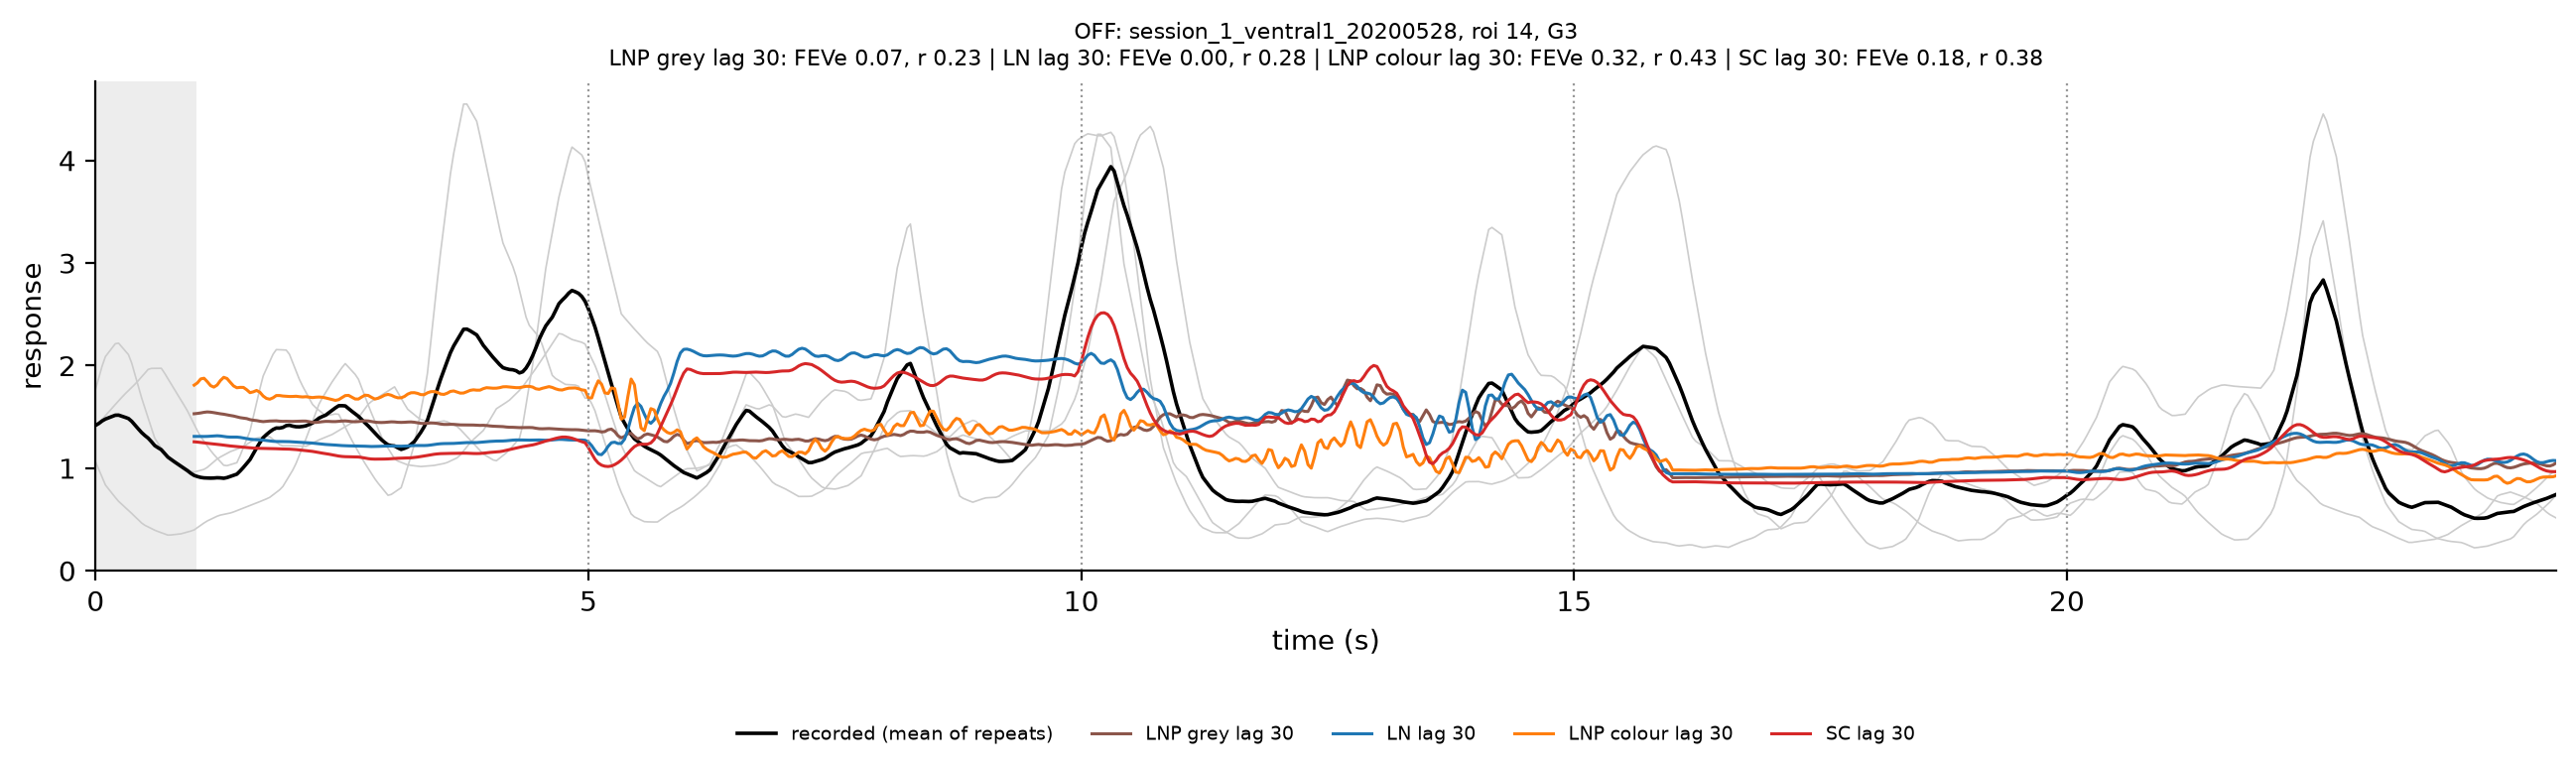

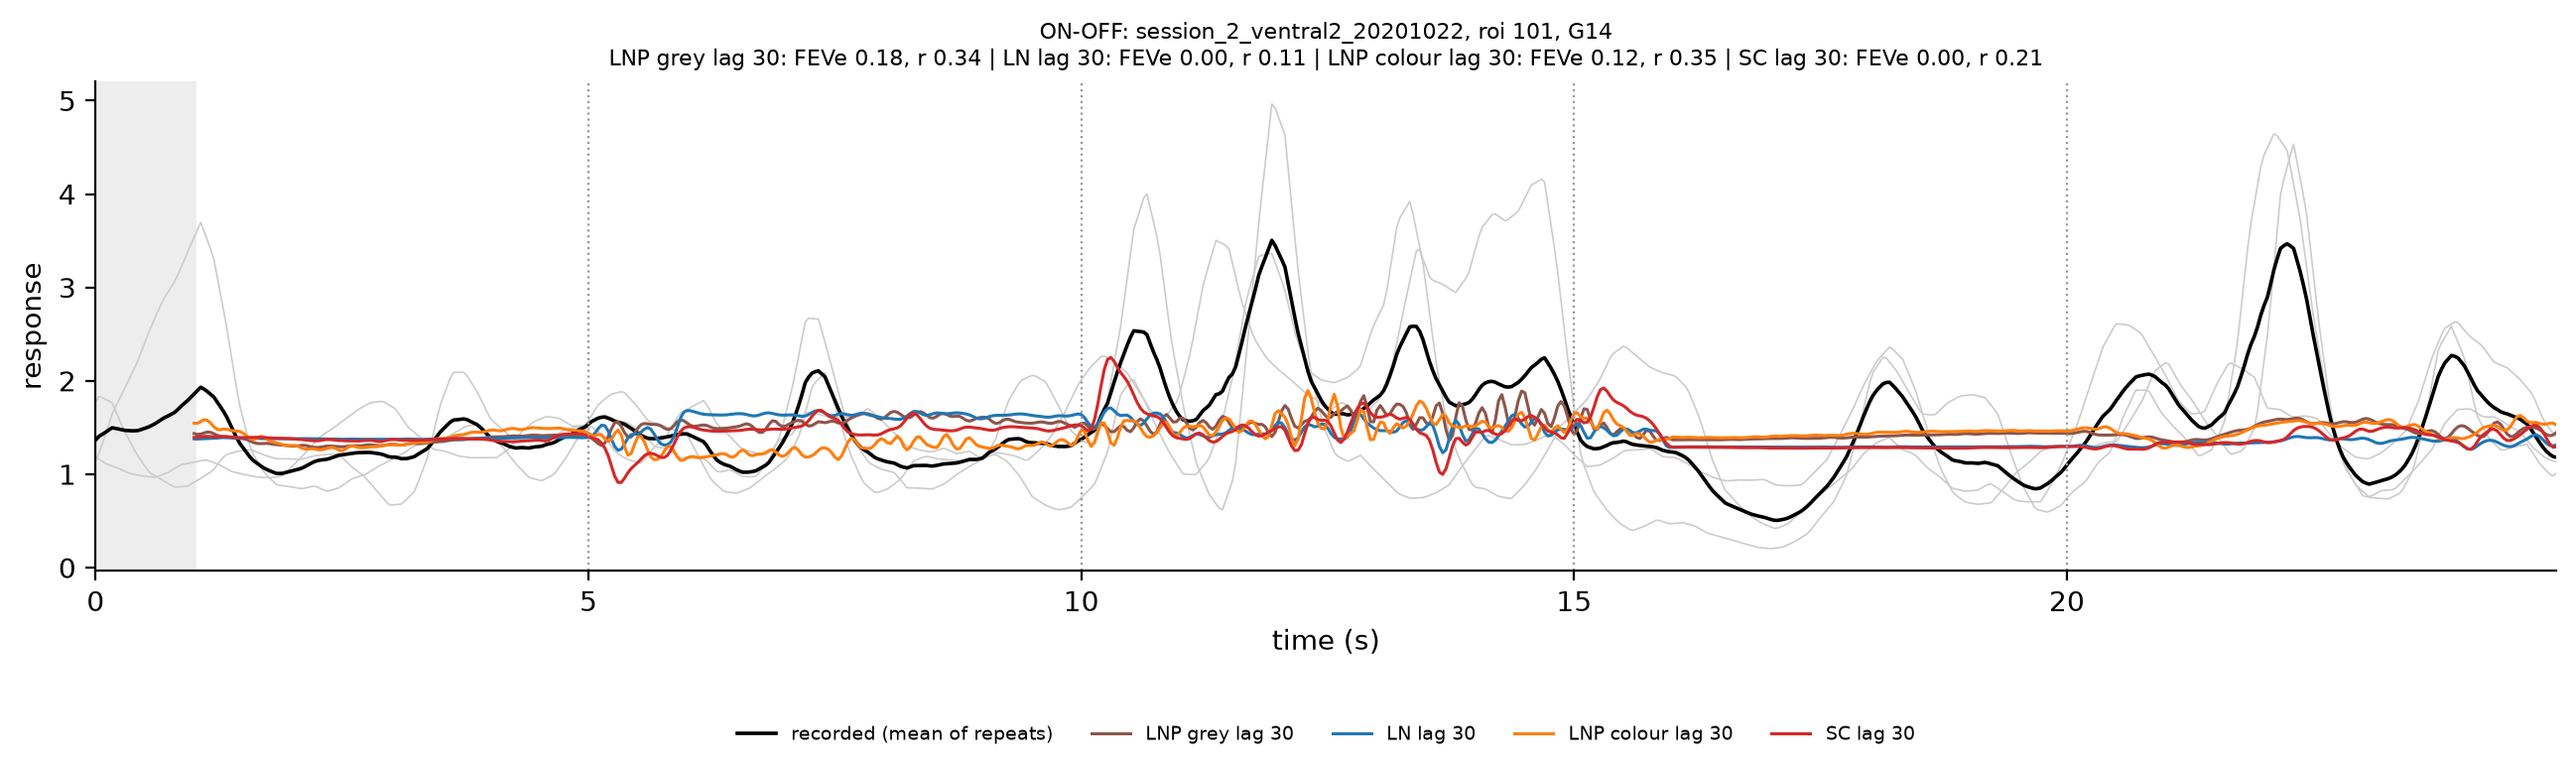

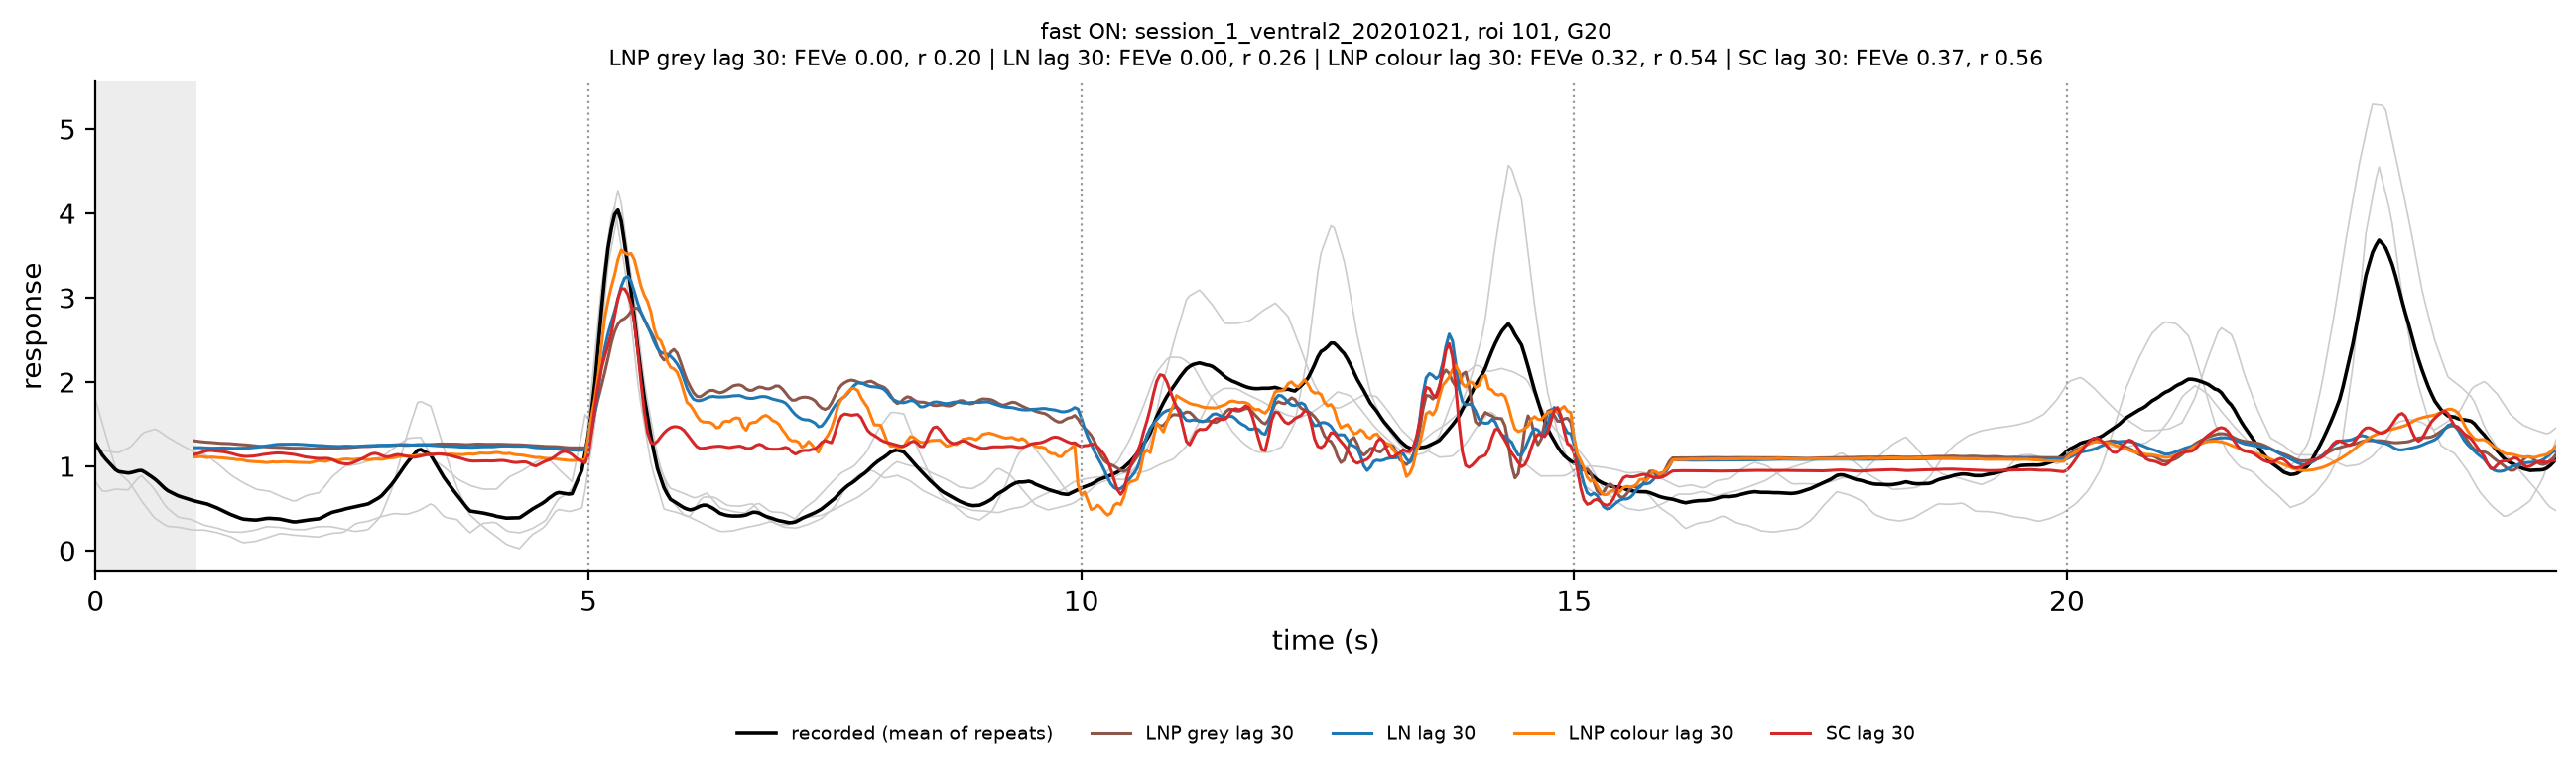

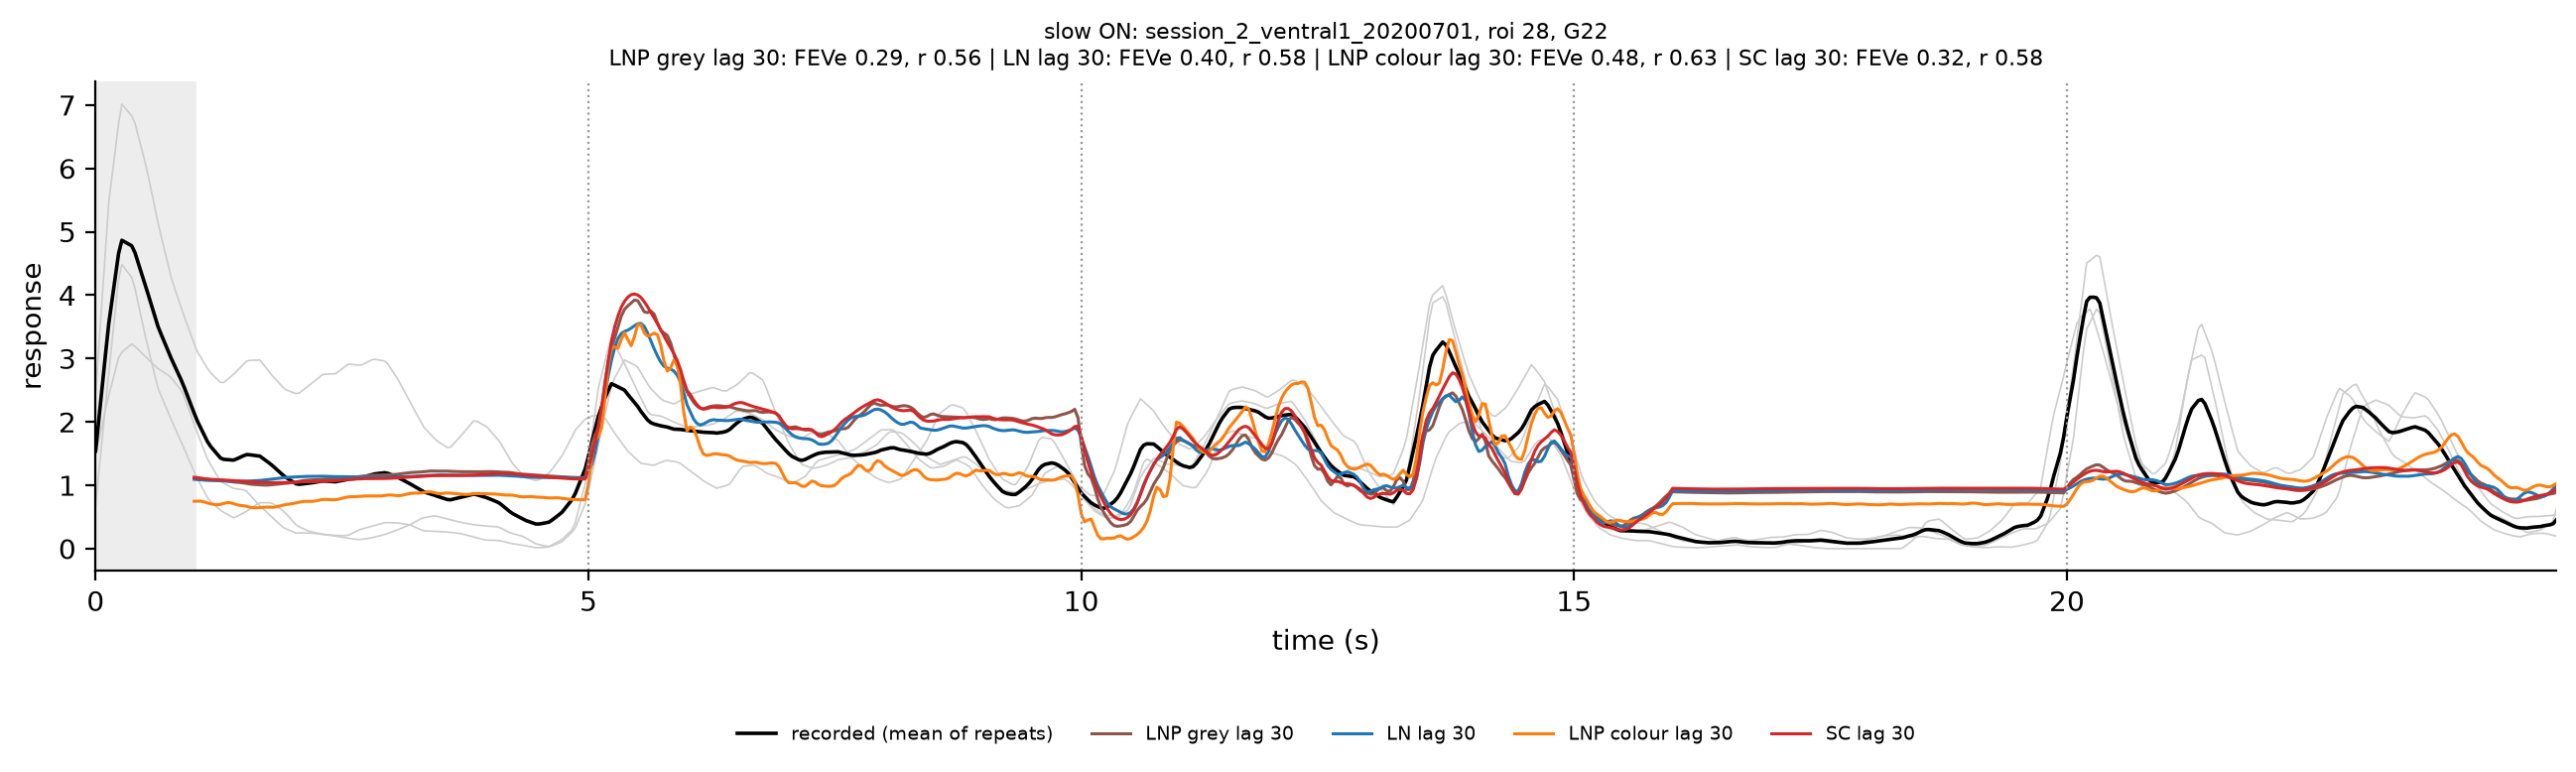

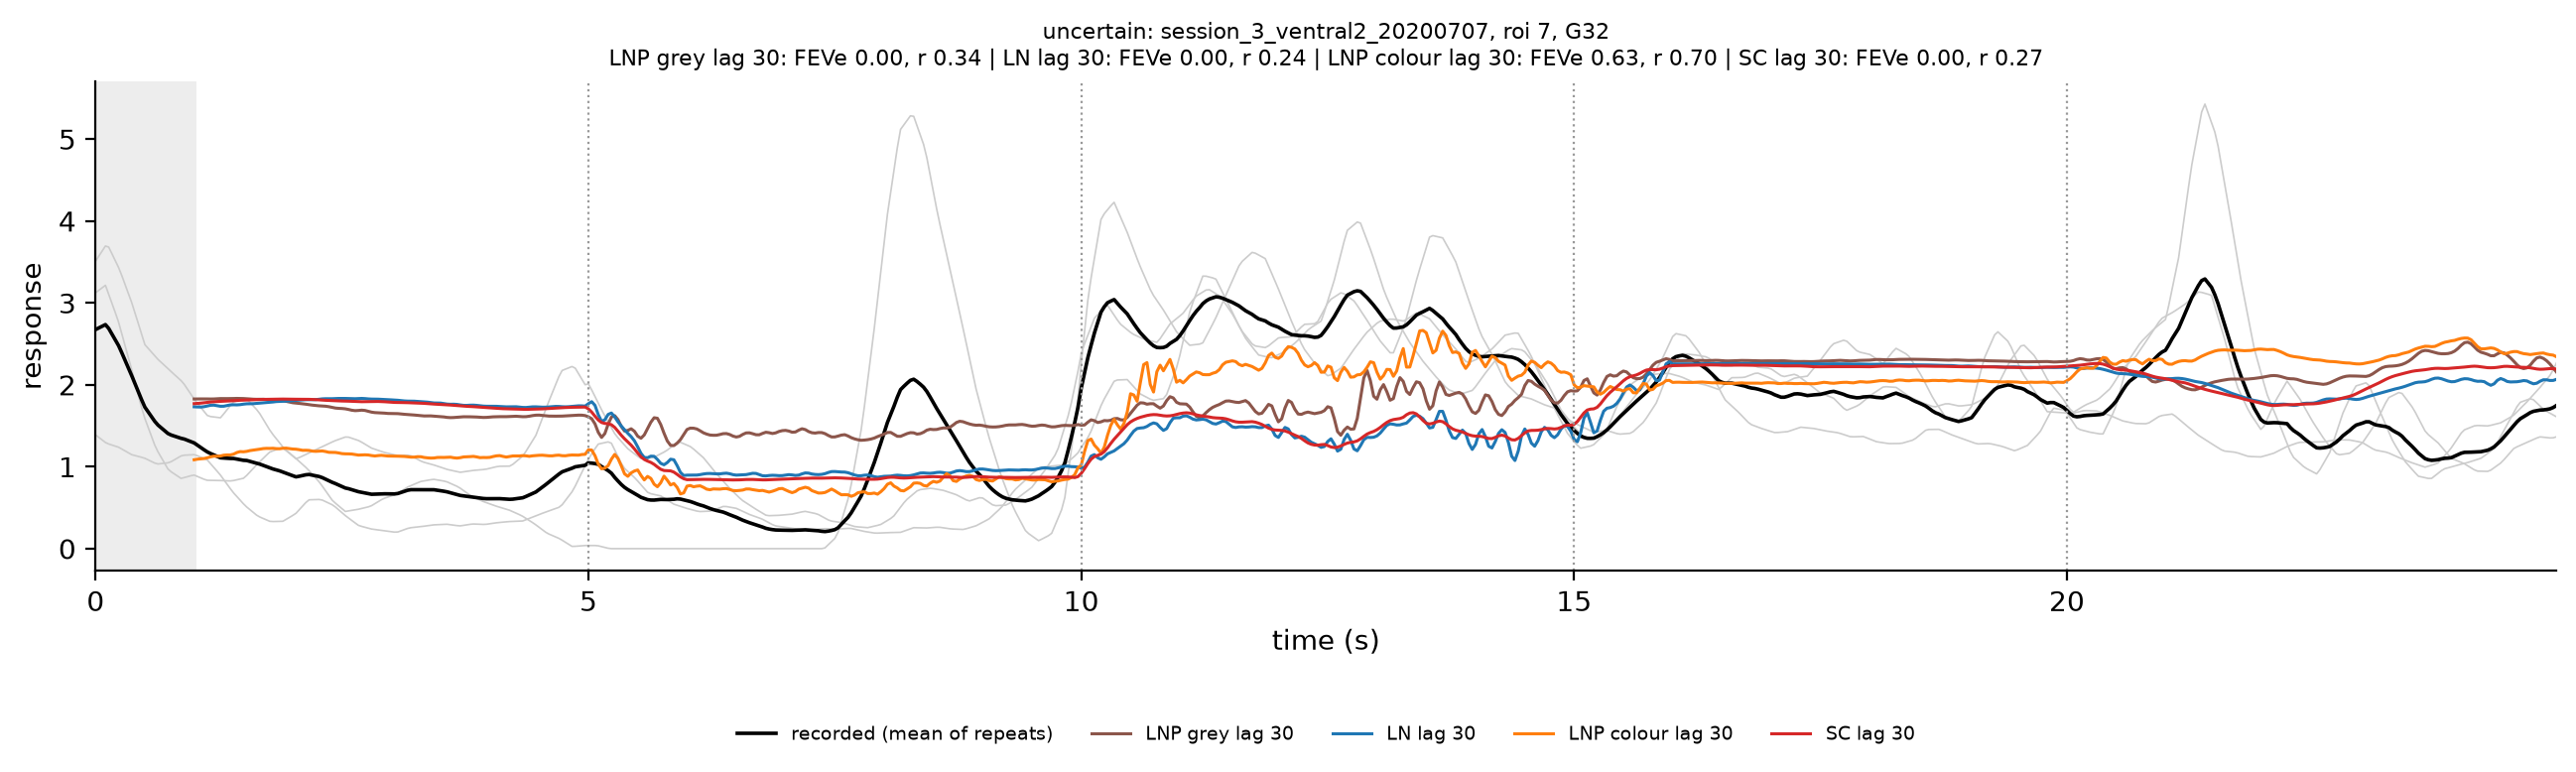

In [9]:
def plot_cell_predictions(session: str, neuron: int, model_labels: list[str], ax: plt.Axes | None = None) -> plt.Figure:
    if ax is None:
        _, ax = plt.subplots(figsize=(16, 3.2))
    by_trial = final_responses[session].test_by_trial[neuron]  # (time, trials)
    time_s = np.arange(by_trial.shape[0]) / FRAME_RATE_HZ
    ax.plot(time_s, by_trial, color="0.8", lw=0.6)
    ax.plot(time_s, by_trial.mean(axis=1), color="k", lw=1.3, label="recorded (mean of repeats)")

    scores = []
    for label in model_labels:
        prediction = predictions[label][session][:, neuron]
        lag = len(time_s) - len(prediction)
        ax.plot(time_s[lag:], prediction, color=PALETTE[label], lw=1.1, label=label)
        row = metrics[(metrics.model == label) & (metrics.session == session) & (metrics.neuron == neuron)].iloc[0]
        scores.append(f"{label}: FEVe {row.feve:.2f}, r {row.correlation:.2f}")
    ax.axvspan(0, lag / FRAME_RATE_HZ, color="0.93", zorder=0)
    for boundary in range(CLIP_LENGTH, by_trial.shape[0], CLIP_LENGTH):
        ax.axvline(boundary / FRAME_RATE_HZ, color="0.6", ls=":", lw=0.8)

    info = cell_info.loc[(session, neuron)]
    ax.set_title(f"{info.group_class}: {session}, roi {info.roi_id}, G{info.group}\n" + " | ".join(scores), fontsize=8)
    ax.set(xlabel="time (s)", ylabel="response", xlim=(0, time_s[-1]))
    # Below the axes, so it covers no trace
    ax.legend(fontsize=7, loc="upper center", bbox_to_anchor=(0.5, -0.28), ncols=len(model_labels) + 1, frameon=False)
    sns.despine(ax=ax)
    return ax.figure


for session, neuron in example_cells:
    plot_cell_predictions(session, neuron, TABLE)
    plt.show()

In [10]:
def export_all_predictions(directory: str | Path, model_labels: list[str], file_format: str = "png") -> None:
    # One figure per cell, named <session>_roi<roi id>_G<group>.<format>
    directory = Path(directory)
    directory.mkdir(parents=True, exist_ok=True)
    for session, neuron in cell_info.index:
        figure = plot_cell_predictions(session, neuron, model_labels)
        info = cell_info.loc[(session, neuron)]
        figure.savefig(
            directory / f"{session}_roi{info.roi_id}_G{info.group}.{file_format}", bbox_inches="tight", dpi=150
        )
        plt.close(figure)
    print(f"saved {len(cell_info)} figures to {directory}")


if TRACE_EXPORT_DIR is not None:
    export_all_predictions(TRACE_EXPORT_DIR, TABLE, TRACE_EXPORT_FORMAT)

# Performance by cell type

Mean FEVe and test correlation of the Table 2 models per functional type, over the reliable cells (error bars: standard
error over cells).

feve                              \
model       reliable cells LNP grey lag 30 LN lag 30 LNP colour lag 30   
group_class                                                              
OFF                    266           0.099     0.104             0.203   
ON-OFF                 327           0.070     0.056             0.103   
fast ON                466           0.156     0.194             0.223   
slow ON                811           0.308     0.306             0.319   
uncertain              538           0.187     0.203             0.245   

                          correlation                                        
model       SC lag 30 LNP grey lag 30 LN lag 30 LNP colour lag 30 SC lag 30  
group_class                                                                  
OFF             0.236           0.272     0.287             0.373     0.420  
ON-OFF          0.136           0.207     0.204             0.262     0.308  
fast ON         0.288           0.302     0.370             0.380     0.447  
slow ON         0.386           0.523     0.538             0.581     0.571  
uncertain       0.259           0.339     0.364             0.420     0.417

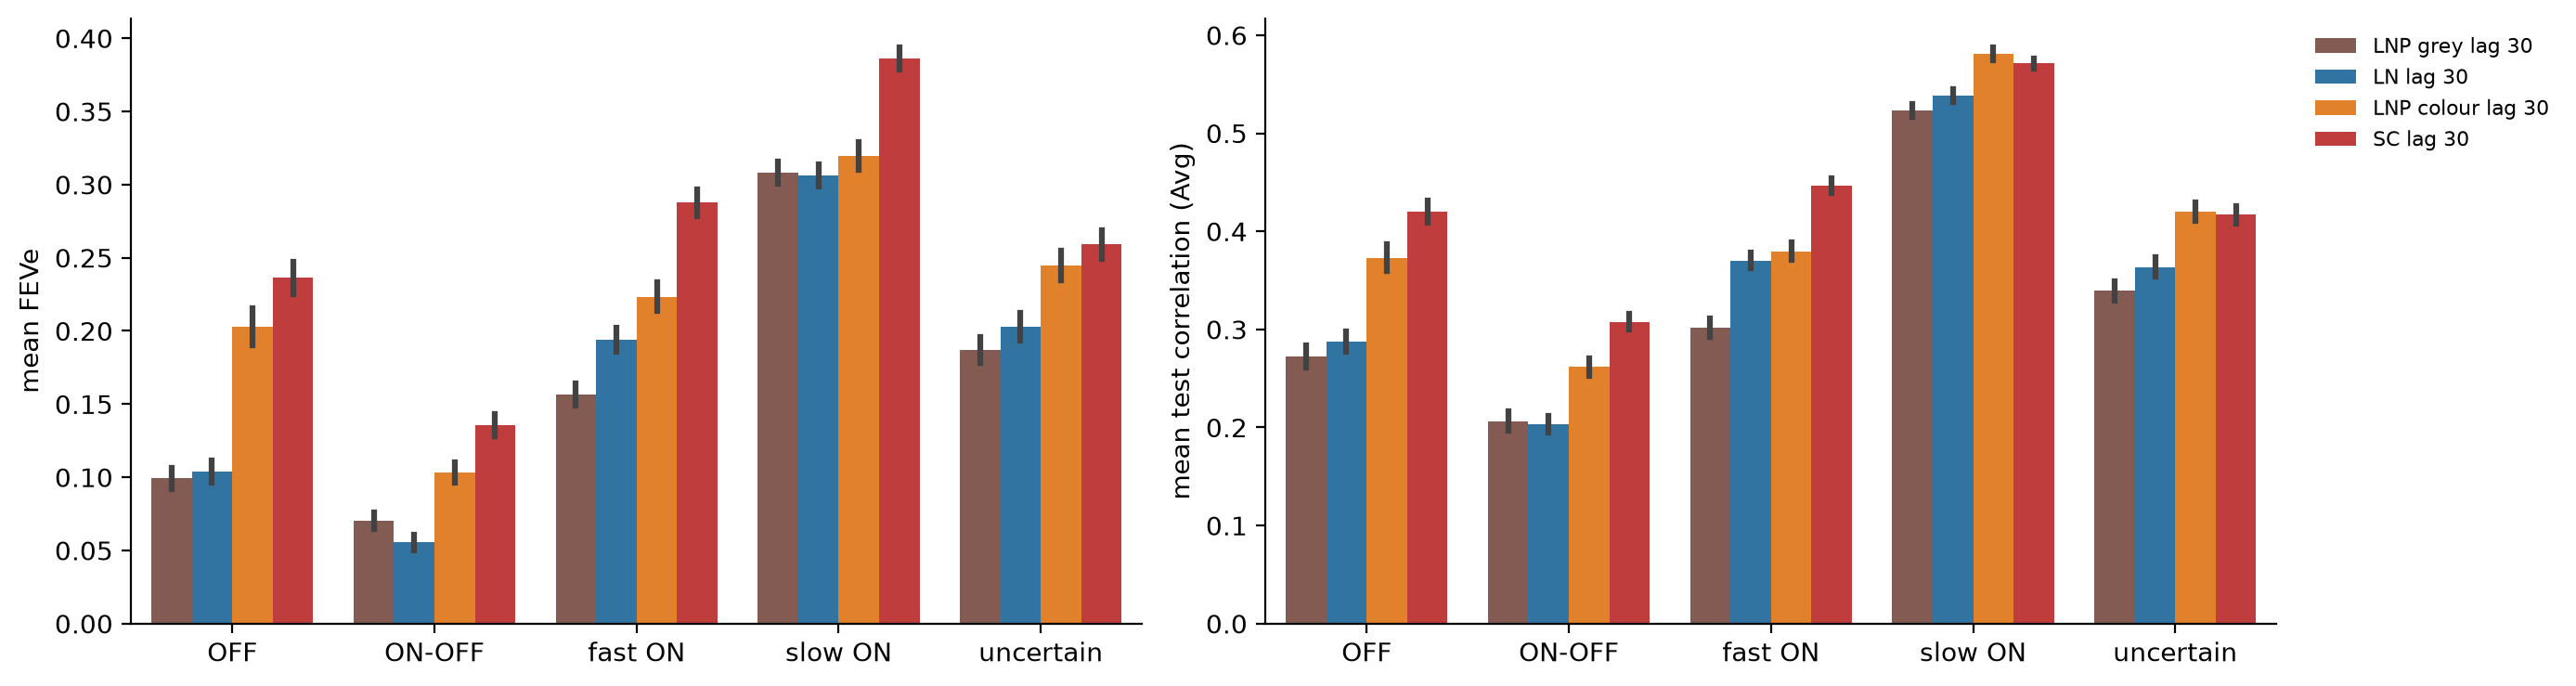

In [11]:
table_reliable = metrics[metrics["reliable"] & metrics["model"].isin(TABLE)]
fig, axes = plt.subplots(ncols=2, figsize=(14, 3.8))
for ax, (value, name) in zip(axes, [("feve", "FEVe"), ("correlation", "test correlation (Avg)")]):
    sns.barplot(
        data=table_reliable,
        x="group_class",
        y=value,
        hue="model",
        hue_order=TABLE,
        palette=PALETTE,
        errorbar="se",
        ax=ax,
        legend=ax is axes[-1],
    )
    ax.set(xlabel="", ylabel=f"mean {name}")
sns.move_legend(axes[-1], "upper left", bbox_to_anchor=(1.02, 1), fontsize=8, title=None, frameon=False)
sns.despine(fig=fig)
fig.tight_layout()

by_type = table_reliable.pivot_table(
    index="group_class", columns="model", values=["feve", "correlation"], aggfunc="mean", observed=True
)[[(value, model) for value in ["feve", "correlation"] for model in TABLE]]
by_type.insert(
    0,
    ("", "reliable cells"),
    table_reliable.drop_duplicates(["session", "neuron"]).groupby("group_class", observed=True).size(),
)
by_type.round(3)

**By cell type.** Slow ON cells are predicted best by every model, ON-OFF cells worst. SC has the highest FEVe in every
type. Its lead over the colour LNP is:
- 0.03 in the OFF and ON-OFF cells;
- 0.07 in the fast ON and slow ON cells;
- 0.01 in the uncertain cells.

In correlation, the colour LNP and SC are equal in the slow ON and uncertain cells (0.581 vs 0.571, 0.420 vs 0.417).
There, SC's advantage lies in what FEVe measures and correlation ignores, the scale and offset of the prediction.
Colour helps the LNP most in the OFF cells: FEVe 0.203 against 0.099 for grey.

# Filters

## Colour LNP

The example cells' filters in the colour LNP, with a spatial filter and a temporal kernel per channel, next to the grey
LNP's (whose core averages green and UV). Both channels share one colour scale; each channel's polarity is in its
temporal kernel.

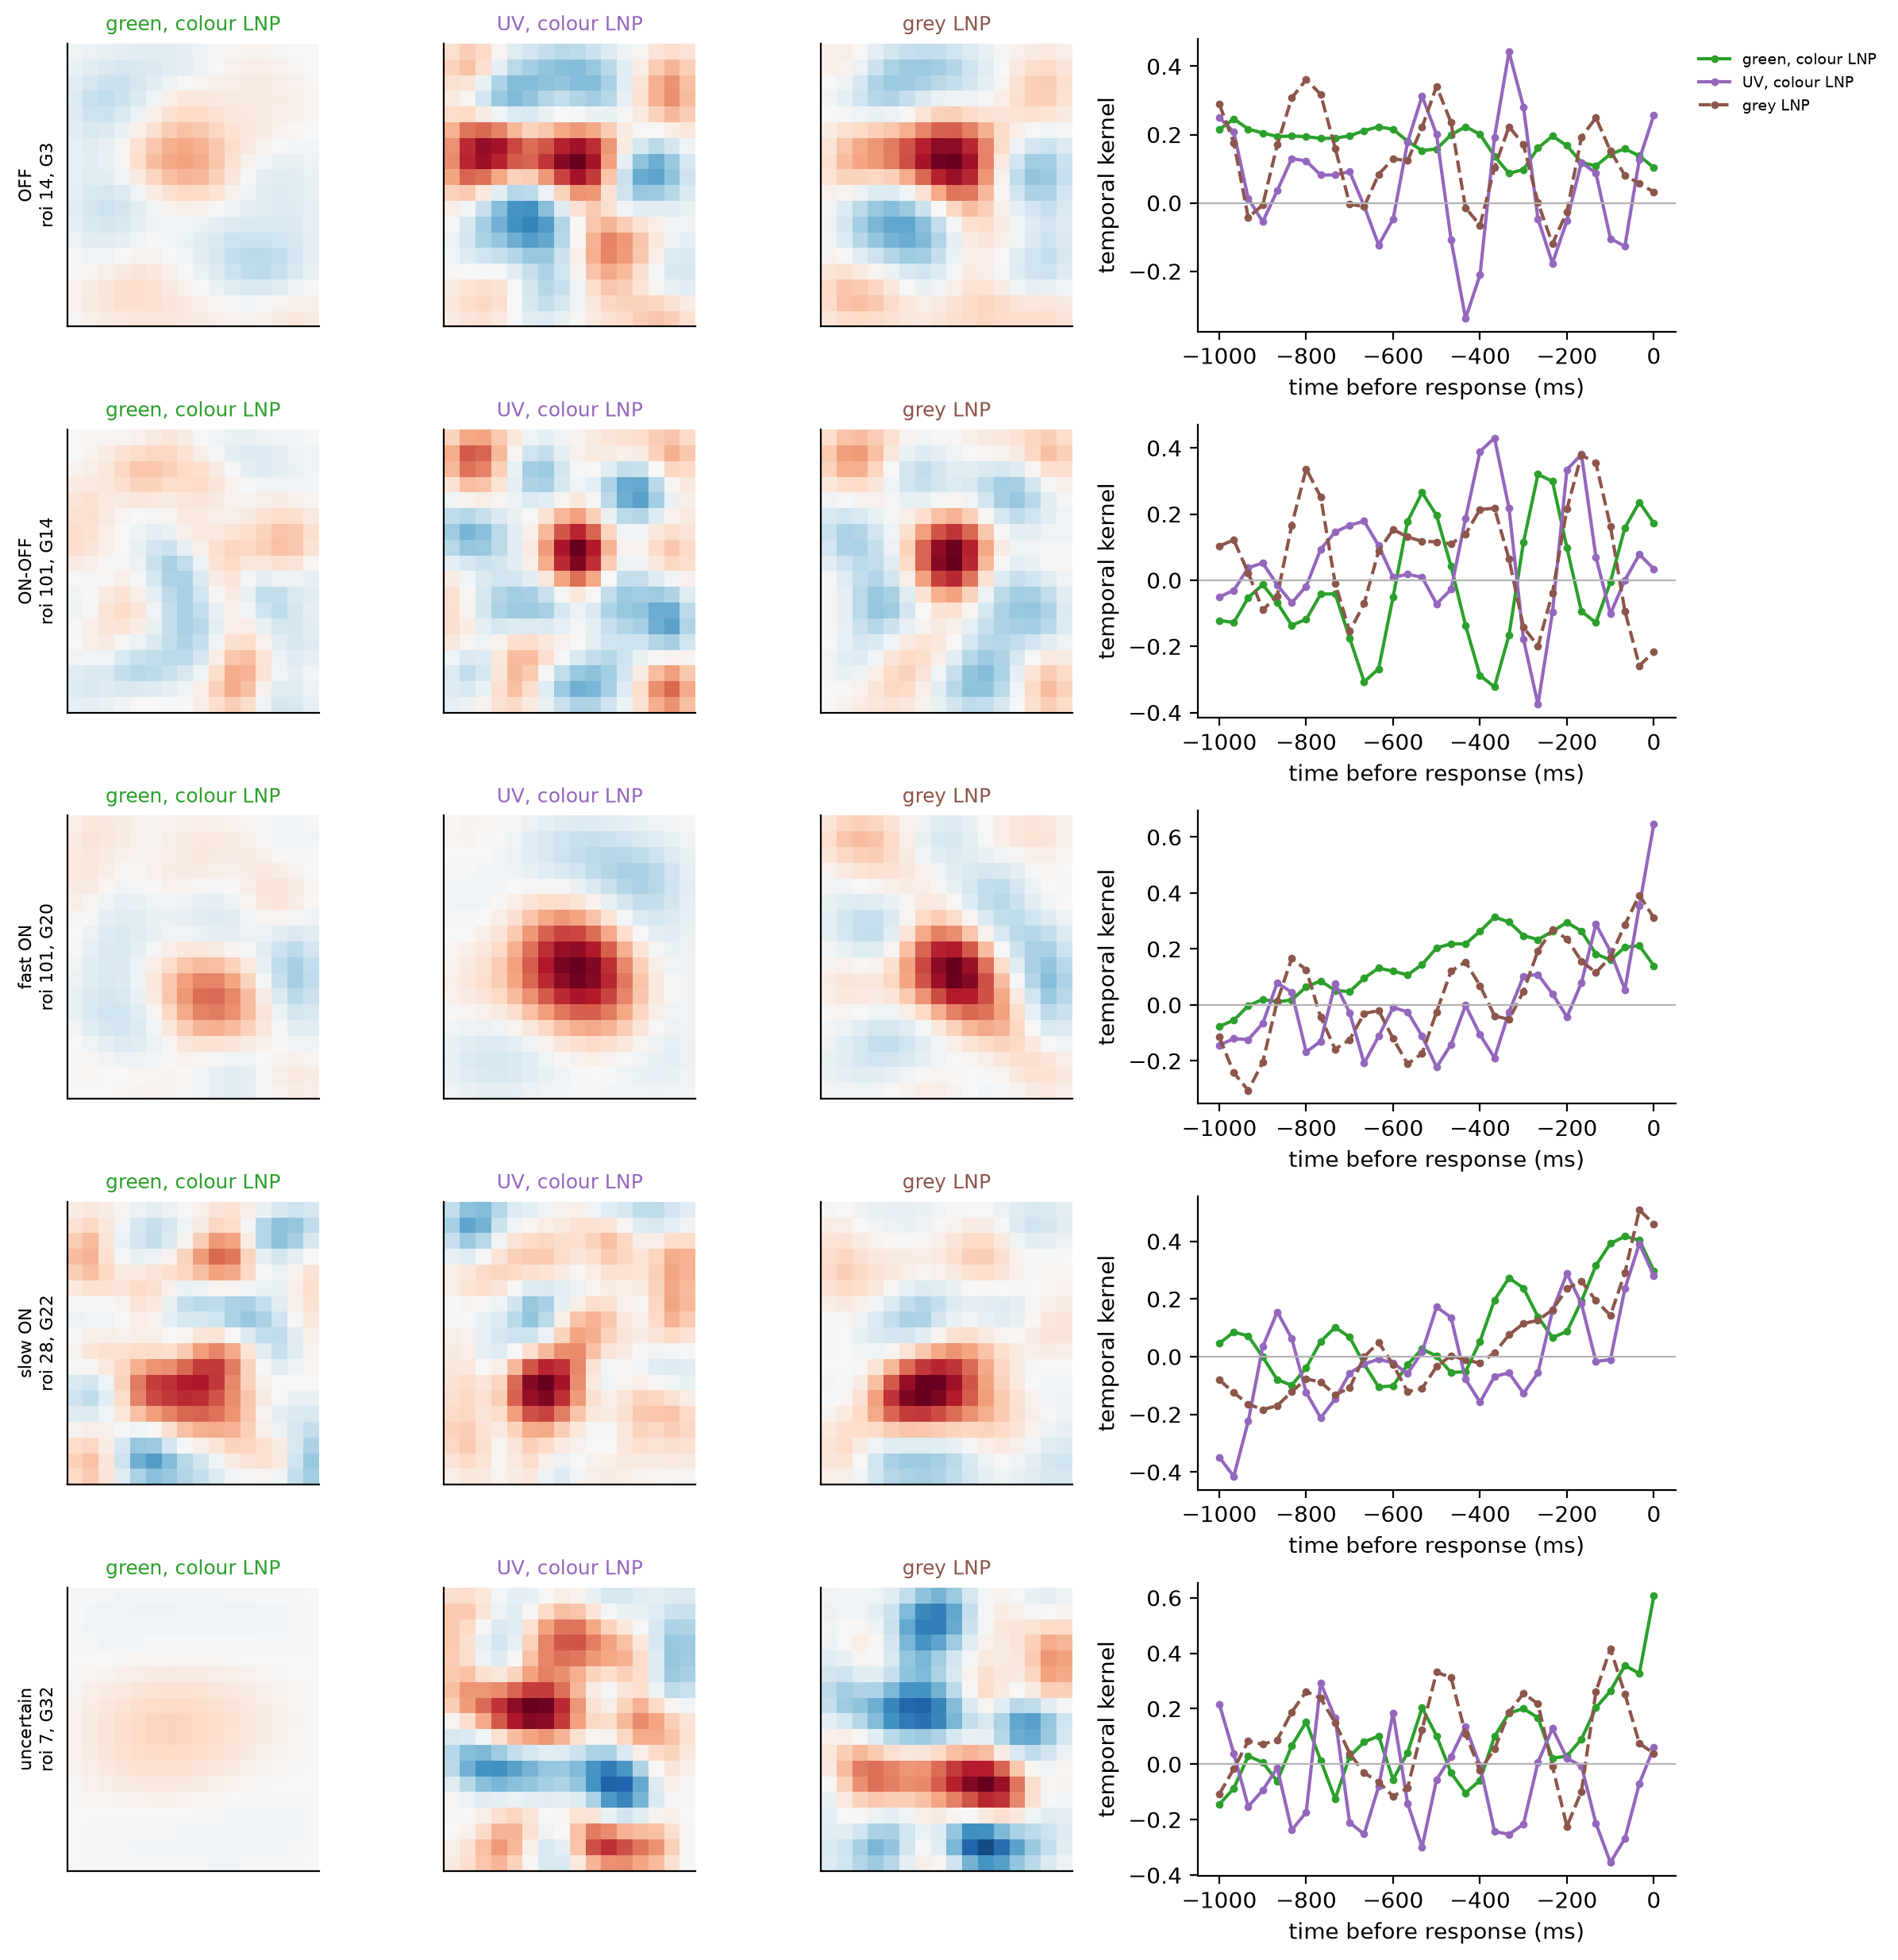

In [12]:
colour_label, grey_label = "LNP colour lag 30", "LNP grey lag 30"
fig, axes = plt.subplots(
    nrows=len(example_cells),
    ncols=4,
    figsize=(12, 2.5 * len(example_cells)),
    gridspec_kw={"width_ratios": [1, 1, 1, 1.9]},
    squeeze=False,
)
for row_axes, (session, neuron) in zip(axes, example_cells):
    colour_spatial, colour_temporal = colour_filter_factors(models[colour_label].readout[session], neuron)
    grey_spatial, grey_temporal = neuron_filters(grey_label, session, neuron)
    limit = np.abs(colour_spatial).max() or 1.0
    maps = [(f"{c}, colour LNP", m, limit, colour) for (c, colour), m in zip(CHANNELS.items(), colour_spatial)]
    maps.append(("grey LNP", grey_spatial, np.abs(grey_spatial).max() or 1.0, PALETTE[grey_label]))
    for ax, (title, spatial, map_limit, colour) in zip(row_axes, maps):
        ax.imshow(spatial, cmap="RdBu_r", vmin=-map_limit, vmax=map_limit, interpolation="none")
        clean_map(ax)
        ax.set_title(title, fontsize=9, color=colour)
    ax_time = row_axes[-1]
    for (channel, colour), kernel in zip(CHANNELS.items(), colour_temporal):
        ax_time.plot(lags_ms(len(kernel)), kernel, marker="o", ms=2.5, color=colour, label=f"{channel}, colour LNP")
    ax_time.plot(
        lags_ms(len(grey_temporal)),
        grey_temporal,
        ls="--",
        marker="o",
        ms=2.5,
        color=PALETTE[grey_label],
        label="grey LNP",
    )
    ax_time.axhline(0, color="0.7", lw=0.8)
    ax_time.set(xlabel="time before response (ms)", ylabel="temporal kernel")
    info = cell_info.loc[(session, neuron)]
    row_axes[0].set_ylabel(f"{info.group_class}\nroi {info.roi_id}, G{info.group}", fontsize=8)
axes[0, -1].legend(fontsize=7, loc="upper left", bbox_to_anchor=(1.02, 1), frameon=False)
sns.despine(fig=fig)
fig.tight_layout()

## Grey models

The same cells in the grey LNP and the LN and SC models. The LN and SC spatial filters are the masked Gaussians the
models use.

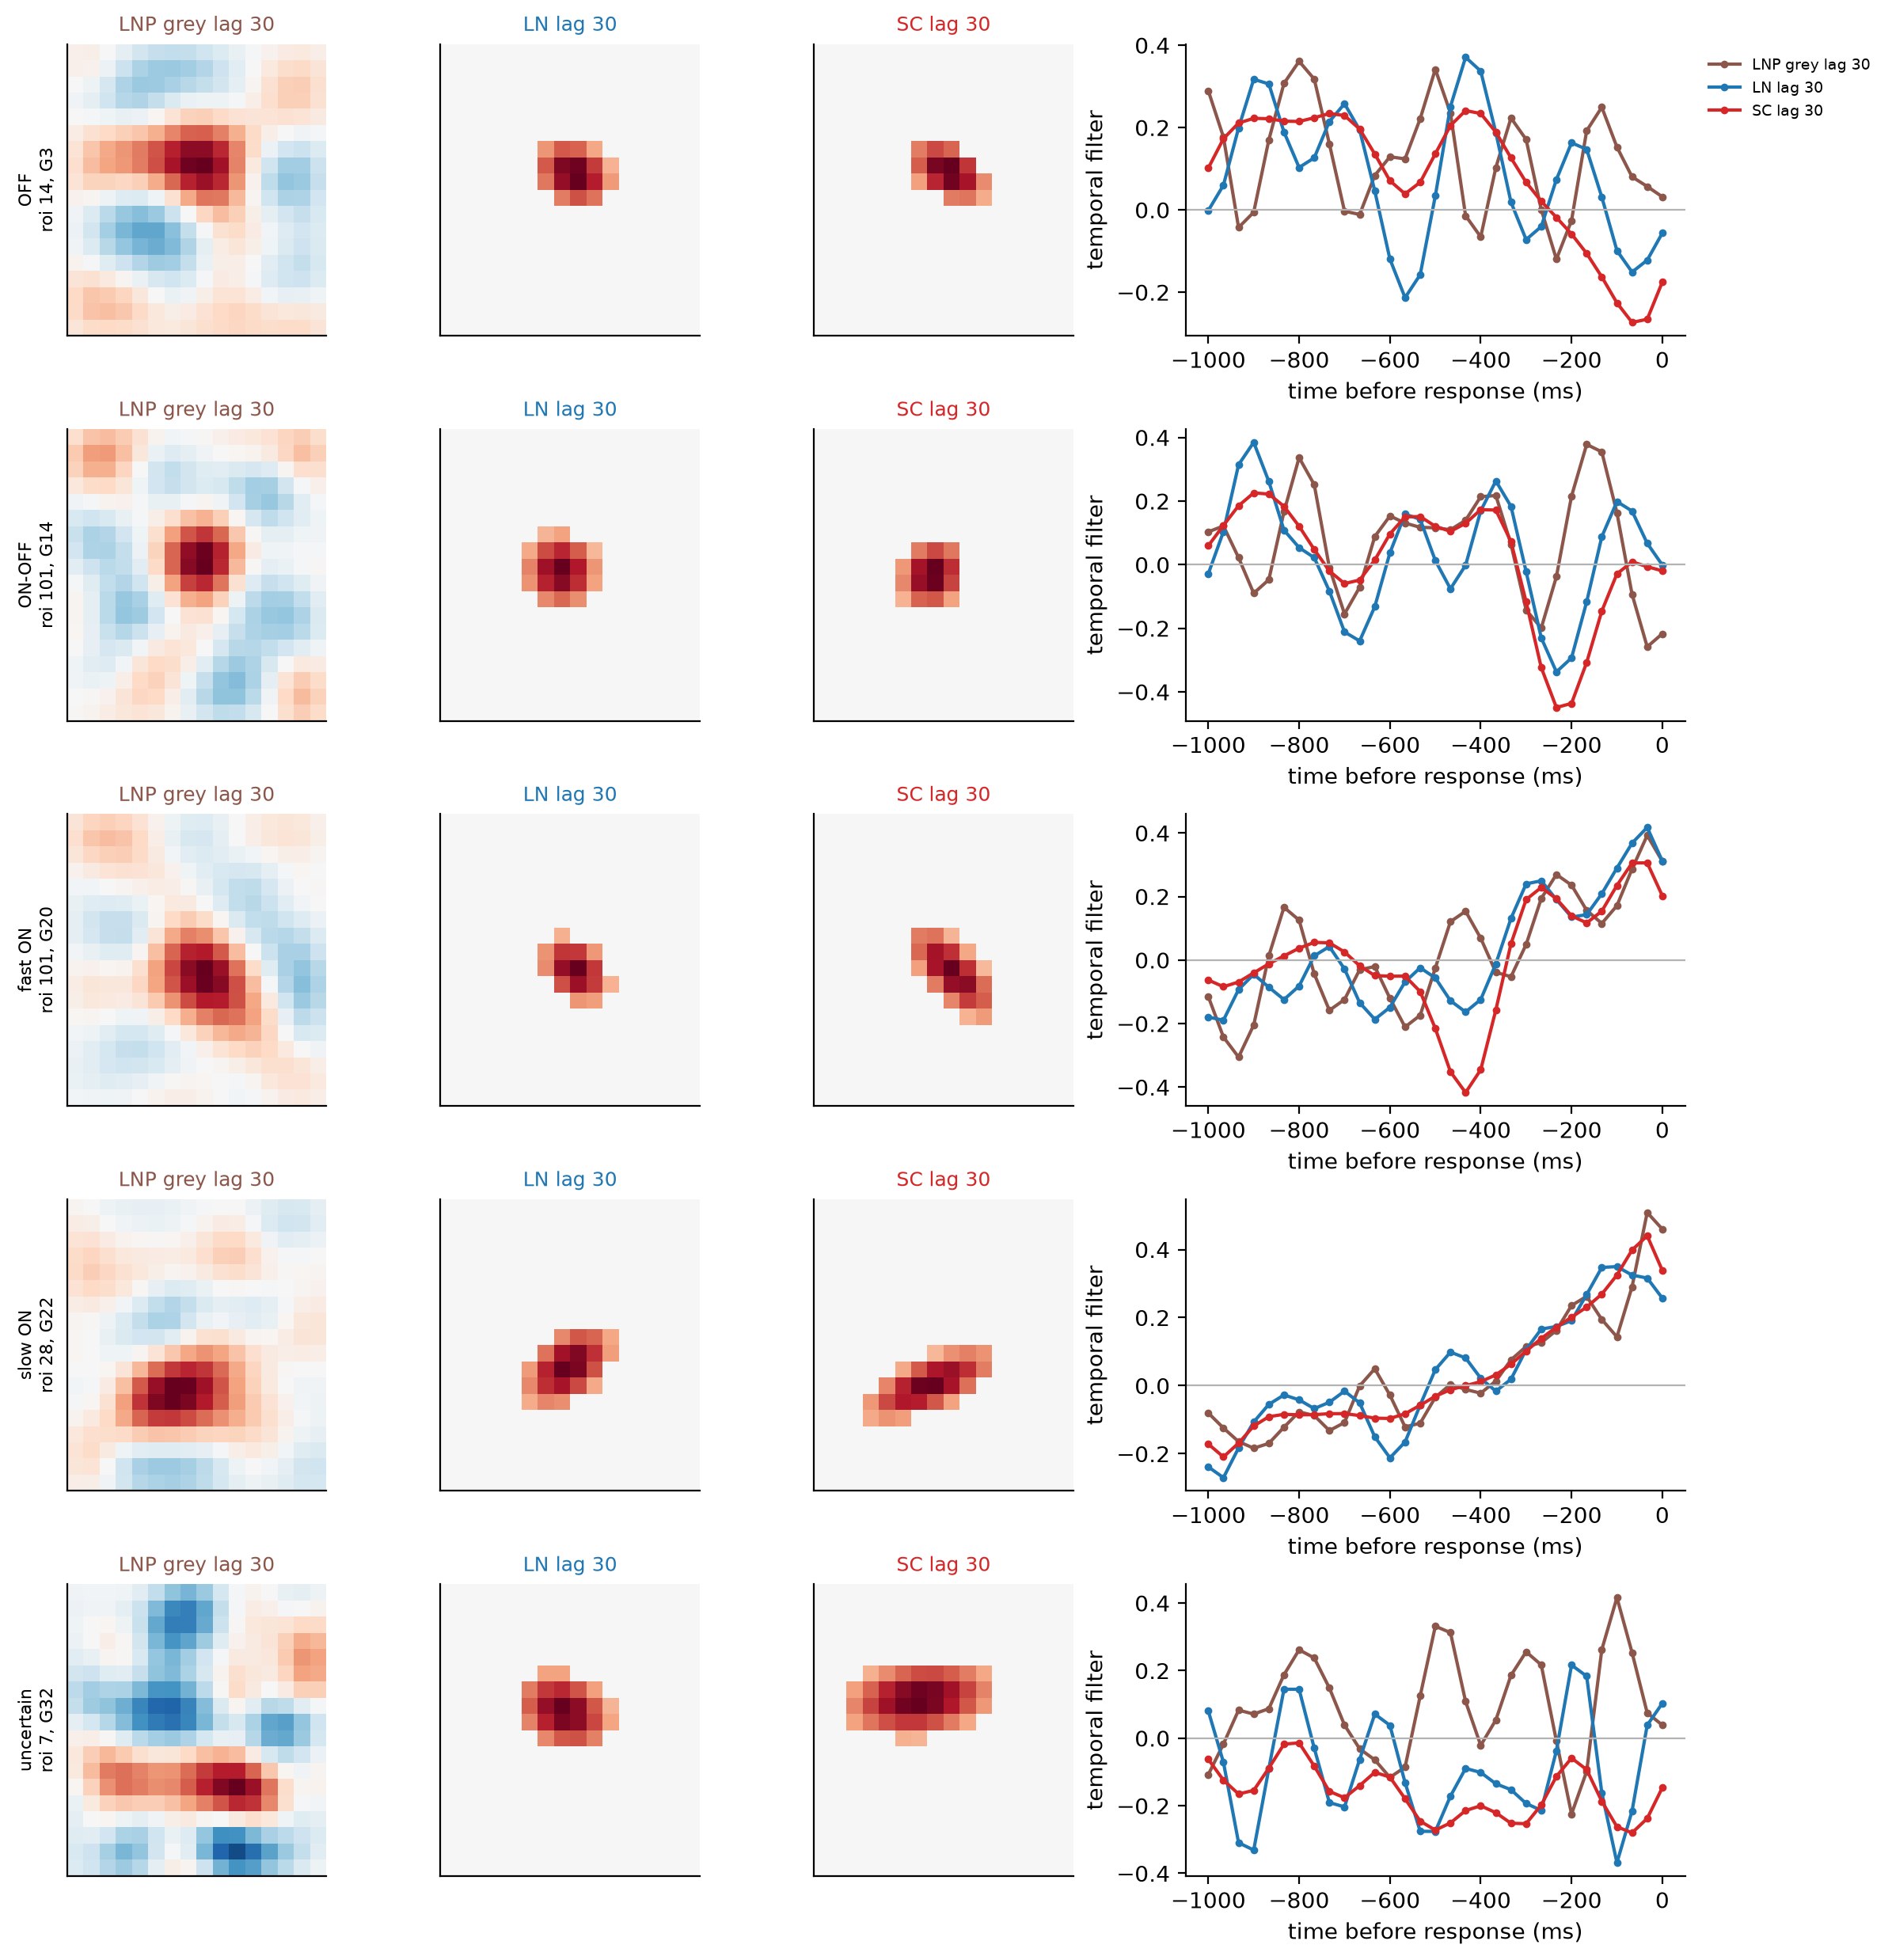

In [13]:
grey_models = ["LNP grey lag 30", "LN lag 30", "SC lag 30"]
fig, axes = plt.subplots(
    nrows=len(example_cells),
    ncols=len(grey_models) + 1,
    figsize=(12, 2.5 * len(example_cells)),
    gridspec_kw={"width_ratios": [1] * len(grey_models) + [1.9]},
    squeeze=False,
)
for row_axes, (session, neuron) in zip(axes, example_cells):
    for ax, label in zip(row_axes, grey_models):
        spatial, temporal = neuron_filters(label, session, neuron)
        limit = np.abs(spatial).max() or 1.0
        ax.imshow(spatial, cmap="RdBu_r", vmin=-limit, vmax=limit, interpolation="none")
        clean_map(ax)
        ax.set_title(label, fontsize=9, color=PALETTE[label])
        row_axes[-1].plot(lags_ms(len(temporal)), temporal, marker="o", ms=2.5, color=PALETTE[label], label=label)
    row_axes[-1].axhline(0, color="0.7", lw=0.8)
    row_axes[-1].set(xlabel="time before response (ms)", ylabel="temporal filter")
    info = cell_info.loc[(session, neuron)]
    row_axes[0].set_ylabel(f"{info.group_class}\nroi {info.roi_id}, G{info.group}", fontsize=8)
axes[0, -1].legend(fontsize=7, loc="upper left", bbox_to_anchor=(1.02, 1), frameon=False)
sns.despine(fig=fig)
fig.tight_layout()

## Mean temporal filter per cell type

The unit-norm temporal filters averaged over all cells of each type. Spatial filters are not averaged: the receptive
fields sit at different positions.

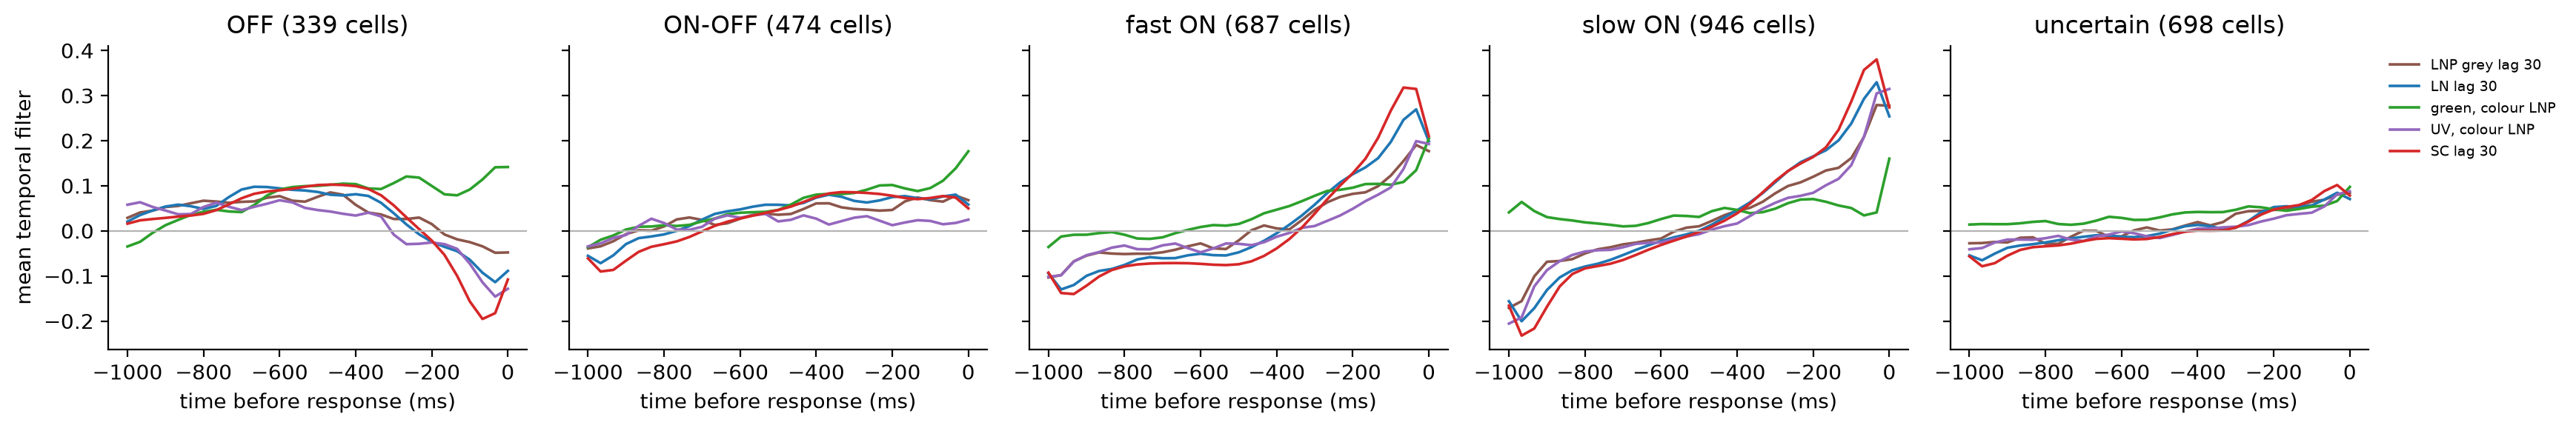

In [14]:
def plot_mean_temporal_filters(curves: dict[str, tuple[np.ndarray, dict]], title: str = "") -> plt.Figure:
    # curves: legend label -> (filters (neurons, T), line style); one panel per type, legend outside
    fig, axes = plt.subplots(ncols=len(GROUPS), figsize=(3.2 * len(GROUPS) + 1.5, 3), sharey=True)
    for ax, (group_class, mask) in zip(axes, type_masks().items()):
        for label, (filters, style) in curves.items():
            mean_filter = filters[mask].mean(axis=0)
            ax.plot(lags_ms(len(mean_filter)), mean_filter, lw=1.3, label=label, **style)
        ax.axhline(0, color="0.7", lw=0.8)
        ax.set(title=f"{group_class} ({mask.sum()} cells)", xlabel="time before response (ms)")
    axes[0].set_ylabel("mean temporal filter")
    axes[-1].legend(fontsize=7, loc="upper left", bbox_to_anchor=(1.02, 1), frameon=False)
    if title:
        fig.suptitle(title, fontsize=10)
    sns.despine(fig=fig)
    fig.tight_layout()
    return fig


colour_temporal = all_temporal_filters("LNP colour lag 30")
curves = {label: (all_temporal_filters(label), {"color": PALETTE[label]}) for label in ["LNP grey lag 30", "LN lag 30"]}
curves |= {
    f"{channel}, colour LNP": (colour_temporal[:, i], {"color": colour})
    for i, (channel, colour) in enumerate(CHANNELS.items())
}
curves["SC lag 30"] = (all_temporal_filters("SC lag 30"), {"color": PALETTE["SC lag 30"]})
plot_mean_temporal_filters(curves);

**Filters.** In four of the five example cells, the LN and SC Gaussians sit on the centre of the LNPs' receptive
field. In the uncertain cell they stay near the centre of the stimulus, above the LNPs' receptive field. The Gaussians
start at the centre and get gradient only from the pixels inside their 1.5 sigma mask, so a receptive field far from
the centre is hard for them to reach. The colour LNP's green filters are weaker and broader than its UV
filters. Its green temporal kernels also differ from the UV ones in the type means: in OFF and slow ON cells the green
mean stays positive.

In the type means, the grey models agree closely:
- **ON types:** the filter rises towards the newest frames, with a negative lobe about a second back.
- **OFF type:** it falls towards the newest frames, with a positive lobe 400-800 ms back.
- **ON-OFF and uncertain types:** the mean is nearly flat, as their cells' polarities differ.

SC's filters are the most pronounced, especially in the OFF and fast ON cells.

# The contrast weight `w`

`w` scales the local spatial contrast inside the receptive field against its weighted mean intensity: `w > 0` means
contrast drives the cell beyond what its mean input explains. Left: `w` of the SC model per functional type (reliable
cells; boxes without outliers). Right: how much the contrast term improves the prediction in each type, as the paired
difference SC - LN in FEVe with its 95% confidence interval (resampling sessions).

,cells,median,fraction_positive,"SC - LN FEVe, mean","SC - LN FEVe, low","SC - LN FEVe, high"
group_class,,,,,,
OFF,266,1.517,0.996,0.132,0.116,0.149
ON-OFF,327,1.382,0.994,0.080,0.064,0.098
fast ON,466,0.804,0.946,0.094,0.081,0.108
slow ON,811,0.574,0.894,0.080,0.070,0.090
uncertain,538,0.773,0.909,0.056,0.045,0.067


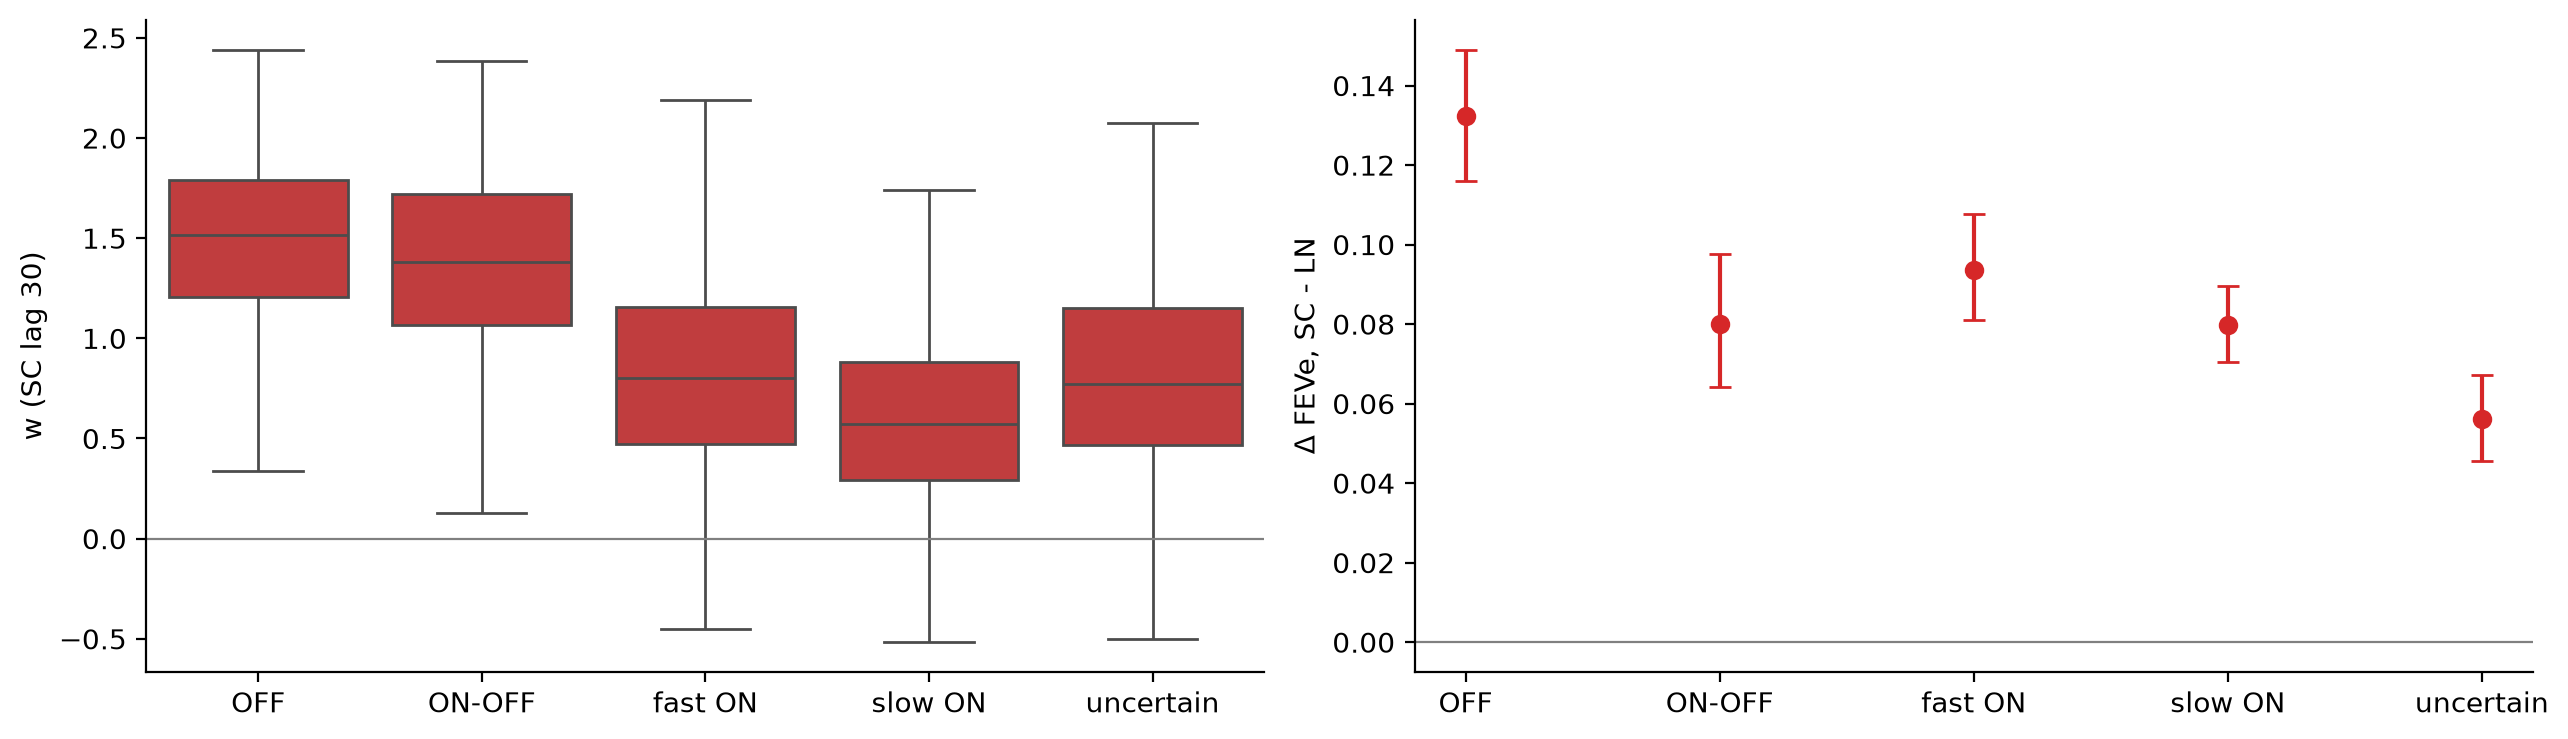

In [15]:
sc_label, ln_label = "SC lag 30", "LN lag 30"
w = np.concatenate(
    [(models[sc_label].readout[s].w.detach() * gain_sign(models[sc_label].readout[s])).cpu().numpy() for s in sessions]
)
w_cells = cell_info.reset_index()[["session", "neuron", "group_class", "reliable"]].assign(w=w)
w_reliable = w_cells[w_cells["reliable"]]
gain = per_type_difference(ln_label, sc_label)

fig, axes = plt.subplots(ncols=2, figsize=(13, 3.8))
sns.boxplot(data=w_reliable, x="group_class", y="w", color=PALETTE[sc_label], showfliers=False, ax=axes[0])
axes[0].axhline(0, color="0.5", lw=0.8)
axes[0].set(xlabel="", ylabel="w (SC lag 30)")
x = np.arange(len(gain))
axes[1].errorbar(
    x,
    gain["mean"],
    yerr=[gain["mean"] - gain["low"], gain["high"] - gain["mean"]],
    fmt="o",
    color=PALETTE[sc_label],
    capsize=4,
)
axes[1].axhline(0, color="0.5", lw=0.8)
axes[1].set_xticks(x, gain.index)
axes[1].set(ylabel="Δ FEVe, SC - LN")
sns.despine(fig=fig)
fig.tight_layout()

w_summary = w_reliable.groupby("group_class", observed=True)["w"].agg(
    cells="size", median="median", fraction_positive=lambda values: (values > 0).mean()
)
w_summary.join(gain.rename(columns=lambda c: f"SC - LN FEVe, {c}")).round(3)

**w.** The contrast weight is positive in 89-99% of the reliable cells of every type. It is largest in the OFF
(median 1.52) and ON-OFF cells (1.38), and smallest in the slow ON cells (0.57).

The gain of SC over LN in FEVe is also largest in the OFF cells, but otherwise it does not follow `w`:
- OFF: +0.132
- fast ON: +0.094
- ON-OFF: +0.080
- slow ON: +0.080
- uncertain: +0.056

The ON-OFF cells, with the second-largest `w`, gain no more than the slow ON cells, which have the smallest. In test
correlation the gain does follow the order of `w`: +0.133, +0.104, +0.077, +0.053 and +0.033 from OFF to slow ON.

# Effect of the seed

The LN and SC models of Table 2 retrained with five more seeds (1-5, `trainer.max_epochs=600`; "seed 42" is the Table 2
run). The seed sets the random temporal filter each cell starts from and the order of the training batches; the
Gaussians start at the centre whatever the seed. Statistics over seeds use seeds 1-5, which were trained together and
identically.

For each model, the five seeds' filters were also averaged cell by cell (`export_mean_sc_filters_as_stas`): the
unmasked Gaussians, each with unit peak, and the unit-norm temporal filters, each with the sign of `nl_b`. A
frozen-filter model on the averaged filters (**mean filter**) then refits only `w`, `a`, `b`, `c` per cell, selected
on validation loss; its spatial filter is a Gaussian fitted to the mean and masked at 1.5 sigma.

In [16]:
seed_models: dict[tuple[str, str], object] = {}
seed_parts: list[pd.DataFrame] = []
SEED_NAMES = [f"seed {s}" for s in SEEDS]


def load_seed_runs(name: str, mean_filter: bool = True) -> None:
    # Seeds 1-5 (and the mean-filter model) of one model, plus seed 42 from `models`, evaluated into `seed_parts`
    runs = {f"seed {s}": f"seed{s}" for s in SEEDS} | ({"mean filter": "mean_filter"} if mean_filter else {})
    for run, directory in runs.items():
        model = load_model("sc", SEED_RUNS / SEED_DIRECTORIES[name] / directory)
        if model is None:
            continue
        seed_models[(name, run)] = model
        cells, _ = test_metrics(model)
        seed_parts.append(cells.assign(name=name, run=run))
    if name in models:
        seed_models[(name, "seed 42")] = models[name]
        seed_parts.append(metrics[metrics["model"] == name].assign(name=name, run="seed 42"))


def seed_cells() -> pd.DataFrame:
    # Reliable cells of every seed run, labelled "<name> · <run>", plus the per-cell mean over seeds 1-5 as a model
    seed_metrics = pd.concat(seed_parts, ignore_index=True)
    assert seed_metrics["lag"].nunique() == 1, "models cut different frames"
    reliable = seed_metrics[seed_metrics["reliable"]].assign(model=lambda d: d["name"] + " · " + d["run"])
    average = (
        reliable[reliable["run"].isin(SEED_NAMES)]
        .groupby(["name", "session", "neuron", "group_class"], sort=False, observed=True)[["correlation", "feve"]]
        .mean()
        .reset_index()
        .assign(run="seeds 1-5 (mean)", reliable=True)
    )
    average["model"] = average["name"] + " · seeds 1-5 (mean)"
    return pd.concat([reliable, average], ignore_index=True)


def seed_table(names: list[str], value: str) -> pd.DataFrame:
    # One Table 2 number of every run of each model, with the mean, SD and range over seeds 1-5
    cells = seed_cells()
    cells = cells[cells["name"].isin(names) & (cells["run"] != "seeds 1-5 (mean)")]
    column = {"Avg": "correlation", "FEVe": "feve"}[value]
    summary = {
        key: c[column].clip(lower=0 if value == "FEVe" else None).mean()
        for key, c in cells.groupby(["name", "run"], sort=False)
    }
    wide = pd.Series(summary).unstack()
    wide = wide.loc[
        [n for n in names if n in wide.index], [r for r in SEED_NAMES + ["seed 42", "mean filter"] if r in wide.columns]
    ]
    seeds = wide[[r for r in SEED_NAMES if r in wide.columns]]
    wide.insert(len(seeds.columns), "mean (1-5)", seeds.mean(axis=1))
    wide.insert(len(seeds.columns) + 1, "SD (1-5)", seeds.std(axis=1))
    wide.insert(len(seeds.columns) + 2, "range (1-5)", seeds.max(axis=1) - seeds.min(axis=1))
    return wide


for name in TABLE:
    if name in SEED_DIRECTORIES:
        load_seed_runs(name)
PENALISED = [name for name in TABLE if name in SEED_DIRECTORIES]
print(f"{len(seed_models)} seed runs")
for value in ["FEVe", "Avg"]:
    print(value)
    display(seed_table(PENALISED, value).round(4))

/home/shash/PycharmProjects/open-retina/.venv/lib/python3.12/site-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'core' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['core'])`.
/home/shash/PycharmProjects/open-retina/.venv/lib/python3.12/site-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'readout' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['readout'])`.
/home/shash/PycharmProjects/open-retina/.venv/lib/python3.12/site-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'loss' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['loss'])`.


/home/shash/PycharmProjects/open-retina/.venv/lib/python3.12/site-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'core' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['core'])`.
/home/shash/PycharmProjects/open-retina/.venv/lib/python3.12/site-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'readout' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['readout'])`.
/home/shash/PycharmProjects/open-retina/.venv/lib/python3.12/site-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'loss' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['loss'])`.


/home/shash/PycharmProjects/open-retina/.venv/lib/python3.12/site-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'core' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['core'])`.
/home/shash/PycharmProjects/open-retina/.venv/lib/python3.12/site-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'readout' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['readout'])`.
/home/shash/PycharmProjects/open-retina/.venv/lib/python3.12/site-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'loss' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['loss'])`.


/home/shash/PycharmProjects/open-retina/.venv/lib/python3.12/site-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'core' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['core'])`.
/home/shash/PycharmProjects/open-retina/.venv/lib/python3.12/site-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'readout' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['readout'])`.
/home/shash/PycharmProjects/open-retina/.venv/lib/python3.12/site-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'loss' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['loss'])`.


/home/shash/PycharmProjects/open-retina/.venv/lib/python3.12/site-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'core' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['core'])`.
/home/shash/PycharmProjects/open-retina/.venv/lib/python3.12/site-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'readout' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['readout'])`.
/home/shash/PycharmProjects/open-retina/.venv/lib/python3.12/site-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'loss' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['loss'])`.


...

/home/shash/PycharmProjects/open-retina/.venv/lib/python3.12/site-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'core' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['core'])`.
/home/shash/PycharmProjects/open-retina/.venv/lib/python3.12/site-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'readout' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['readout'])`.
/home/shash/PycharmProjects/open-retina/.venv/lib/python3.12/site-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'loss' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['loss'])`.


14 seed runs
FEVe


,seed 1,seed 2,seed 3,seed 4,seed 5,mean (1-5),SD (1-5),range (1-5),seed 42,mean filter
LN lag 30,0.2070,0.2053,0.2046,0.2074,0.2078,0.2064,0.0014,0.0032,0.2051,0.2105
SC lag 30,0.2849,0.2732,0.2847,0.2790,0.2875,0.2819,0.0058,0.0144,0.2881,0.2762


Avg


,seed 1,seed 2,seed 3,seed 4,seed 5,mean (1-5),SD (1-5),range (1-5),seed 42,mean filter
LN lag 30,0.3947,0.3934,0.3925,0.3953,0.3948,0.3941,0.0011,0.0028,0.3936,0.3976
SC lag 30,0.4562,0.4457,0.4560,0.4503,0.4592,0.4535,0.0054,0.0136,0.4601,0.4461


How much the seeds agree, over seeds 1-5 and the reliable cells: the median over cells of the standard deviation of a
cell's FEVe across seeds; the Pearson correlation of the per-cell FEVe between two seeds (mean over pairs); the cosine between two seeds' temporal filters (unit norm, with the sign of `nl_b`); the cosine
between their spatial filters (masked Gaussians, unit norm); how far the seeds' Gaussian centres lie from their mean
(RMS); and the standard deviation of their size, sqrt(sigma_x sigma_y). Cosines are the mean over pairs of seeds, then
the median over cells.

In [17]:
def seed_filters(model) -> dict[str, np.ndarray]:
    # Filters of every cell of an LN or SC model: signed unit-norm temporal (N, T), unit-norm spatial (N, H*W),
    # Gaussian centre (N, 2) and size (N,) for learned filters
    temporal, spatial, centres, sizes = [], [], [], []
    for session in sessions:
        readout = model.readout[session]
        session_spatial, session_temporal = sc_filters(readout)
        temporal.append(session_temporal)
        flat = session_spatial.reshape(len(session_spatial), -1)
        spatial.append(flat / np.linalg.norm(flat, axis=1, keepdims=True).clip(1e-12))
        if isinstance(readout, LearnableFilterSpatialContrastReadout):
            with torch.no_grad():
                sigma_x, sigma_y = readout.sigmas()
            centres.append(torch.stack([readout.center_x, readout.center_y], 1).detach().cpu().numpy())
            sizes.append(torch.sqrt(sigma_x * sigma_y).cpu().numpy())
    filters = {"temporal": np.concatenate(temporal), "spatial": np.concatenate(spatial)}
    if centres:
        filters |= {"centre": np.concatenate(centres), "size": np.concatenate(sizes)}
    return filters


seed_filter_cache: dict[tuple[str, str], dict[str, np.ndarray]] = {}


def filters_of(key: tuple[str, str]) -> dict[str, np.ndarray]:
    if key not in seed_filter_cache:
        seed_filter_cache[key] = seed_filters(seed_models[key])
    return seed_filter_cache[key]


def mean_pairwise_cosine(vectors: np.ndarray) -> np.ndarray:
    # (seeds, neurons, D) unit vectors -> mean cosine over pairs of seeds, per neuron
    return np.mean(
        [(vectors[i] * vectors[j]).sum(-1) for i, j in itertools.combinations(range(len(vectors)), 2)], axis=0
    )


def seed_agreement(name: str) -> dict[str, float]:
    runs = [(name, run) for run in SEED_NAMES if (name, run) in seed_models]
    filters = [filters_of(run) for run in runs]
    temporal = np.stack([f["temporal"] for f in filters])
    centres = np.stack([f["centre"] for f in filters])
    cells = seed_cells()
    per_cell = cells[cells["name"] == name].pivot_table(index=["session", "neuron"], columns="run", values="feve")[
        [r for _, r in runs]
    ]
    pairs = list(itertools.combinations(range(len(runs)), 2))
    row = {
        "per-cell SD of FEVe": per_cell.std(axis=1).median(),
        "per-cell FEVe, seed vs seed (r)": np.mean(
            [np.corrcoef(per_cell.iloc[:, i], per_cell.iloc[:, j])[0, 1] for i, j in pairs]
        ),
        "temporal cosine, seed vs seed": np.median(mean_pairwise_cosine(temporal)[reliable_order]),
        "spatial cosine, seed vs seed": np.median(
            mean_pairwise_cosine(np.stack([f["spatial"] for f in filters]))[reliable_order]
        ),
        "centre spread (px)": np.median(
            np.sqrt(((centres - centres.mean(axis=0)) ** 2).sum(-1).mean(axis=0))[reliable_order]
        ),
        "size SD (px)": np.median(np.stack([f["size"] for f in filters]).std(axis=0)[reliable_order]),
    }
    if (name, "mean filter") in seed_models:
        mean_filter = filters_of((name, "mean filter"))
        row["temporal cosine, seed vs mean filter"] = np.median(
            (temporal * mean_filter["temporal"][None]).sum(-1).mean(axis=0)[reliable_order]
        )
    return row


pd.DataFrame({name: seed_agreement(name) for name in PENALISED}).T.round(3)

,per-cell SD of FEVe,"per-cell FEVe, seed vs seed (r)","temporal cosine, seed vs seed","spatial cosine, seed vs seed",centre spread (px),size SD (px),"temporal cosine, seed vs mean filter"
LN lag 30,0.008,0.995,0.636,0.982,0.083,0.034,0.842
SC lag 30,0.010,0.991,0.845,0.979,0.077,0.041,0.936


FEVe of each seed (dots; open: seed 42) and of the mean-filter model (star):

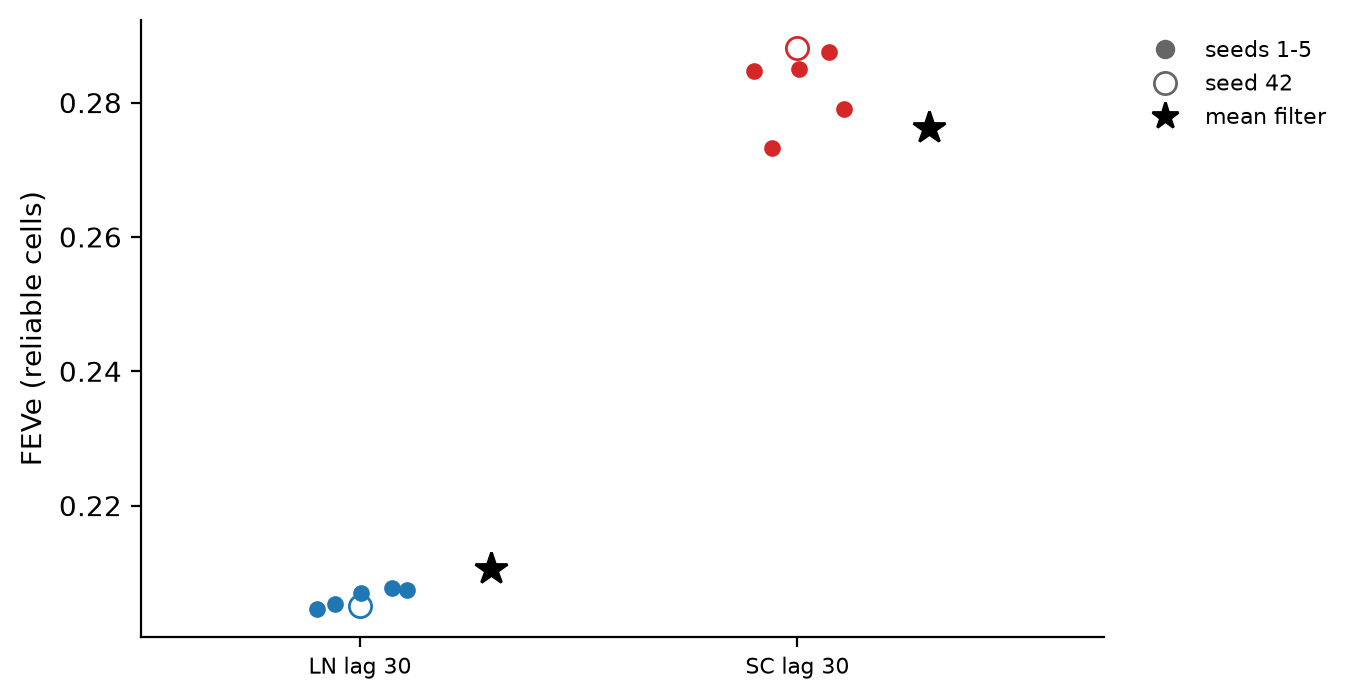

In [18]:
def plot_seed_performance(names: list[str]) -> None:
    fig, ax = plt.subplots(figsize=(2.2 * len(names) + 2.5, 3.6))
    avg = seed_table(names, "FEVe")
    for x, name in enumerate(avg.index):
        for s in SEEDS:
            if f"seed {s}" in avg.columns:
                ax.plot(
                    x + np.random.default_rng(s).uniform(-0.12, 0.12),
                    avg.loc[name, f"seed {s}"],
                    "o",
                    color=PALETTE[name],
                    ms=5,
                )
        if "seed 42" in avg.columns:
            ax.plot(x, avg.loc[name, "seed 42"], "o", mfc="none", mec=PALETTE[name], ms=8)
        if "mean filter" in avg.columns and not np.isnan(avg.loc[name, "mean filter"]):
            ax.plot(x + 0.3, avg.loc[name, "mean filter"], "*", color="k", ms=12)
    ax.set_xticks(range(len(avg.index)), avg.index, fontsize=8)
    ax.set(ylabel="FEVe (reliable cells)", xlim=(-0.5, len(avg.index) - 0.3))
    ax.legend(
        handles=[
            matplotlib.lines.Line2D([], [], ls="", marker="o", color="0.4", label="seeds 1-5"),
            matplotlib.lines.Line2D([], [], ls="", marker="o", mfc="none", mec="0.4", ms=8, label="seed 42"),
            matplotlib.lines.Line2D([], [], ls="", marker="*", color="k", ms=10, label="mean filter"),
        ],
        fontsize=8,
        loc="upper left",
        bbox_to_anchor=(1.02, 1),
        frameon=False,
    )
    sns.despine(fig=fig)
    fig.tight_layout()


plot_seed_performance(PENALISED)

The example cells across seeds. Spatial: each seed's mask (the 1.5 sigma contour of its Gaussian) over the seed-42
spatial filter, and the mean-filter model's mask in black. Temporal: each seed's filter, and the mean-filter model's in
black.

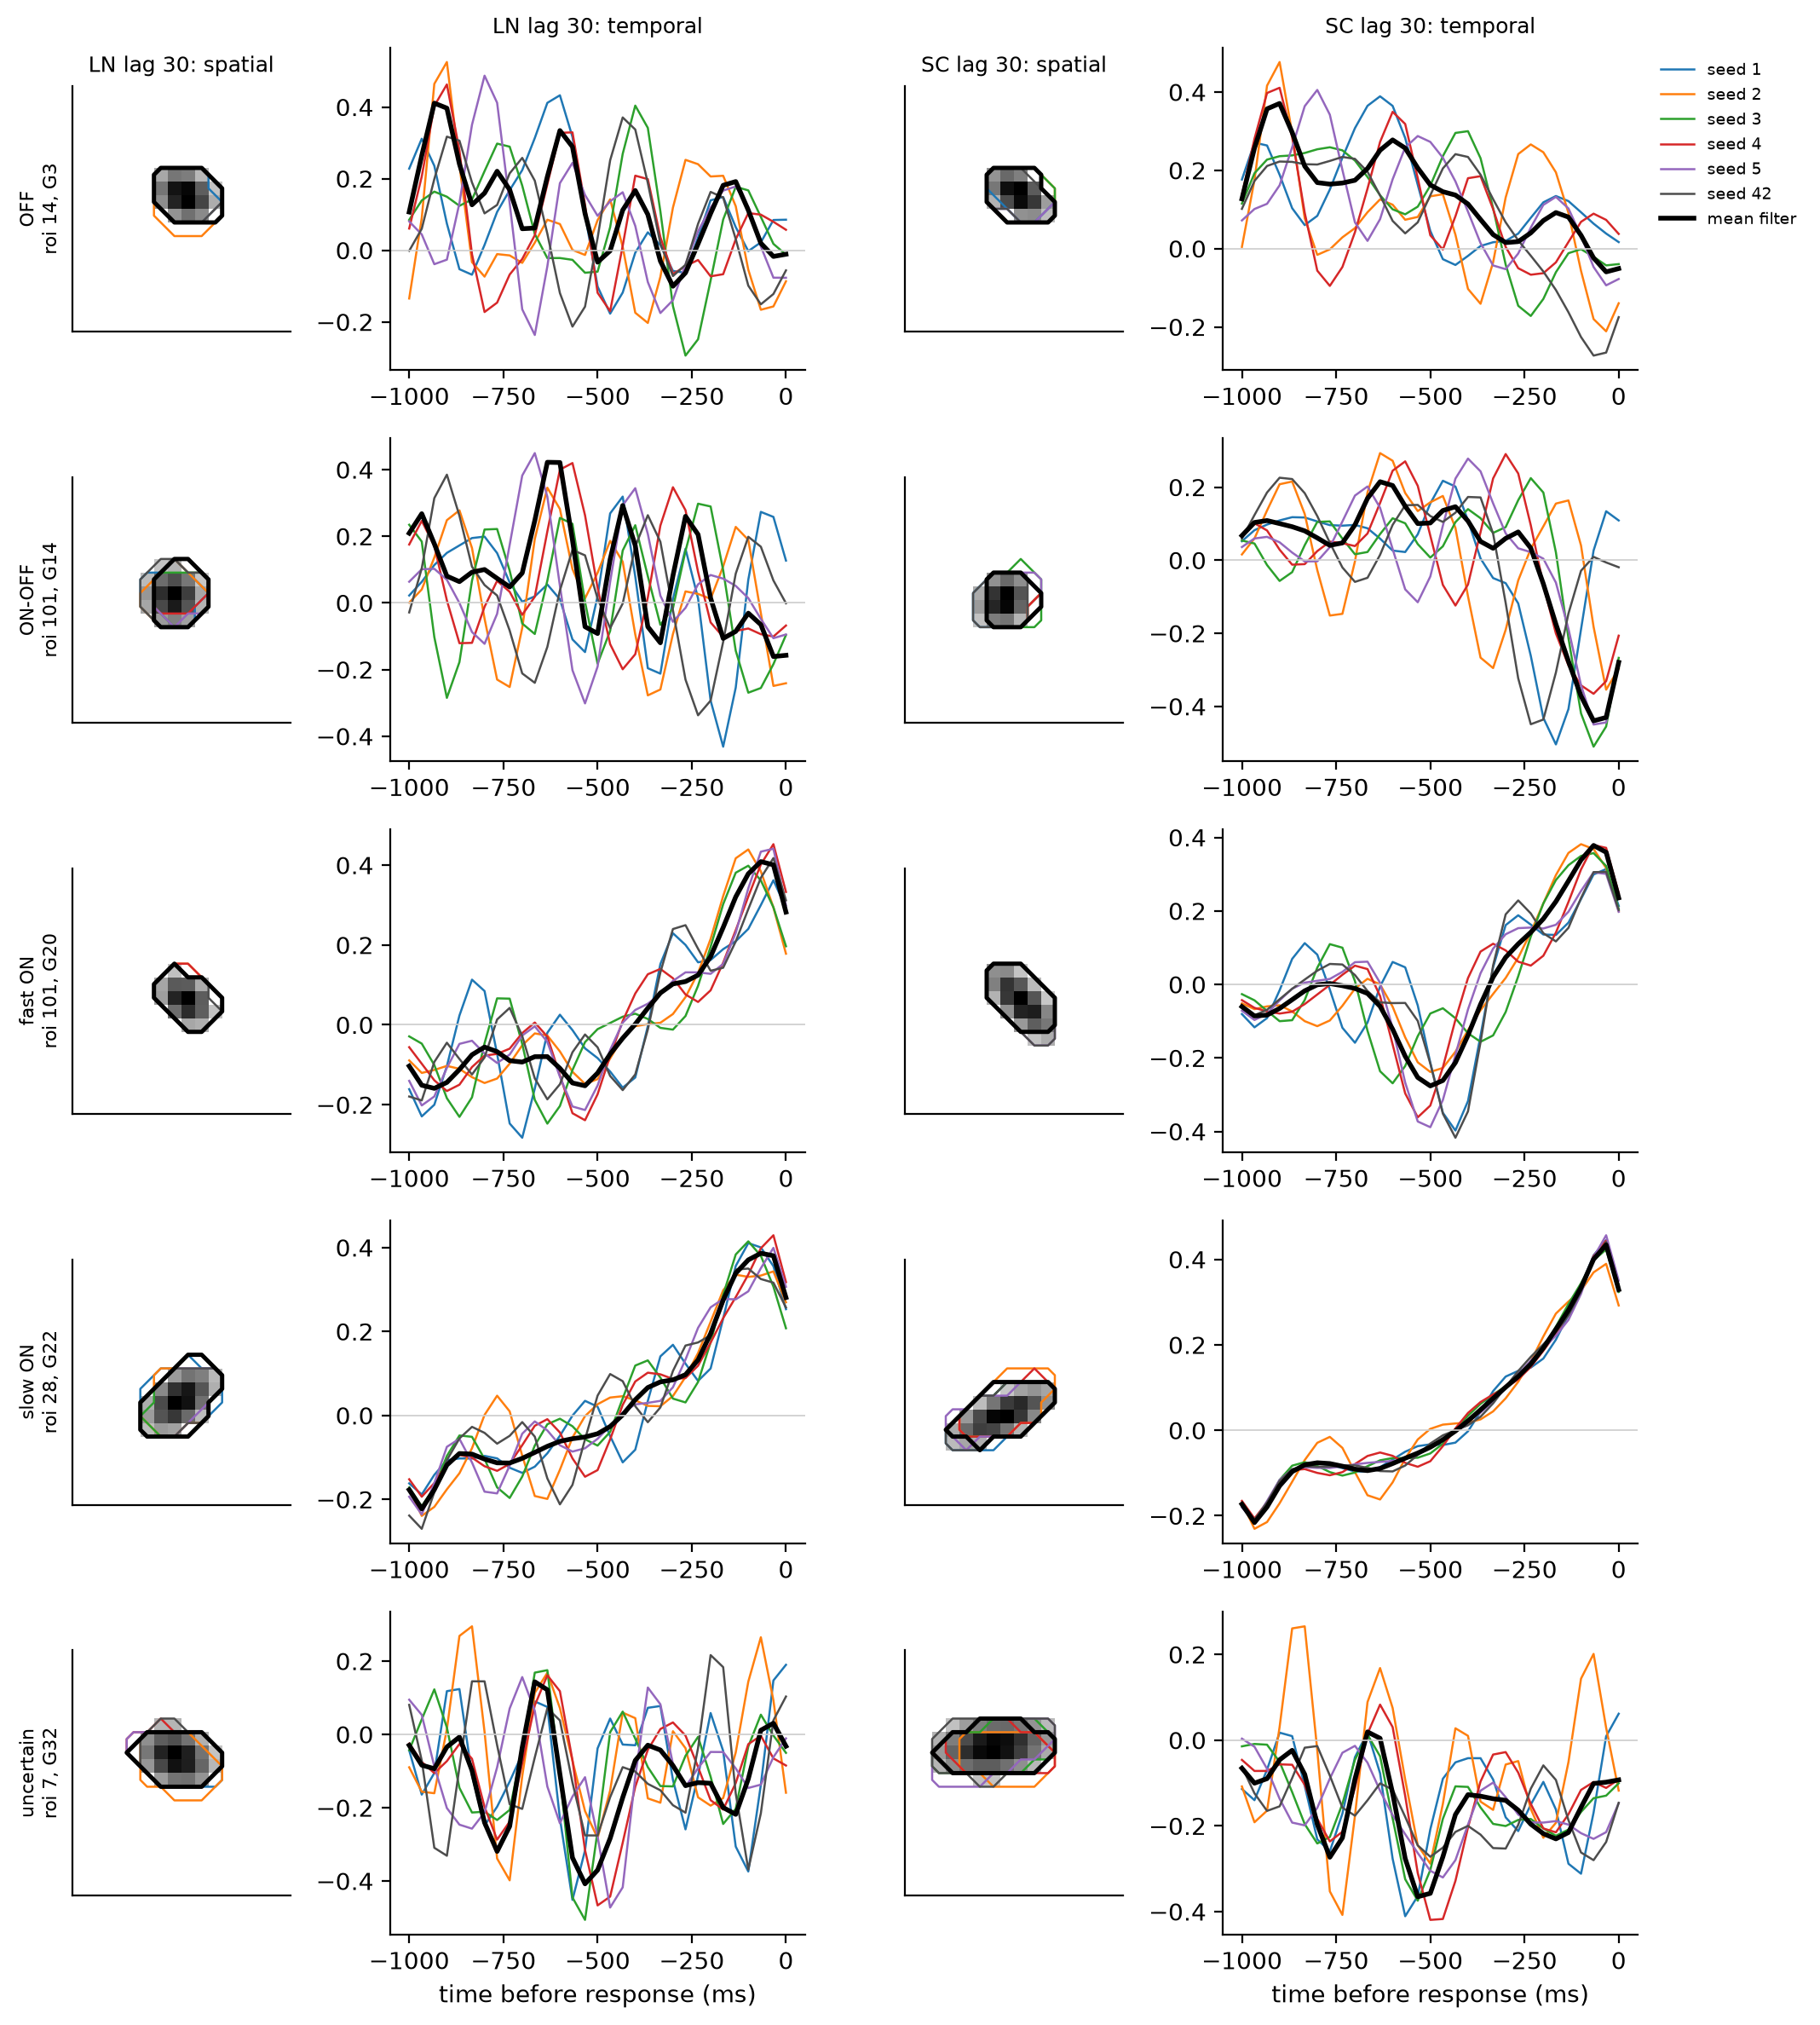

In [19]:
SEED_COLOURS = dict(zip(SEED_NAMES + ["seed 42"], sns.color_palette("tab10", len(SEEDS)) + ["0.3"]))
fig, axes = plt.subplots(
    nrows=len(example_cells),
    ncols=2 * len(PENALISED),
    figsize=(5.4 * len(PENALISED), 2.4 * len(example_cells)),
    gridspec_kw={"width_ratios": [1, 1.9] * len(PENALISED)},
    squeeze=False,
)
for row_axes, (session, neuron) in zip(axes, example_cells):
    for column, name in enumerate(PENALISED):
        ax_space, ax_time = row_axes[2 * column], row_axes[2 * column + 1]
        spatial_42, _ = sc_filters(seed_models[(name, "seed 42")].readout[session])
        ax_space.imshow(spatial_42[neuron], cmap="Greys", interpolation="none")
        for run, colour in SEED_COLOURS.items():
            if (name, run) not in seed_models:
                continue
            spatial, temporal = sc_filters(seed_models[(name, run)].readout[session])
            ax_space.contour(spatial[neuron] > 0, levels=[0.5], colors=[colour], linewidths=0.9)
            ax_time.plot(lags_ms(temporal.shape[1]), temporal[neuron], color=colour, lw=0.9, label=run)
        if (name, "mean filter") in seed_models:
            spatial, temporal = sc_filters(seed_models[(name, "mean filter")].readout[session])
            ax_space.contour(spatial[neuron] > 0, levels=[0.5], colors="k", linewidths=1.8)
            ax_time.plot(lags_ms(temporal.shape[1]), temporal[neuron], color="k", lw=2, label="mean filter")
        clean_map(ax_space)
        ax_time.axhline(0, color="0.8", lw=0.6)
        if (session, neuron) == example_cells[0]:
            ax_space.set_title(f"{name}: spatial", fontsize=9)
            ax_time.set_title(f"{name}: temporal", fontsize=9)
        if (session, neuron) == example_cells[-1]:
            ax_time.set_xlabel("time before response (ms)")
    info = cell_info.loc[(session, neuron)]
    row_axes[0].set_ylabel(f"{info.group_class}\nroi {info.roi_id}, G{info.group}", fontsize=8)
axes[0, -1].legend(fontsize=7, loc="upper left", bbox_to_anchor=(1.02, 1), frameon=False)
sns.despine(fig=fig)
fig.tight_layout()

The mean-filter models against the per-cell average of seeds 1-5 and against seed 42 (paired, reliable cells), and what
they refit: the cosine between each seed's spatial filter and the mean-filter model's, and the median `w`.

In [20]:
seed_comparison_cells = seed_cells()
mean_filter_comparisons = []
for name in PENALISED:
    mean_filter_comparisons += [
        (f"{name} · seeds 1-5 (mean)", f"{name} · mean filter", f"{name}: mean filter - seeds 1-5 (mean)"),
        (f"{name} · seed 42", f"{name} · mean filter", f"{name}: mean filter - seed 42"),
    ]
display(difference_table(mean_filter_comparisons, seed_comparison_cells, decimals=4))


def w_of(model) -> np.ndarray:
    return np.concatenate([model.readout[s].w.detach().cpu().numpy() for s in sessions])


refit_rows = {}
for name in PENALISED:
    if (name, "mean filter") not in seed_models:
        continue
    frozen = filters_of((name, "mean filter"))["spatial"]
    cosines = np.concatenate(
        [(filters_of((name, run))["spatial"] * frozen).sum(-1) for run in SEED_NAMES if (name, run) in seed_models]
    )
    refit_rows[name] = {
        "spatial cosine, seed vs mean filter (median)": np.median(cosines),
        "spatial cosine (10th percentile)": np.percentile(cosines, 10),
        "w, seeds (median)": np.median(
            np.concatenate([w_of(seed_models[(name, run)]) for run in SEED_NAMES if (name, run) in seed_models])
        ),
        "w, mean filter (median)": np.median(w_of(seed_models[(name, "mean filter")])),
    }
pd.DataFrame(refit_rows).T.round(3)

,Δ FEVe,Δ Avg,cells higher (FEVe),cells lower (FEVe)
comparison,,,,
LN lag 30: mean filter - seeds 1-5 (mean),"+0.0041 [+0.0033, +0.0049]","+0.0035 [+0.0031, +0.0039]",0.500,0.239
LN lag 30: mean filter - seed 42,"+0.0054 [+0.0034, +0.0074]","+0.0040 [+0.0029, +0.0052]",0.433,0.296
SC lag 30: mean filter - seeds 1-5 (mean),"-0.0057 [-0.0072, -0.0043]","-0.0074 [-0.0091, -0.0058]",0.314,0.535
SC lag 30: mean filter - seed 42,"-0.0119 [-0.0141, -0.0098]","-0.0140 [-0.0165, -0.0118]",0.264,0.577


,"spatial cosine, seed vs mean filter (median)",spatial cosine (10th percentile),"w, seeds (median)","w, mean filter (median)"
LN lag 30,0.990,0.969,0.000,0.000
SC lag 30,0.986,0.960,0.756,0.601


**Performance barely depends on the seed.** Over seeds 1-5, the standard deviation of FEVe is 0.0014 for LN (range
0.003) and 0.0058 for SC (range 0.014, 0.273-0.288); for Avg it is 0.0011 and 0.0054. Seed 42, the Table 2 run, is the
best SC run (FEVe 0.288, Avg 0.460). Cell by cell, a cell's FEVe varies by a median 0.008-0.010 across seeds, and the
per-cell FEVe of two seeds correlate at r = 0.99-1.00.

**The spatial filters are reproducible:**
- cosine 0.98 between seeds;
- Gaussian centres within 0.08 px of their mean;
- sizes within 0.03-0.04 px.

**The temporal filters are less so.** With the penalty, two seeds' temporal filters have a median cosine of 0.64 (LN)
and 0.85 (SC). In the example cells, the filters of the fast and slow ON cells agree, while those of the OFF, ON-OFF and
uncertain cells differ in their details.

**Mean filter.** For LN, the model on the seeds' averaged filters is better than every seed: FEVe +0.004 over their
average (0.211 against 0.205-0.208). For SC it is worse: FEVe -0.006 below the seed average and -0.012 below seed 42,
among the lowest seeds (0.276). On validation it was within the seeds' range. The averaged spatial filters are not the
cause: each seed's spatial filter has a median cosine of 0.99 with the mean-filter model's. What differs is `w`, which
the frozen-filter refit makes smaller (median 0.60 against 0.76). Why this costs SC on the test set was not
investigated further.

# Other models

For the remaining sections: the lag-0 models, the lag-30 LN and SC models without the temporal penalty (seed 42 and
seeds 1-5), and the uniform-start grey LNP trained on spikes and on calcium.

In [21]:
add_models(LAG0_MODELS)
add_models(UNPENALISED_MODELS)
UNPENALISED = [name for name in UNPENALISED_MODELS if name in models]
for name in UNPENALISED:
    load_seed_runs(name, mean_filter=False)
target_lnps = {
    label: model for label, location in TARGET_LNPS.items() if (model := load_model("lnp", location)) is not None
}
print(f"target LNPs: {list(target_lnps)}")

/home/shash/PycharmProjects/open-retina/.venv/lib/python3.12/site-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'core' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['core'])`.
/home/shash/PycharmProjects/open-retina/.venv/lib/python3.12/site-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'readout' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['readout'])`.
/home/shash/PycharmProjects/open-retina/.venv/lib/python3.12/site-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'loss' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['loss'])`.


/home/shash/PycharmProjects/open-retina/.venv/lib/python3.12/site-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'core' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['core'])`.
/home/shash/PycharmProjects/open-retina/.venv/lib/python3.12/site-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'readout' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['readout'])`.
/home/shash/PycharmProjects/open-retina/.venv/lib/python3.12/site-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'loss' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['loss'])`.


models: ['LNP grey lag 30', 'LN lag 30', 'LNP colour lag 30', 'SC lag 30', 'LNP colour lag 0 (Table 2)', 'LNP grey lag 0', 'LN lag 0', 'SC lag 0']


/home/shash/PycharmProjects/open-retina/.venv/lib/python3.12/site-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'core' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['core'])`.
/home/shash/PycharmProjects/open-retina/.venv/lib/python3.12/site-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'readout' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['readout'])`.
/home/shash/PycharmProjects/open-retina/.venv/lib/python3.12/site-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'loss' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['loss'])`.


/home/shash/PycharmProjects/open-retina/.venv/lib/python3.12/site-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'core' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['core'])`.
/home/shash/PycharmProjects/open-retina/.venv/lib/python3.12/site-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'readout' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['readout'])`.
/home/shash/PycharmProjects/open-retina/.venv/lib/python3.12/site-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'loss' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['loss'])`.


...

/home/shash/PycharmProjects/open-retina/.venv/lib/python3.12/site-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'core' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['core'])`.
/home/shash/PycharmProjects/open-retina/.venv/lib/python3.12/site-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'readout' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['readout'])`.
/home/shash/PycharmProjects/open-retina/.venv/lib/python3.12/site-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'loss' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['loss'])`.


/home/shash/PycharmProjects/open-retina/.venv/lib/python3.12/site-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'core' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['core'])`.
/home/shash/PycharmProjects/open-retina/.venv/lib/python3.12/site-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'readout' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['readout'])`.
/home/shash/PycharmProjects/open-retina/.venv/lib/python3.12/site-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'loss' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['loss'])`.


/home/shash/PycharmProjects/open-retina/.venv/lib/python3.12/site-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'core' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['core'])`.
/home/shash/PycharmProjects/open-retina/.venv/lib/python3.12/site-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'readout' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['readout'])`.
/home/shash/PycharmProjects/open-retina/.venv/lib/python3.12/site-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'loss' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['loss'])`.


/home/shash/PycharmProjects/open-retina/.venv/lib/python3.12/site-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'core' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['core'])`.
/home/shash/PycharmProjects/open-retina/.venv/lib/python3.12/site-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'readout' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['readout'])`.
/home/shash/PycharmProjects/open-retina/.venv/lib/python3.12/site-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'loss' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['loss'])`.


target LNPs: ['spikes', 'calcium']


# Effect of temporal filtering: lag 0 vs lag 30

Each lag-30 model against its lag-0 counterpart, which sees only the current frame. Two caveats: the Table 2 LNP
(colour, lag 0) is effectively unregularised (spatial smoothness 0.12, against 3e4 for the other LNPs), so its
comparison also changes the regularisation; and the lag-0 LN and SC models have no temporal penalty, which is
meaningless for a single frame, so they are also compared with the unpenalised lag-30 models.

In [22]:
LAG_PAIRS = [
    ("LNP grey lag 0", "LNP grey lag 30", "grey LNP"),
    ("LN lag 0", "LN lag 30", "LN"),
    ("LNP colour lag 0 (Table 2)", "LNP colour lag 30", "colour LNP (and regularisation)"),
    ("SC lag 0", "SC lag 30", "SC"),
    ("LN lag 0", "LN lag 30, no temporal penalty", "LN, no temporal penalty"),
    ("SC lag 0", "SC lag 30, no temporal penalty", "SC, no temporal penalty"),
]
display(table2([label for pair in LAG_PAIRS[:4] for label in pair[:2]] + UNPENALISED))
difference_table(
    [(a, b, f"lag 0 -> lag 30: {description}") for a, b, description in LAG_PAIRS]
    + [
        ("LN lag 0", "SC lag 0", "contrast term SC - LN, lag 0"),
        ("LN lag 30", "SC lag 30", "contrast term SC - LN, lag 30"),
        (
            "LN lag 30, no temporal penalty",
            "SC lag 30, no temporal penalty",
            "contrast term SC - LN, lag 30, no temporal penalty",
        ),
    ]
)

,Avg,Indiv,FEVe
LNP grey lag 0,0.294,0.233 ± 0.024,0.079
LNP grey lag 30,0.369,0.295 ± 0.017,0.196
LN lag 0,0.274,0.217 ± 0.022,0.112
LN lag 30,0.394,0.314 ± 0.016,0.205
LNP colour lag 0 (Table 2),0.293,0.235 ± 0.020,0.029
LNP colour lag 30,0.440,0.352 ± 0.017,0.242
SC lag 0,0.274,0.217 ± 0.022,0.117
SC lag 30,0.460,0.367 ± 0.015,0.288
"LN lag 30, no temporal penalty",0.398,0.317 ± 0.016,0.210
"SC lag 30, no temporal penalty",0.460,0.367 ± 0.015,0.288


,Δ FEVe,Δ Avg,cells higher (FEVe),cells lower (FEVe)
comparison,,,,
lag 0 -> lag 30: grey LNP,"+0.117 [+0.104, +0.131]","+0.075 [+0.065, +0.086]",0.621,0.147
lag 0 -> lag 30: LN,"+0.094 [+0.084, +0.104]","+0.120 [+0.110, +0.131]",0.601,0.164
lag 0 -> lag 30: colour LNP (and regularisation),"+0.213 [+0.198, +0.229]","+0.146 [+0.137, +0.156]",0.691,0.028
lag 0 -> lag 30: SC,"+0.171 [+0.159, +0.185]","+0.186 [+0.174, +0.198]",0.774,0.092
"lag 0 -> lag 30: LN, no temporal penalty","+0.099 [+0.089, +0.110]","+0.124 [+0.114, +0.135]",0.605,0.162
"lag 0 -> lag 30: SC, no temporal penalty","+0.171 [+0.159, +0.185]","+0.186 [+0.174, +0.198]",0.763,0.098
"contrast term SC - LN, lag 0","+0.005 [+0.003, +0.007]","+0.001 [-0.003, +0.004]",0.333,0.287
"contrast term SC - LN, lag 30","+0.083 [+0.076, +0.090]","+0.067 [+0.060, +0.074]",0.743,0.104
"contrast term SC - LN, lag 30, no temporal penalty","+0.078 [+0.071, +0.085]","+0.063 [+0.056, +0.069]",0.725,0.115


The gain from lag 0 to lag 30 per functional type (paired, with 95% confidence intervals), and the contrast term
SC - LN at both lags:

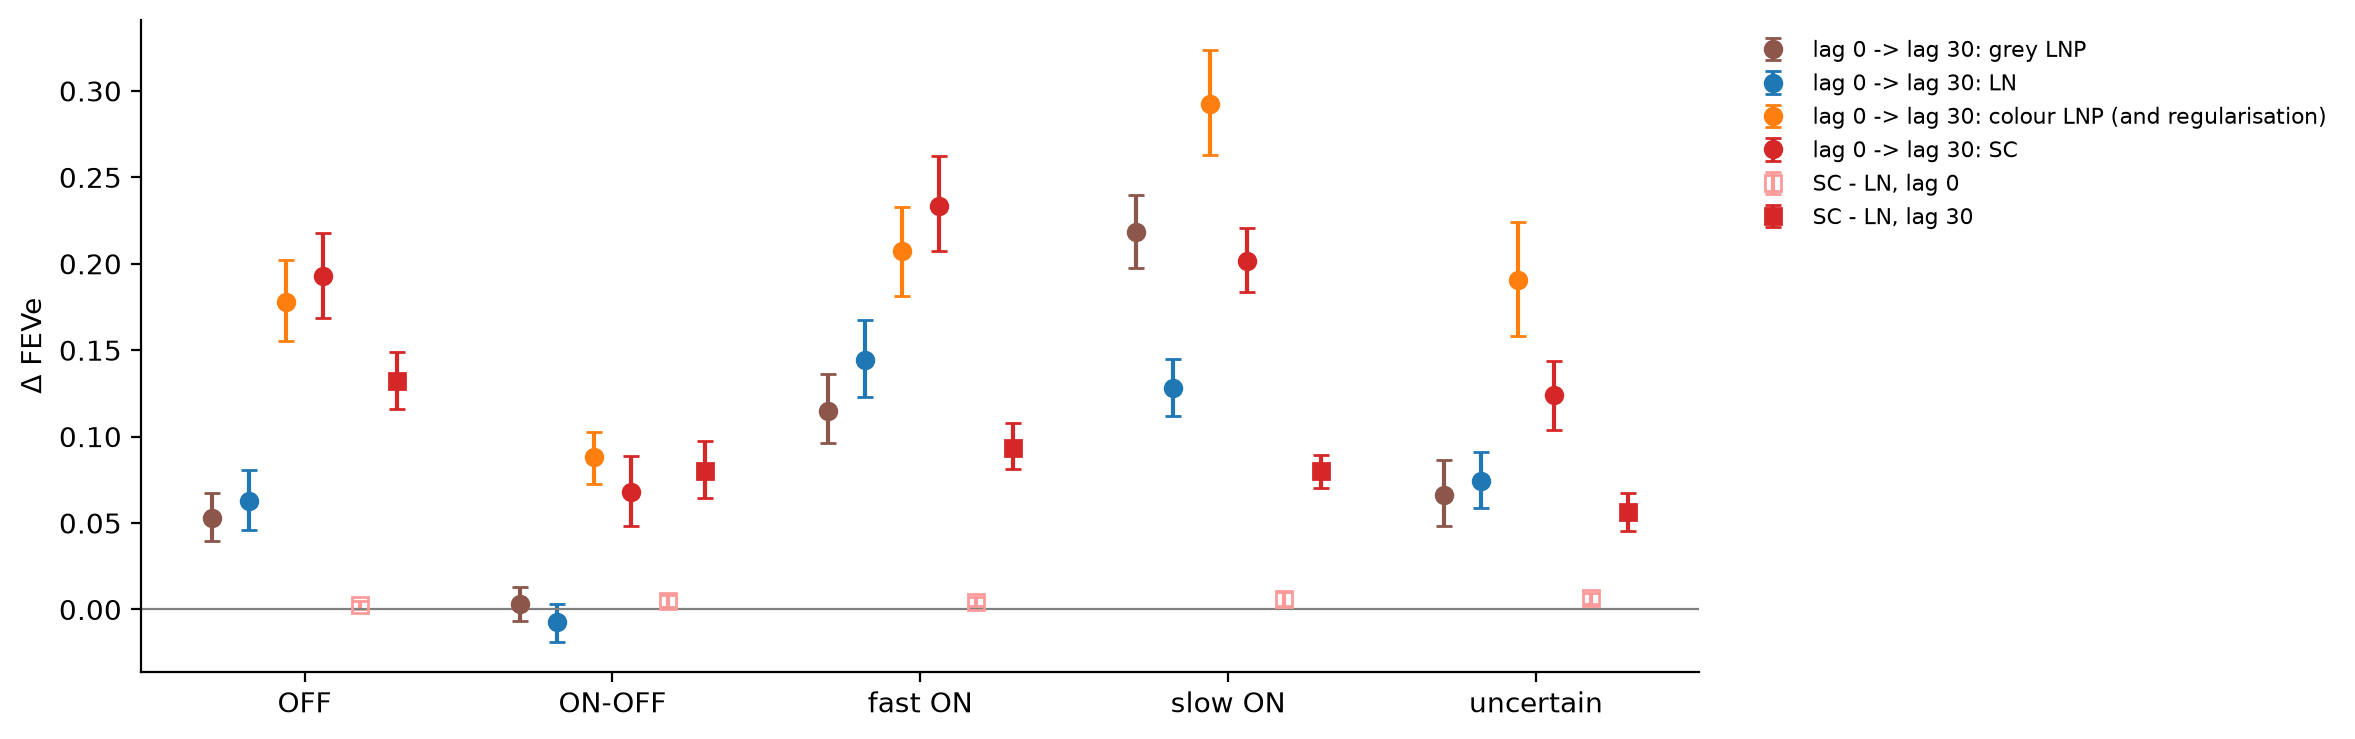

In [23]:
type_comparisons = {f"lag 0 -> lag 30: {d}": (a, b) for a, b, d in LAG_PAIRS[:4]}
type_comparisons |= {"SC - LN, lag 0": ("LN lag 0", "SC lag 0"), "SC - LN, lag 30": ("LN lag 30", "SC lag 30")}
type_comparisons = {k: (a, b) for k, (a, b) in type_comparisons.items() if a in models and b in models}
type_colours = [PALETTE[b] for _, b in type_comparisons.values()]
fig, ax = plt.subplots(figsize=(12, 3.8))
offsets = np.linspace(-0.3, 0.3, len(type_comparisons))
for offset, colour, (label, (a, b)) in zip(offsets, type_colours, type_comparisons.items()):
    gain = per_type_difference(a, b)
    marker = "s" if label.startswith("SC - LN") else "o"
    mfc = "none" if label.endswith("lag 0") else colour
    ax.errorbar(
        np.arange(len(gain)) + offset,
        gain["mean"],
        yerr=[gain["mean"] - gain["low"], gain["high"] - gain["mean"]],
        fmt=marker,
        color=colour,
        mfc=mfc,
        capsize=3,
        label=label,
    )
ax.axhline(0, color="0.5", lw=0.8)
ax.set_xticks(range(len(GROUPS)), list(GROUPS))
ax.set(ylabel="Δ FEVe")
ax.legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.02, 1), frameon=False)
sns.despine(fig=fig)
fig.tight_layout()

**Temporal filtering is what most of the gain comes from.** From lag 0 to lag 30, every model improves in FEVe:
- grey LNP: +0.117
- LN: +0.094
- SC: +0.171
- colour LNP: +0.213. This gain also includes the change from the effectively unregularised Table 2 LNP, whose FEVe is
  only 0.029.

**The contrast term needs the temporal filter.** At lag 0, SC is barely better than LN: FEVe +0.005 [+0.003, +0.007],
Avg +0.001. At lag 30 it gains +0.083. With a temporal filter, the local contrast is taken over the temporally filtered
stimulus, i.e. over how the movie changes within the receptive field. With a single frame it is the contrast of the
current image, which adds little to its mean.

**By cell type:**
- SC gains most in the fast ON, slow ON and OFF cells (+0.19 to +0.23).
- The colour LNP gains most in the slow ON cells (+0.29).
- In the ON-OFF cells the grey LNP and LN gain nothing.

The temporal penalty changes none of this. The unpenalised lag-30 models gain about as much: FEVe +0.099 (LN) and
+0.171 (SC).

# Noise in the temporal filters without the penalty

Without a temporal penalty, the parts of a lag-30 LN or SC temporal filter that the natural movies do not constrain
keep their random starting values. The example cells' temporal filters without (light) and with (dark) the penalty,
and the random filter both started from (dashed; the same for both, as they share the seed):

penalised and unpenalised runs start from the same temporal filters: True


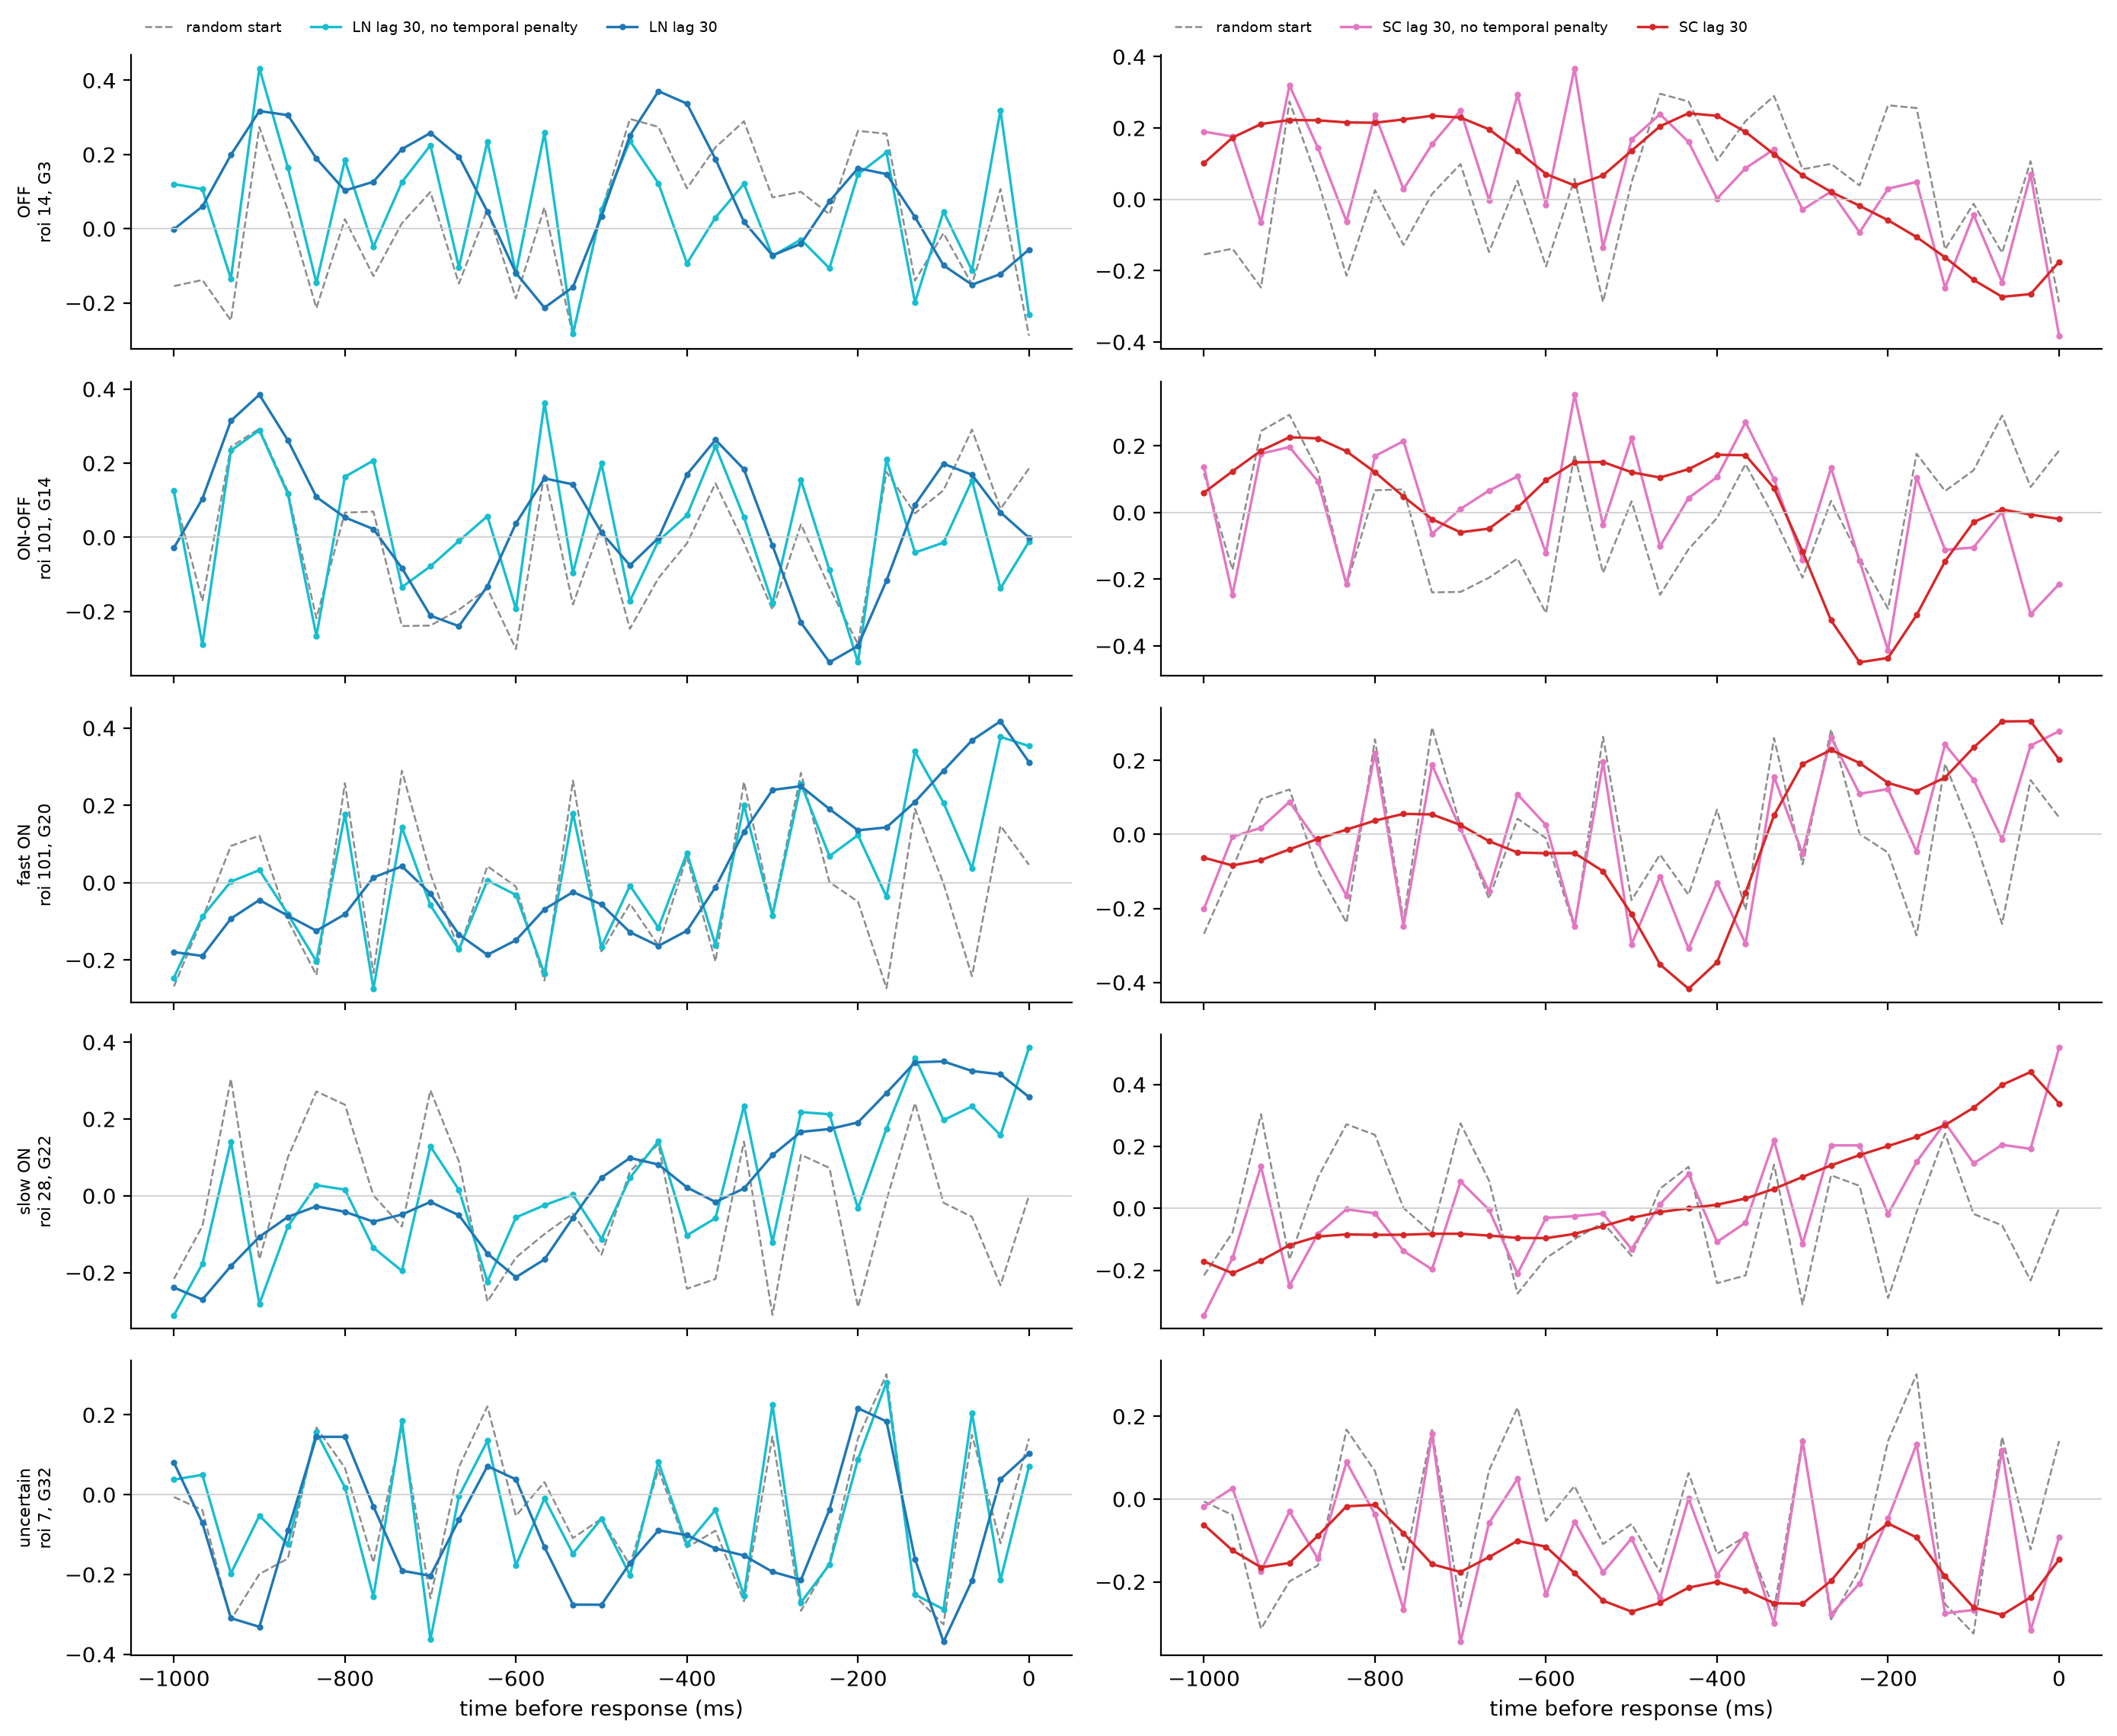

In [24]:
pairs = [
    (name, f"{name}, no temporal penalty")
    for name in ["LN lag 30", "SC lag 30"]
    if f"{name}, no temporal penalty" in models
]
fig, axes = plt.subplots(
    nrows=len(example_cells),
    ncols=len(pairs),
    figsize=(6 * len(pairs) + 2, 2.3 * len(example_cells)),
    sharex=True,
    squeeze=False,
)
same_start = True
for row_axes, (session, neuron) in zip(axes, example_cells):
    for ax, (penalised, unpenalised) in zip(row_axes, pairs):
        start = initial_temporal_filters(models[unpenalised].readout[session])[neuron]
        same_start &= np.allclose(
            start, initial_temporal_filters(models[penalised].readout[session])[neuron], atol=1e-5
        )
        ax.plot(lags_ms(len(start)), start, ls="--", color="0.55", lw=0.9, label="random start")
        for label in [unpenalised, penalised]:
            temporal = neuron_filters(label, session, neuron)[1]
            ax.plot(lags_ms(len(temporal)), temporal, marker="o", ms=2, color=PALETTE[label], lw=1.2, label=label)
        ax.axhline(0, color="0.8", lw=0.6)
    info = cell_info.loc[(session, neuron)]
    row_axes[0].set_ylabel(f"{info.group_class}\nroi {info.roi_id}, G{info.group}", fontsize=8)
for ax in axes[-1]:
    ax.set_xlabel("time before response (ms)")
for ax in axes[0]:
    ax.legend(fontsize=7, loc="lower left", bbox_to_anchor=(0, 1.02), ncols=3, frameon=False)
sns.despine(fig=fig)
fig.tight_layout()
print(f"penalised and unpenalised runs start from the same temporal filters: {same_start}")

The mean over all cells of each type, without and with the penalty:

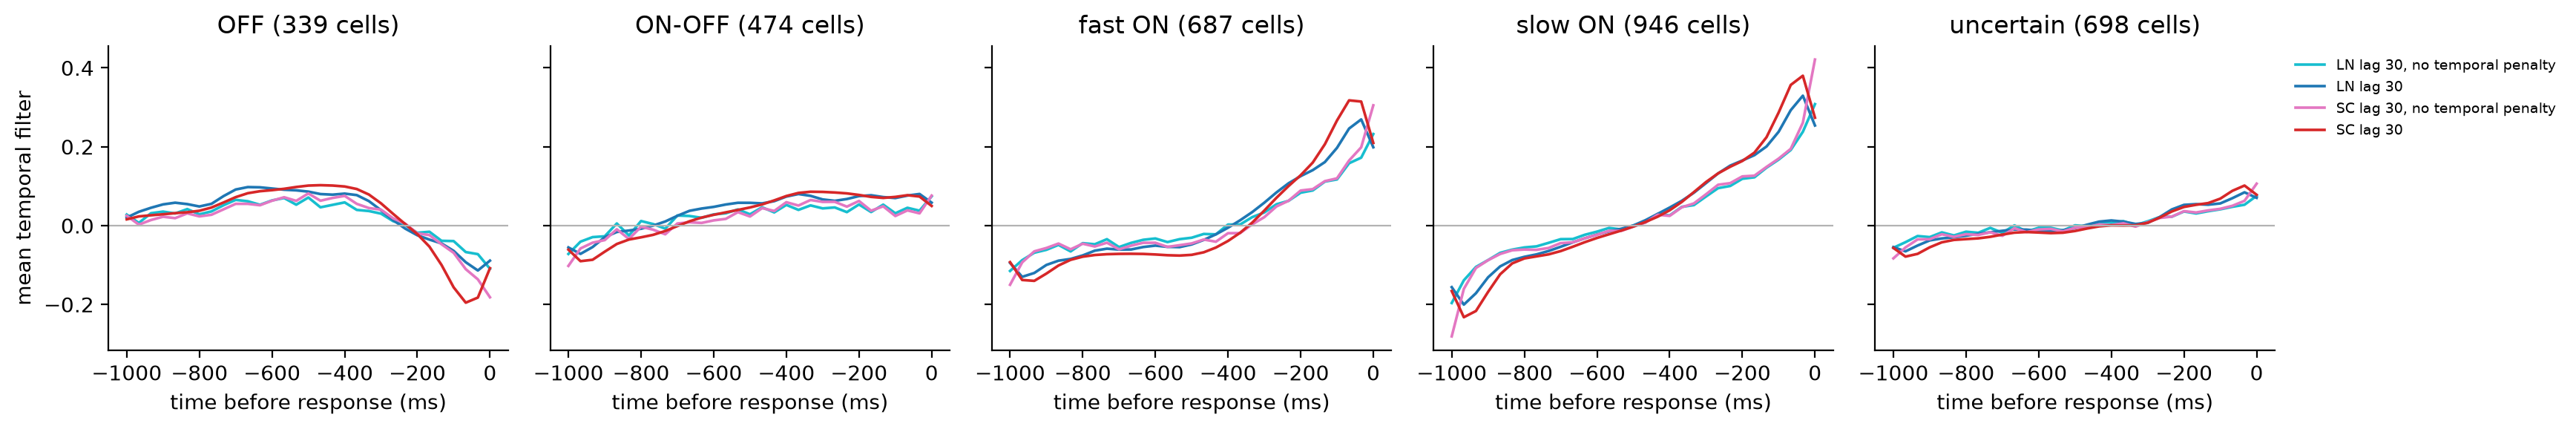

In [25]:
curves = {}
for penalised, unpenalised in pairs:
    curves[unpenalised] = (all_temporal_filters(unpenalised), {"color": PALETTE[unpenalised]})
    curves[penalised] = (all_temporal_filters(penalised), {"color": PALETTE[penalised]})
plot_mean_temporal_filters(curves);

The shape of the lag-30 temporal filters over all cells (unit norm): roughness, the sum of the squared differences
between neighbouring taps (about 1.9 for white noise); the median cosine with the random start; the fraction of cells
whose filter peaks on the current frame; and the median ratio of the current-frame tap to the peak. The LNPs, which
have the penalty, for reference (for the colour LNP both channels pooled).

In [26]:
def kernel_shape(filters: np.ndarray, initial: np.ndarray | None = None) -> dict[str, float]:
    filters = filters.reshape(-1, filters.shape[-1])
    filters = filters / np.linalg.norm(filters, axis=1, keepdims=True).clip(1e-12)
    shape = {
        "roughness (median)": np.median((np.diff(filters, axis=1) ** 2).sum(axis=1)),
        "cosine with start (median)": np.nan if initial is None else np.median((filters * initial).sum(axis=1)),
        "peak on current frame": np.mean(np.abs(filters).argmax(axis=1) == filters.shape[1] - 1),
        "|current| / |peak| (median)": np.median(np.abs(filters[:, -1]) / np.abs(filters).max(axis=1)),
    }
    return shape


SHAPE_MODELS = TABLE + UNPENALISED
shape_rows = {}
for label in SHAPE_MODELS:
    initial = None
    if isinstance(models[label], SpatialContrastCoreReadout):
        initial = np.concatenate([initial_temporal_filters(models[label].readout[s]) for s in sessions])
    shape_rows[label] = kernel_shape(all_temporal_filters(label), initial)
kernel_shapes = pd.DataFrame(shape_rows).T
kernel_shapes.round(3)

,roughness (median),cosine with start (median),peak on current frame,|current| / |peak| (median)
LNP grey lag 30,0.502,NaN,0.125,0.565
LN lag 30,0.280,0.394,0.013,0.590
LNP colour lag 30,0.472,NaN,0.228,0.708
SC lag 30,0.095,0.180,0.000,0.621
"LN lag 30, no temporal penalty",1.973,0.764,0.219,0.612
"SC lag 30, no temporal penalty",1.562,0.630,0.392,0.866


How reproducible the filters are across seeds 1-5, without and with the penalty (as in the seed section), and the
distribution over reliable cells of the cosine between two seeds' temporal filters (mean over pairs):

,per-cell SD of FEVe,"per-cell FEVe, seed vs seed (r)","temporal cosine, seed vs seed","spatial cosine, seed vs seed",centre spread (px),size SD (px),"temporal cosine, seed vs mean filter"
"LN lag 30, no temporal penalty",0.007,0.996,0.355,0.980,0.099,0.034,NaN
LN lag 30,0.008,0.995,0.636,0.982,0.083,0.034,0.842
"SC lag 30, no temporal penalty",0.011,0.989,0.523,0.979,0.073,0.038,NaN
SC lag 30,0.010,0.991,0.845,0.979,0.077,0.041,0.936


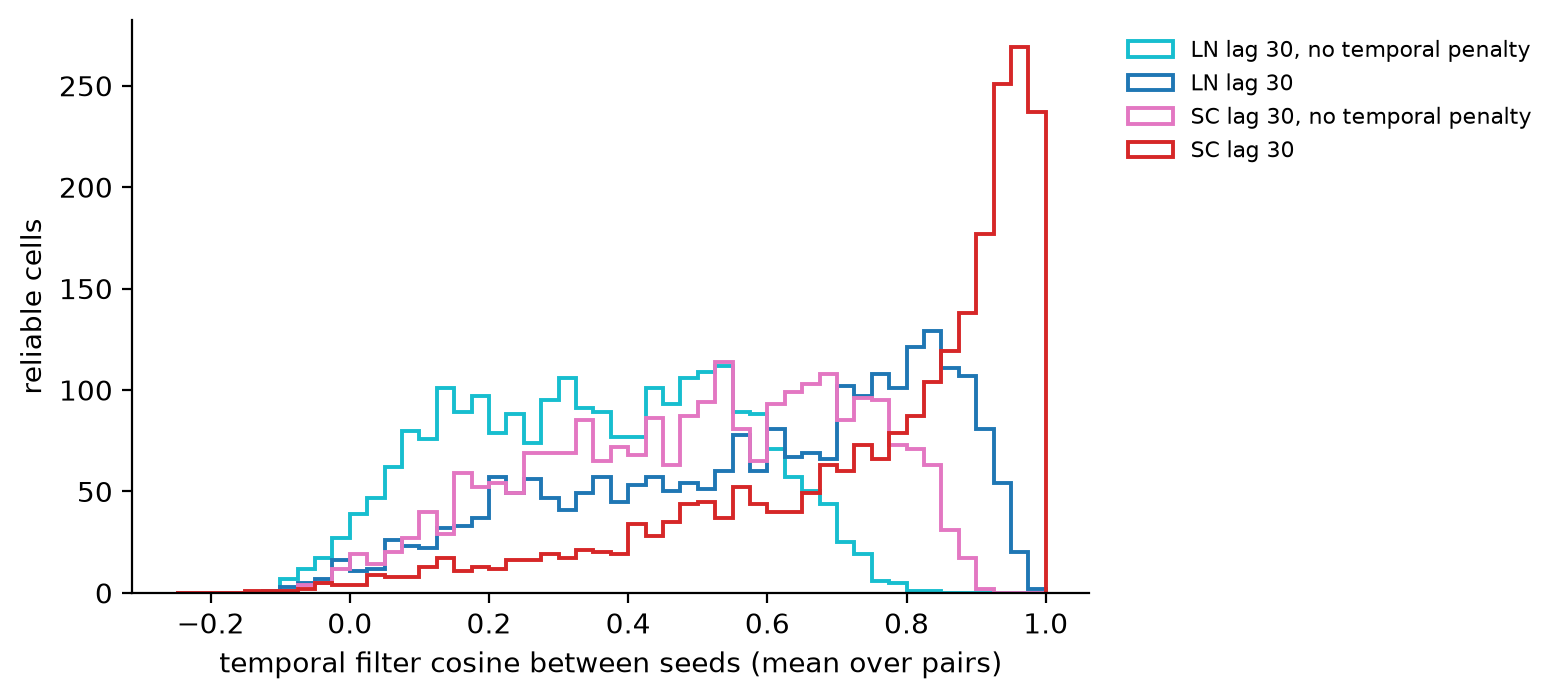

In [27]:
NOISE_NAMES = [n for pair in pairs for n in pair[::-1]]
display(pd.DataFrame({name: seed_agreement(name) for name in NOISE_NAMES}).T.round(3))

fig, ax = plt.subplots(figsize=(8, 3.6))
for name in NOISE_NAMES:
    temporal = np.stack([filters_of((name, run))["temporal"] for run in SEED_NAMES if (name, run) in seed_models])
    ax.hist(
        mean_pairwise_cosine(temporal)[reliable_order],
        bins=np.linspace(-0.25, 1, 51),
        histtype="step",
        lw=1.4,
        color=PALETTE[name],
        label=name,
    )
ax.set(xlabel="temporal filter cosine between seeds (mean over pairs)", ylabel="reliable cells")
ax.legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.02, 1), frameon=False)
sns.despine(fig=fig)
fig.tight_layout()

What the penalty costs in prediction (paired, reliable cells): for the seed-42 runs, and for the per-cell average over
seeds 1-5.

In [28]:
penalty_comparisons = []
for penalised, unpenalised in pairs:
    for run in ["seed 42", "seeds 1-5 (mean)"]:
        penalty_comparisons.append(
            (f"{unpenalised} · {run}", f"{penalised} · {run}", f"{penalised.split(' ')[0]}: penalty, {run}")
        )
difference_table(penalty_comparisons, seed_cells(), decimals=4)

,Δ FEVe,Δ Avg,cells higher (FEVe),cells lower (FEVe)
comparison,,,,
"LN: penalty, seed 42","-0.0052 [-0.0067, -0.0037]","-0.0040 [-0.0048, -0.0032]",0.261,0.461
"LN: penalty, seeds 1-5 (mean)","-0.0059 [-0.0069, -0.0051]","-0.0051 [-0.0058, -0.0044]",0.129,0.615
"SC: penalty, seed 42","-0.0002 [-0.0019, +0.0016]","-0.0001 [-0.0013, +0.0011]",0.400,0.444
"SC: penalty, seeds 1-5 (mean)","-0.0086 [-0.0097, -0.0076]","-0.0082 [-0.0090, -0.0074]",0.175,0.686


**Without the penalty, the temporal filters are largely their random start.**
- **Shape:** their median roughness is 1.97 (LN) and 1.56 (SC), against about 1.9 for white noise. Their median cosine
  with the random start is 0.76 and 0.63.
- **With the penalty:** roughness falls to 0.28 and 0.10, below the LNPs' 0.47-0.50, and the cosine with the start
  falls to 0.39 and 0.18.
- **Example cells:** the unpenalised filters follow the random start tap by tap, on top of a smooth component like the
  penalised filter's.
- **Type means:** they are almost the same with and without the penalty, because the cells' random starts average
  out.
- **Seeds:** each seed starts from different noise, so without the penalty the seeds agree much less. The temporal
  cosine between seeds is 0.36 (LN) and 0.52 (SC), against 0.64 and 0.85 with the penalty. The spatial filters agree
  equally well either way (0.98).

**What the penalty costs.** The penalty costs a little prediction:
- Over seeds 1-5, FEVe falls by 0.006 (LN) and 0.009 (SC), lower in 62% and 69% of cells and higher in 13% and 18%.
- For the seed-42 runs the costs are 0.005 and 0.000; seed 42 happened to be the best penalised SC run.

The penalty also changes the newest taps. Its Laplacian pads the filter with zeros, which pulls the end taps towards
zero. Almost no penalised filter peaks on the current frame, against 22-39% without the penalty. Since the current
frame carries real weight (next section), this may be part of the cost.

# Why the current frame carries a large weight

Many cells' lag-30 temporal filters put a large weight on the current frame (0 ms), the frame shown at the time of the
response: in the kernel-shape table above, the filter peaks there in a fraction of the LNPs' cells and of the
unpenalised LN and SC cells. (The penalty pulls the end taps of the LN and SC filters towards zero, as its Laplacian
pads the filter with zeros, so they hardly ever peak there; their current-frame tap is still a large fraction of the
peak.) A causal response to light should lag the stimulus by tens of milliseconds, so this weight comes from the
responses: the models fit spikes inferred from calcium imaging at 7.8 Hz, interpolated to the 30 Hz stimulus frames,
and spike inference is not causal.

Distribution of where each cell's temporal filter peaks:

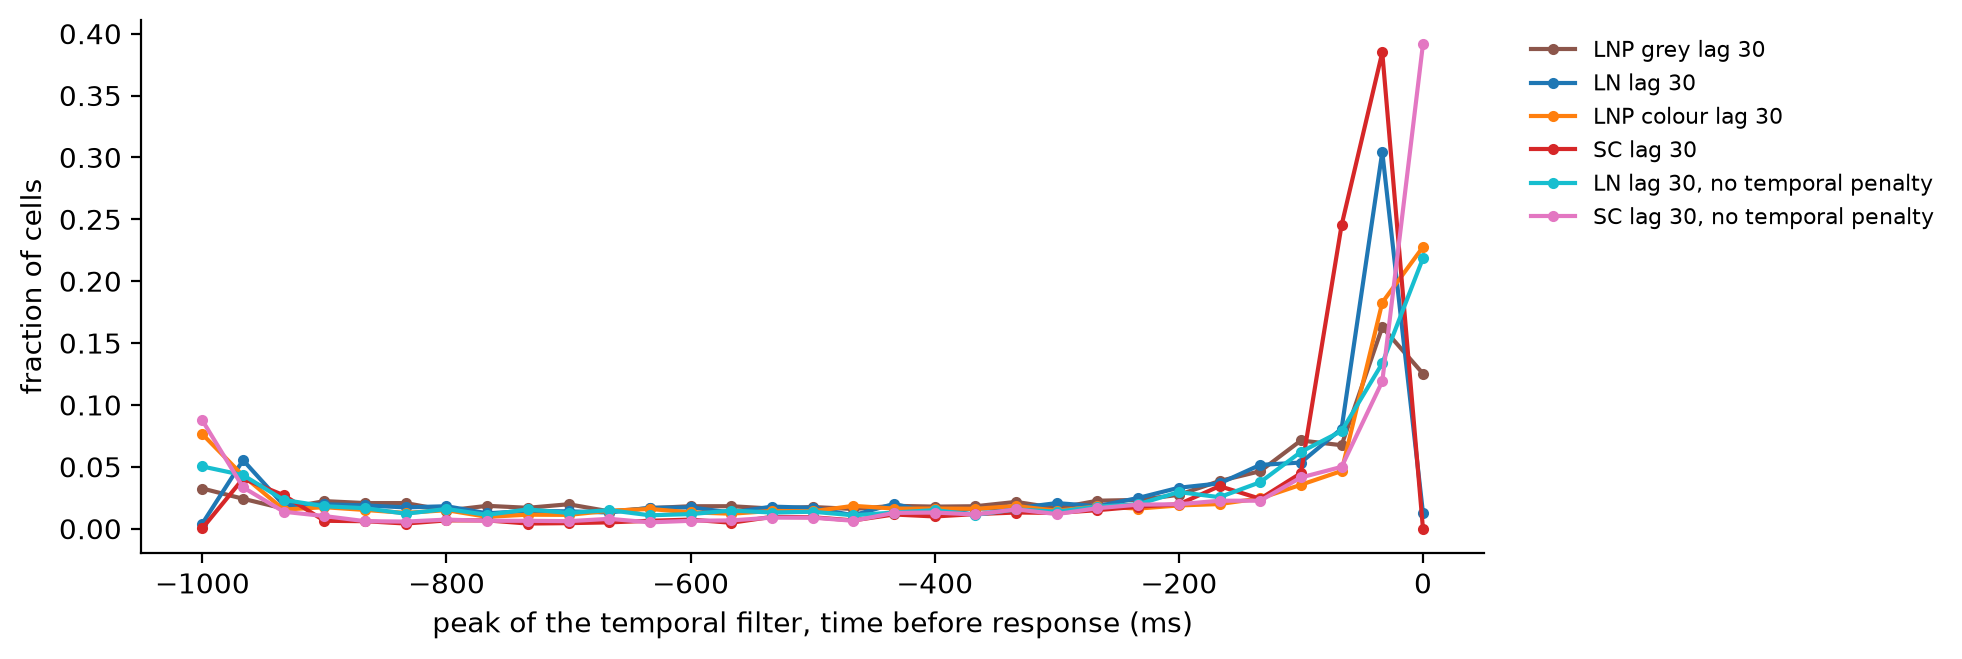

In [29]:
PEAK_MODELS = TABLE + UNPENALISED
fig, ax = plt.subplots(figsize=(10, 3.4))
for label in PEAK_MODELS:
    filters = all_temporal_filters(label).reshape(-1, all_temporal_filters(label).shape[-1])
    frames_before = filters.shape[1] - 1 - np.abs(filters).argmax(axis=1)
    fraction = np.bincount(frames_before, minlength=filters.shape[1]) / len(frames_before)
    ax.plot(
        -np.arange(filters.shape[1]) * 1000 / FRAME_RATE_HZ,
        fraction,
        marker="o",
        ms=3,
        color=PALETTE[label],
        label=label,
    )
ax.set(xlabel="peak of the temporal filter, time before response (ms)", ylabel="fraction of cells")
ax.legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.02, 1), frameon=False)
sns.despine(fig=fig)
fig.tight_layout()

## Inferred spikes lead the stimulus

Average calcium signal and inferred spikes around the light-on step (ON cells) and the light-off step (OFF cells) of
the chirp, over the analysed cells and all chirp repeats. The inferred spikes start rising before the step, while the
calcium signal they are inferred from rises only after it. A response at frame t therefore partly reflects frames
after t, which a causal model can only approximate with its newest frames. This holds for every Table 2 model, the CNN
included.

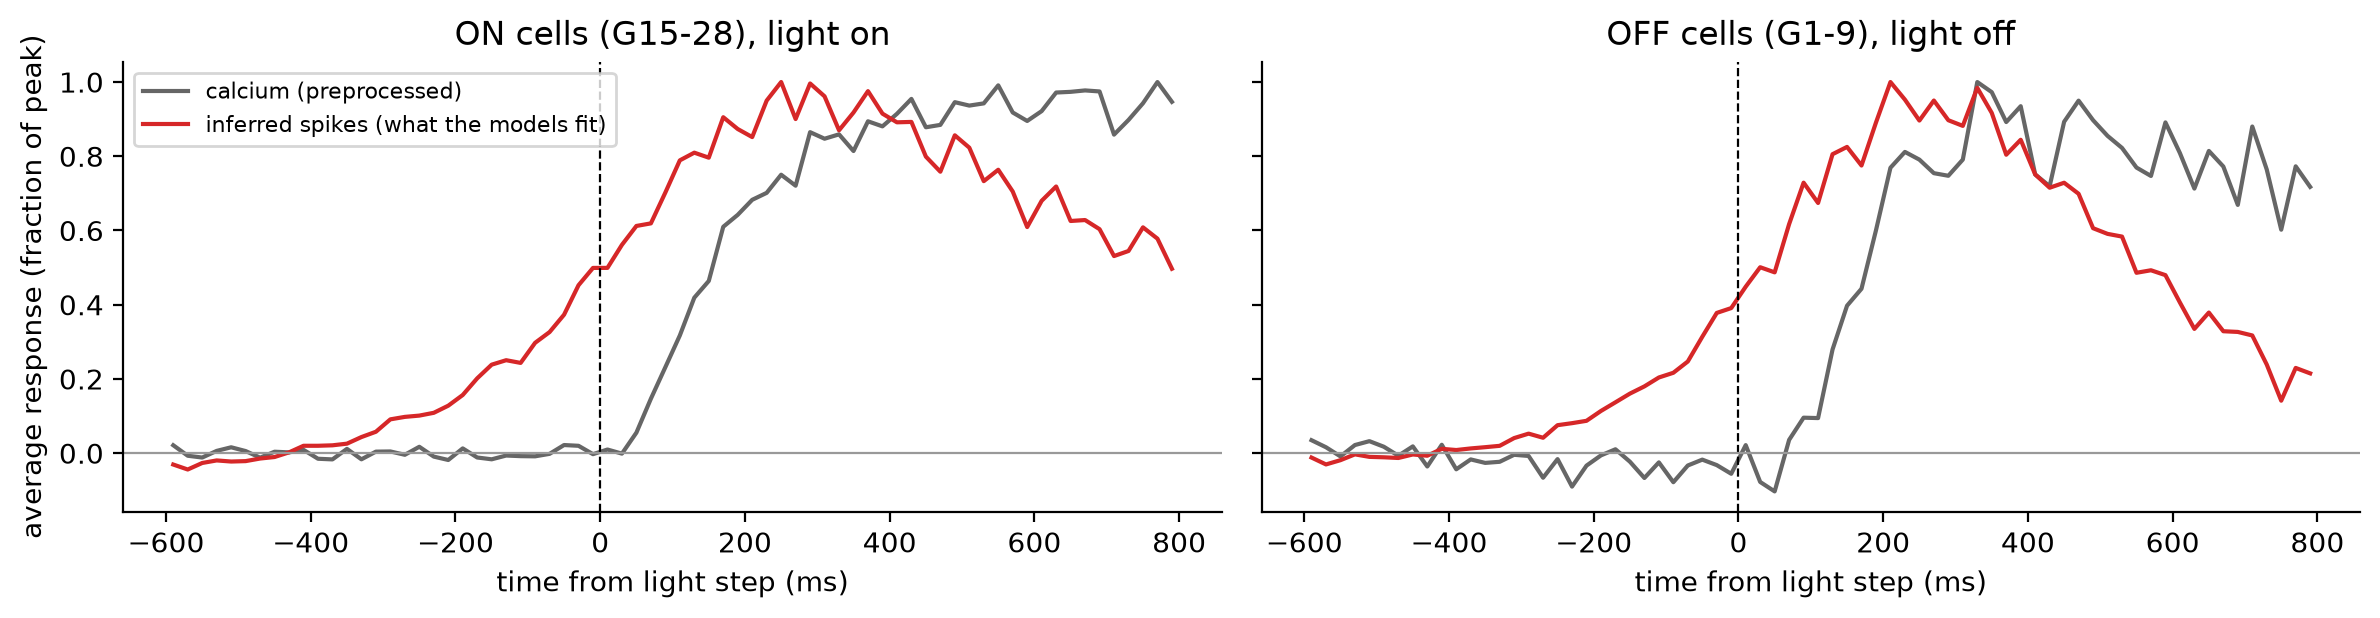

In [30]:
CHIRP_STEPS = {  # cells (first and last group) and the light step they respond to
    "ON cells (G15-28), light on": (15, 28, "on"),
    "OFF cells (G1-9), light off": (1, 9, "off"),
}
CHIRP_SIGNALS = {  # signal: (traces, their time stamps) in the responses file
    "calcium (preprocessed)": ("chirp_preprocessed_traces", "chirp_traces_times"),
    "inferred spikes (what the models fit)": ("chirp_spikes", "chirp_spike_times"),
}
STEP_BINS = np.arange(-0.6, 0.8001, 0.02)  # s around the step


def step_average(traces_key: str, times_key: str, first_group: int, last_group: int, step: str) -> np.ndarray:
    # Average of a chirp signal around a light step, over the analysed cells of some groups and all chirp repeats.
    # Each cell is scaled by its standard deviation and each repeat baseline-subtracted over 0.6 to 0.3 s before the
    # step. Every cell is sampled at 7.8 Hz at its own phase, so pooling cells resolves the average more finely.
    total, count = np.zeros(len(STEP_BINS) - 1), np.zeros(len(STEP_BINS) - 1)
    for session in sessions:
        raw = responses_dict[session]
        groups = final_responses[session].session_kwargs["group_assignment"]
        roi_ids = final_responses[session].session_kwargs["roi_ids"][(groups >= first_group) & (groups <= last_group)]
        # Two triggers per chirp: its start, and the light-off step 5 s in, after 2 s dark and 3 s light
        triggers = raw["chirp_trigger_times"][0]
        starts, light_off = triggers[::2], triggers[1::2]
        step_times = starts + 0.4 * (light_off - starts) if step == "on" else light_off
        for row in np.flatnonzero(np.isin(raw["roi_ids"], roi_ids.astype(int))):
            trace, times = raw[traces_key][row].astype(float), raw[times_key][row]
            valid = np.isfinite(trace)
            trace, times = trace[valid] / (trace[valid].std() + 1e-9), times[valid]
            for step_time in step_times:
                relative = times - step_time
                baseline = trace[(relative >= STEP_BINS[0]) & (relative < -0.3)]
                inside = (relative >= STEP_BINS[0]) & (relative < STEP_BINS[-1])
                if baseline.size == 0:
                    continue
                bins = np.digitize(relative[inside], STEP_BINS) - 1
                np.add.at(total, bins, trace[inside] - baseline.mean())
                np.add.at(count, bins, 1)
    return total / np.maximum(count, 1)


step_centres_ms = 1000 * (STEP_BINS[:-1] + STEP_BINS[1:]) / 2
fig, axes = plt.subplots(ncols=len(CHIRP_STEPS), figsize=(6 * len(CHIRP_STEPS), 3.2), sharey=True)
for ax, (title, (first_group, last_group, step)) in zip(axes, CHIRP_STEPS.items()):
    for (label, (traces_key, times_key)), color in zip(CHIRP_SIGNALS.items(), ["0.4", "C3"]):
        average = step_average(traces_key, times_key, first_group, last_group, step)
        ax.plot(step_centres_ms, average / np.abs(average).max(), color=color, label=label)
    ax.axvline(0, color="k", lw=0.8, ls="--")
    ax.axhline(0, color="0.6", lw=0.8)
    ax.set(title=title, xlabel="time from light step (ms)")
axes[0].set_ylabel("average response (fraction of peak)")
axes[0].legend(fontsize=8, loc="upper left")
sns.despine(fig=fig)
fig.tight_layout()

## The same at the scene cuts of the test movie

The test movie cuts to a new scene at the start of its clips (the dotted lines in the prediction traces), so a causal
response can change only from the first frame after a cut on. The cuts are taken from the stimulus itself: at each clip
boundary, the first frame into which the stimulus jumps (mean absolute change over pixels and channels above 0.5, about
12 times the median change). Averaged over all cells and cuts: how much the recorded response (mean of the repeats) and
each model's prediction change from one frame to the next, each z-scored per cell and shown as a fraction of its rise
above the level 1000-667 ms before the cut. Time 0 is the first frame of the new scene; the stimulus's own change is
drawn dashed.

cuts at frames [150, 298, 450] (clip boundaries [150, 300, 450, 600])


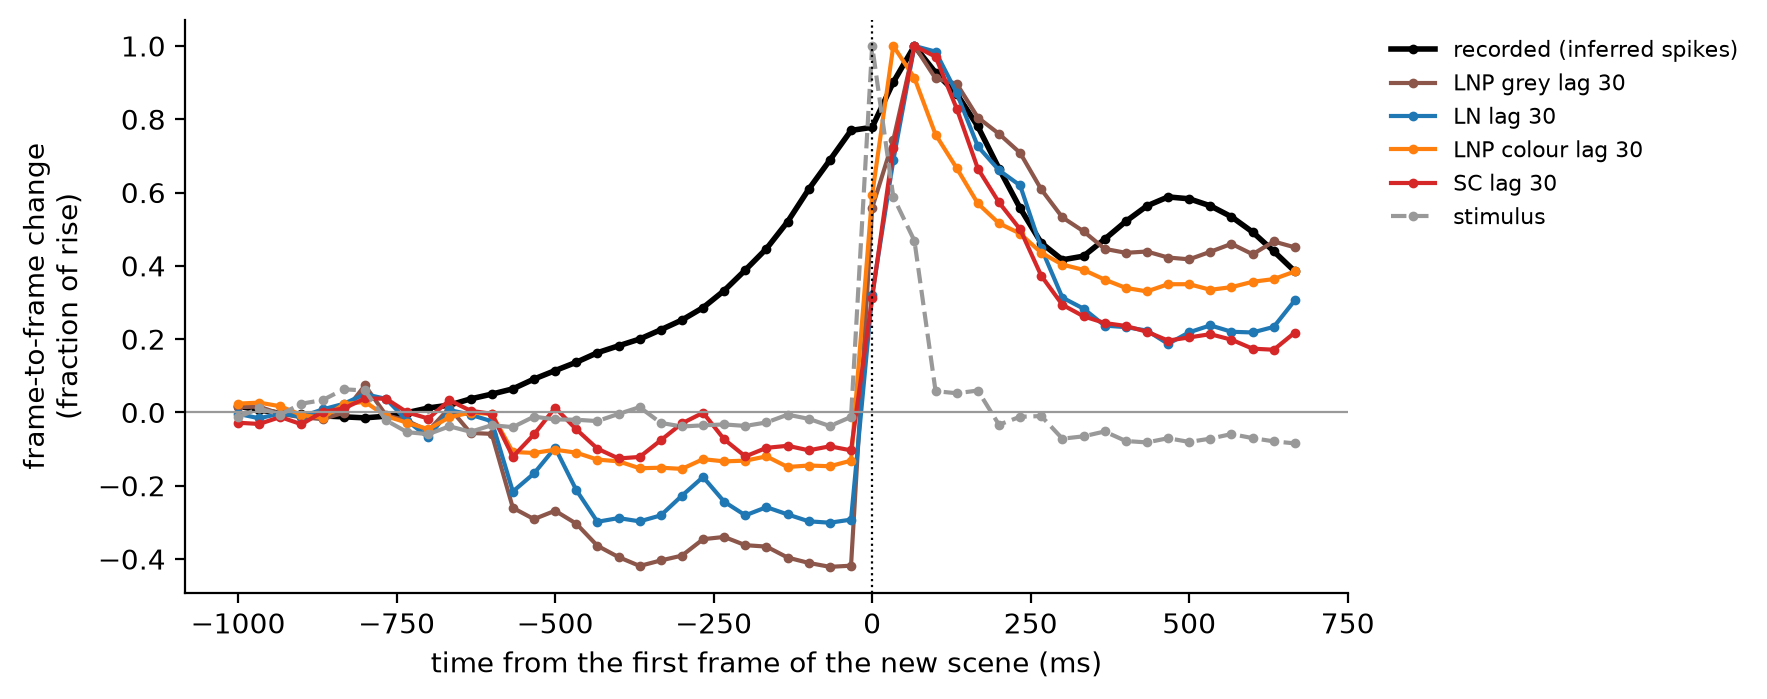

In [31]:
WINDOW = np.arange(-30, 21)  # frames from the cut
BASELINE = WINDOW <= -20

# Change of the stimulus into each frame, and the cuts: the first jump within a few frames of each clip boundary
test_stimulus = np.asarray(movies_dict.test_dict["test"])  # (channels, time, height, width)
stimulus_change = np.abs(np.diff(test_stimulus, axis=1, prepend=np.nan)).mean(axis=(0, 2, 3))
cuts = []
for boundary in range(CLIP_LENGTH, test_stimulus.shape[1], CLIP_LENGTH):
    jumps = [frame for frame in range(boundary - 5, boundary + 3) if stimulus_change[frame] > 0.5]
    if jumps:
        cuts.append(jumps[0])
print(f"cuts at frames {cuts} (clip boundaries {list(range(CLIP_LENGTH, test_stimulus.shape[1], CLIP_LENGTH))})")
lag = metrics["lag"].iloc[0]
assert all(cut + WINDOW[0] - 1 >= lag for cut in cuts), "window reaches into the cut-off start"


def cut_aligned_change(traces: dict[str, np.ndarray]) -> np.ndarray:
    # traces: session -> (time, neurons) over the whole test movie, NaN where missing. Mean |x(t) - x(t-1)| of the
    # z-scored traces around each cut, over cells and cuts
    windows = []
    for trace in traces.values():
        z = (trace - np.nanmean(trace, axis=0)) / (np.nanstd(trace, axis=0) + 1e-9)
        change = np.abs(np.diff(z, axis=0, prepend=np.nan))
        windows += [change[cut + WINDOW] for cut in cuts if cut + WINDOW[-1] < len(trace)]
    return np.nanmean(np.concatenate(windows, axis=1), axis=1)


def padded(prediction: np.ndarray) -> np.ndarray:
    return np.concatenate([np.full((lag, prediction.shape[1]), np.nan), prediction])


recorded = {s: final_responses[s].test_response.T.copy() for s in sessions}
for trace in recorded.values():
    trace[:lag] = np.nan
cut_curves = {"recorded (inferred spikes)": (cut_aligned_change(recorded), {"color": "k", "lw": 2})}
for label in TABLE:
    cut_curves[label] = (
        cut_aligned_change({s: padded(predictions[label][s]) for s in sessions}),
        {"color": PALETTE[label]},
    )
cut_curves["stimulus"] = (
    np.mean([stimulus_change[cut + WINDOW] for cut in cuts], axis=0),
    {"color": "0.6", "ls": "--"},
)

fig, ax = plt.subplots(figsize=(9, 3.6))
for label, (curve, style) in cut_curves.items():
    baseline = curve[BASELINE].mean()
    ax.plot(
        WINDOW * 1000 / FRAME_RATE_HZ,
        (curve - baseline) / (curve.max() - baseline),
        marker="o",
        ms=2.5,
        label=label,
        **style,
    )
ax.axvline(0, color="k", lw=0.8, ls=":")
ax.axhline(0, color="0.6", lw=0.8)
ax.set(xlabel="time from the first frame of the new scene (ms)", ylabel="frame-to-frame change\n(fraction of rise)")
ax.legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.02, 1), frameon=False)
sns.despine(fig=fig)
fig.tight_layout()

## Trained on calcium instead

The lag-30 grey LNP trained on the inferred spikes and on the calcium traces, with the same initialisation (uniform:
every frame starts at the same weight) and no temporal smoothness: where each cell's temporal filter peaks, and the
mean temporal filter per type. The spike-trained model is scored on the Table 2 targets; the calcium-trained one on
its own (calcium) test responses, which is not comparable.

,peak on current frame,median peak (ms before response),median test corr (reliable cells),scored on
trained on spikes,0.736323,0.0,0.388298,Table 2 targets
trained on calcium,0.215331,300.0,0.517713,own (calcium) responses


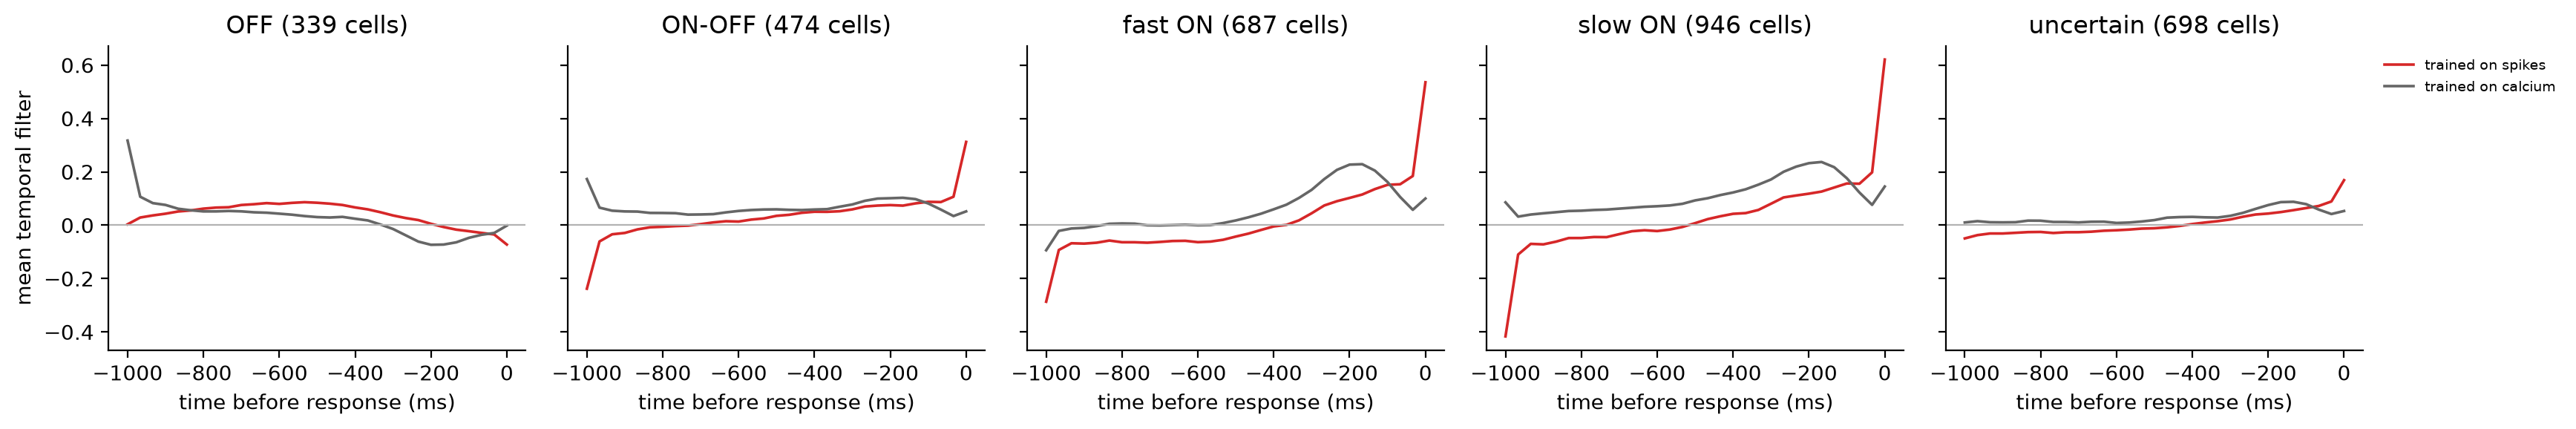

In [32]:
target_rows, target_curves = {}, {}
for (label, model), colour in zip(target_lnps.items(), ["C3", "0.4"]):
    temporal = np.concatenate(
        [
            np.stack([lnp_filter_factors(model.readout[s], n)[1] for n in range(model.readout[s].number_of_neurons())])
            for s in sessions
        ]
    )
    frames_before = temporal.shape[1] - 1 - np.abs(temporal).argmax(axis=1)
    if label == "spikes":
        correlations = test_metrics(model)[0]["correlation"].to_numpy()
    else:
        correlations = np.concatenate(
            [torch.as_tensor(model.data_info["pretrained_performance"][s]).cpu().numpy() for s in sessions]
        )
    target_rows[f"trained on {label}"] = {
        "peak on current frame": np.mean(frames_before == 0),
        "median peak (ms before response)": np.median(frames_before) * 1000 / FRAME_RATE_HZ,
        "median test corr (reliable cells)": np.median(correlations[reliable_order]),
        "scored on": "Table 2 targets" if label == "spikes" else "own (calcium) responses",
    }
    target_curves[f"trained on {label}"] = (temporal, {"color": colour})
display(pd.DataFrame(target_rows).T)
plot_mean_temporal_filters(target_curves);

**Why the newest frames carry so much weight.**

- **Where the filters peak:**
  - Without the temporal penalty, the filters peak on the current frame in 22% (LN) and 39% (SC) of the cells; the
    LNPs in 23% (colour) and 12.5% (grey).
  - With the penalty, the LN and SC filters most often peak one frame earlier (33 ms) instead. The penalty's zero padding keeps
    them off the current frame, but the current-frame tap is still a median 0.6 of the peak.
- **The responses lead the stimulus:**
  - Around the chirp's light steps, the inferred spikes start rising 300-400 ms before the step. The calcium signal
    they are inferred from rises only after it.
  - The same is visible in the prediction traces: the recorded responses often start changing before the scene cuts
    (dotted lines).
  - Averaged over all cells and the three cuts of the test movie (frames 150, 298 and 450; there is no cut at 600), the
    recorded response starts changing about 600 ms before the cut and is at about 80% of its rise when the new scene
    appears.
  - Every model's prediction stays at or below its earlier level until the first frame of the new scene. It drops
    slightly below in the last half second, as the stimulus changes less just before these cuts. It then jumps
    immediately.
  - A causal model cannot anticipate the stimulus, so the best it can do is put weight on the newest frames.
- **Trained on calcium:**
  - The same LNP trained on the calcium traces peaks on the current frame in 22% of cells, against 74% when trained on
    the spikes. Its median peak is 300 ms back.
  - For the ON types, its type means peak about 200 ms back, while those of the spike-trained model peak on the current
    frame.

So much of the current-frame weight reflects the acausal spike inference, not a physiological latency. This holds for
every model fitted to these responses, the CNNs of Table 2 included.

# Selection on validation loss vs validation correlation

Every model above was selected on the validation Poisson loss. Here the four Table 2 models are compared with the same
models selected on the validation correlation: early stopping, the checkpoint and the learning-rate schedule follow
the validation correlation instead, everything else (seed, learning rate, the 30-epoch warm-up) is the same. Selecting
on the validation correlation optimises the validation version of the reported correlation, but not FEVe, which also
depends on the scale of the prediction.

In [33]:
add_models({f"{name} · val corr": spec for name, spec in VAL_CORR_MODELS.items()})
CRITERION_PAIRS = [(name, f"{name} · val corr") for name in TABLE if f"{name} · val corr" in models]
display(table2([label for pair in CRITERION_PAIRS for label in pair]))
difference_table([(a, b, f"{a}: val corr - val loss") for a, b in CRITERION_PAIRS])

/home/shash/PycharmProjects/open-retina/.venv/lib/python3.12/site-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'core' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['core'])`.
/home/shash/PycharmProjects/open-retina/.venv/lib/python3.12/site-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'readout' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['readout'])`.
/home/shash/PycharmProjects/open-retina/.venv/lib/python3.12/site-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'loss' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['loss'])`.


/home/shash/PycharmProjects/open-retina/.venv/lib/python3.12/site-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'core' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['core'])`.
/home/shash/PycharmProjects/open-retina/.venv/lib/python3.12/site-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'readout' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['readout'])`.
/home/shash/PycharmProjects/open-retina/.venv/lib/python3.12/site-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'loss' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['loss'])`.


models: ['LNP grey lag 30', 'LN lag 30', 'LNP colour lag 30', 'SC lag 30', 'LNP colour lag 0 (Table 2)', 'LNP grey lag 0', 'LN lag 0', 'SC lag 0', 'LN lag 30, no temporal penalty', 'SC lag 30, no temporal penalty', 'LNP grey lag 30 · val corr', 'LN lag 30 · val corr', 'LNP colour lag 30 · val corr', 'SC lag 30 · val corr']


,Avg,Indiv,FEVe
LNP grey lag 30,0.369,0.295 ± 0.017,0.196
LNP grey lag 30 · val corr,0.370,0.296 ± 0.017,0.196
LN lag 30,0.394,0.314 ± 0.016,0.205
LN lag 30 · val corr,0.400,0.318 ± 0.016,0.213
LNP colour lag 30,0.440,0.352 ± 0.017,0.242
LNP colour lag 30 · val corr,0.440,0.352 ± 0.017,0.241
SC lag 30,0.460,0.367 ± 0.015,0.288
SC lag 30 · val corr,0.448,0.357 ± 0.015,0.275


,Δ FEVe,Δ Avg,cells higher (FEVe),cells lower (FEVe)
comparison,,,,
LNP grey lag 30: val corr - val loss,"-0.000 [-0.002, +0.001]","+0.001 [+0.000, +0.003]",0.366,0.359
LN lag 30: val corr - val loss,"+0.008 [+0.006, +0.010]","+0.006 [+0.005, +0.007]",0.474,0.261
LNP colour lag 30: val corr - val loss,"-0.001 [-0.003, +0.002]","-0.000 [-0.002, +0.002]",0.375,0.358
SC lag 30: val corr - val loss,"-0.013 [-0.015, -0.011]","-0.013 [-0.014, -0.011]",0.247,0.593


Cell by cell (reliable cells), the FEVe of each model selected on validation loss (x) and on validation correlation
(y); the title gives the mean difference with its 95% confidence interval. Below, the same with the cells coloured by
their functional type.

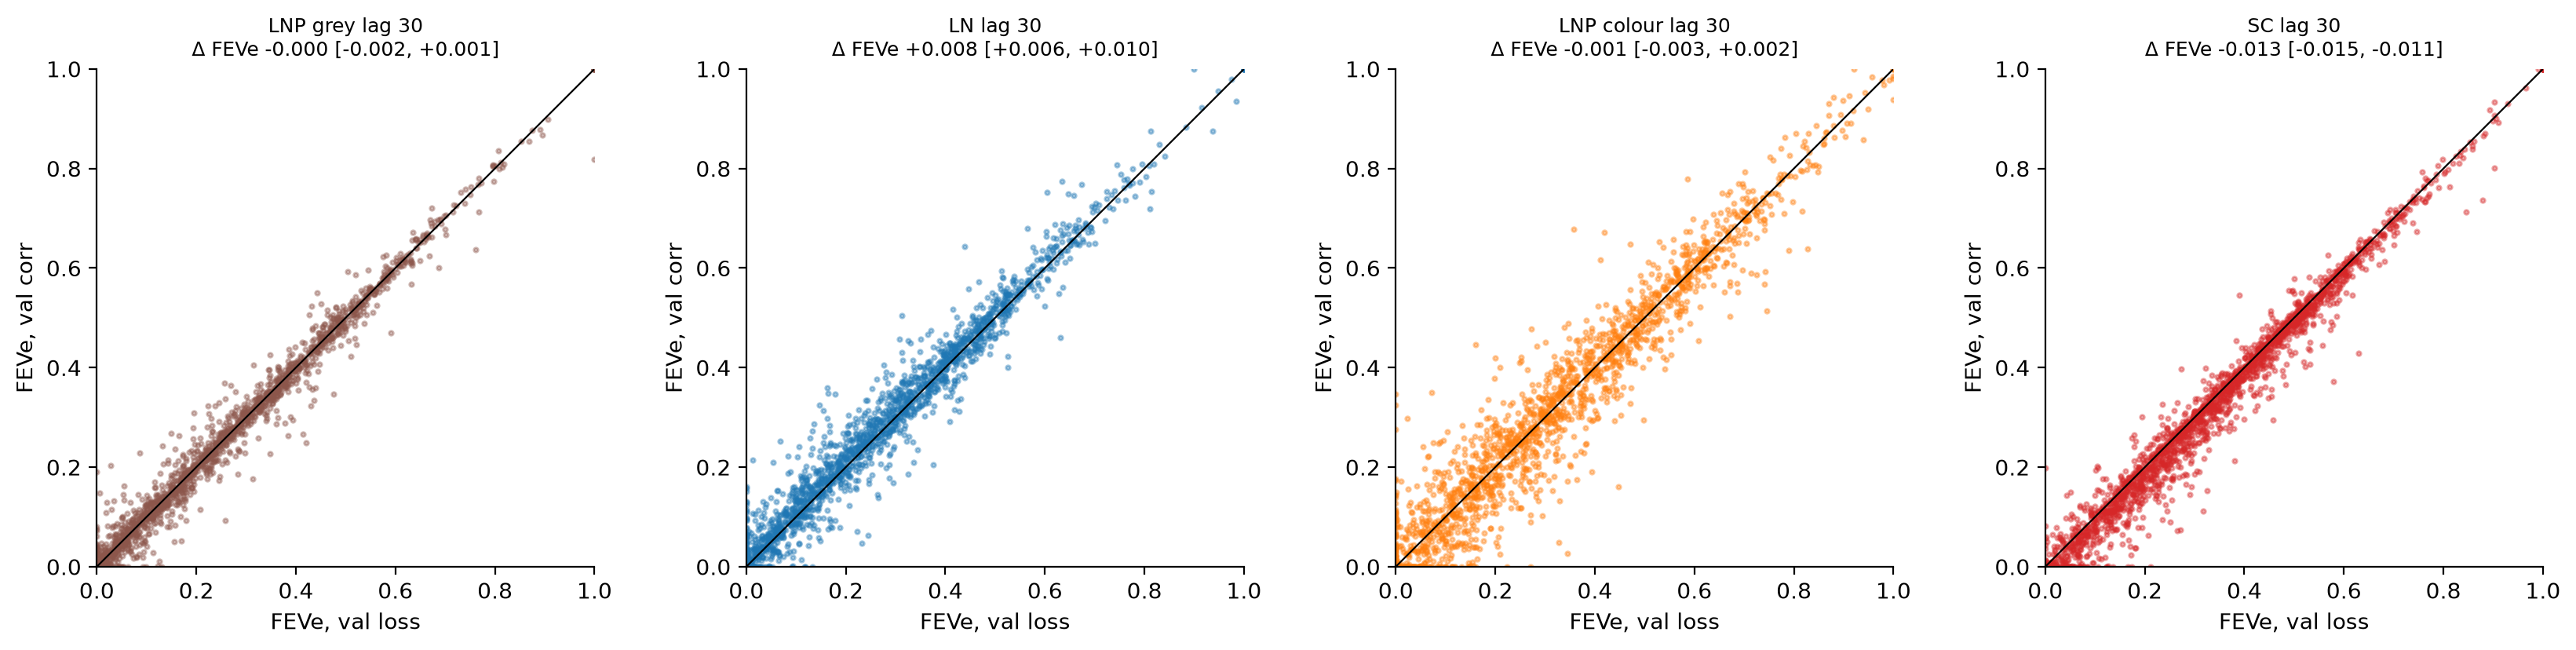

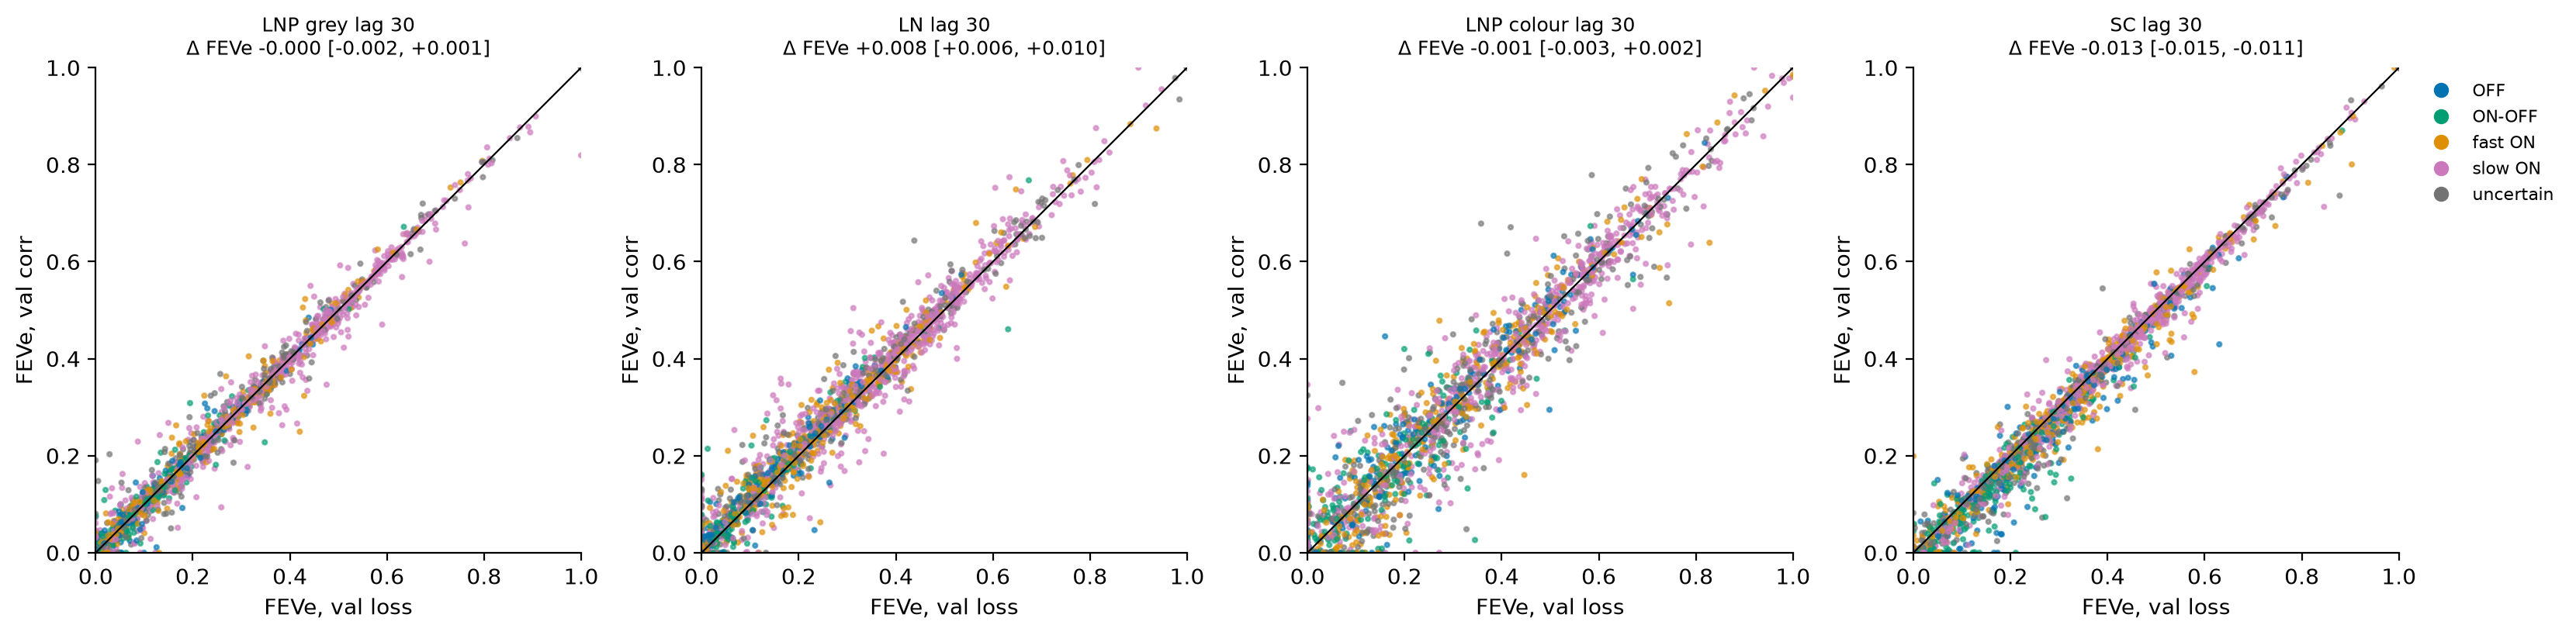

In [34]:
def plot_criterion_scatter(colour_by_type: bool = False) -> None:
    reliable = metrics[metrics["reliable"]]
    fig, axes = plt.subplots(ncols=len(CRITERION_PAIRS), figsize=(3.8 * len(CRITERION_PAIRS) + 1.5, 4), squeeze=False)
    for ax, (a, b) in zip(axes[0], CRITERION_PAIRS):
        wide = (
            reliable[reliable["model"].isin([a, b])]
            .pivot_table(index=["session", "neuron", "group_class"], columns="model", values="feve", observed=True)
            .reset_index()
        )
        if colour_by_type:
            # In random order, so that no type is drawn over the others
            shuffled = wide.sample(frac=1, random_state=0)
            colours = shuffled["group_class"].astype(str).map(TYPE_COLOURS)
            ax.scatter(shuffled[a], shuffled[b], s=4, alpha=0.6, c=colours.to_list(), rasterized=True)
        else:
            ax.scatter(wide[a], wide[b], s=4, alpha=0.4, color=PALETTE[a], rasterized=True)
        ax.plot([0, 1], [0, 1], color="k", lw=0.8)
        mean, low, high = paired_difference(a, b, "feve")
        ax.set(xlabel="FEVe, val loss", ylabel="FEVe, val corr", xlim=(0, 1), ylim=(0, 1), aspect="equal")
        ax.set_title(f"{a}\nΔ FEVe {mean:+.3f} [{low:+.3f}, {high:+.3f}]", fontsize=9)
    if colour_by_type:
        handles = [
            matplotlib.lines.Line2D([], [], ls="", marker="o", color=colour, label=group_class)
            for group_class, colour in TYPE_COLOURS.items()
        ]
        axes[0, -1].legend(handles=handles, fontsize=8, loc="upper left", bbox_to_anchor=(1.02, 1), frameon=False)
    sns.despine(fig=fig)
    fig.tight_layout()


plot_criterion_scatter()
plot_criterion_scatter(colour_by_type=True)

**What the criterion changes.**
- **LNPs:** the criterion makes no difference. Δ FEVe is -0.000 (grey) and -0.001 (colour), and the cells lie on the
  diagonal.
- **LN:** selecting on validation correlation is slightly better, FEVe +0.008 [+0.006, +0.010].
- **SC:** it is worse, FEVe -0.013 [-0.015, -0.011], with 59% of cells lower. The cells lie a little below the diagonal
  over most of the FEVe range, not only at either end.

The criterion only changes which epoch is kept and when the learning rate drops, and the runs part once their schedules
do. Correlation-based selection therefore does not systematically raise either measure here, even the correlation it
selects on: SC loses 0.013 in Avg as well.

The ranking of the four models is the same under both criteria. With validation-correlation selection, SC's lead over
the colour LNP shrinks to FEVe 0.275 vs 0.241 (Avg 0.448 vs 0.440). Like everything else here, these are single seeds.
The seed section shows that SC varies by up to 0.014 in FEVe from seed to seed, as much as the effect of the criterion.